# Factory Reallocation & Shipping Optimization Recommendation System

### Nassau Candy Distributor

**Project Objective:**  
Develop a decision-intelligence system that predicts shipping lead time,
simulates alternative factory assignments, and recommends product-factory
configurations that balance shipping efficiency and profitability.

### Project Workflow

1. Data Understanding & Cleaning
2. Exploratory Data Analysis
3. Feature Engineering
4. Machine Learning
5. Scenario Simulation
6. Factory Optimization
7. Recommendation Generation
8. Streamlit Dashboard


# Import required libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


## load dataset

In [2]:
df = pd.read_csv("../data/Nassau_Candy_Distributor.csv")
print(df.shape)

df.head()

(10194, 18)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,Division,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost
0,1,US-2021-103800-CHO-MIL-31000,03-01-2024,30-06-2026,Standard Class,103800,United States,Houston,Texas,77095,Chocolate,Interior,CHO-MIL-31000,Wonka Bar - Milk Chocolate,6.50,2,4.22,2.28
1,2,US-2021-112326-CHO-TRI-54000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,7.50,2,4.90,2.60
2,3,US-2021-112326-CHO-NUT-13000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,10.47,3,7.47,3.00
3,4,US-2021-112326-CHO-SCR-58000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30
4,5,US-2021-141817-CHO-TRI-54000,05-01-2024,05-07-2026,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,Chocolate,Atlantic,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,11.25,3,7.35,3.90


## EDA

In [3]:
print(df.columns)
df.isnull().sum()


Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Country/Region', 'City', 'State/Province',
       'Postal Code', 'Division', 'Region', 'Product ID', 'Product Name',
       'Sales', 'Units', 'Gross Profit', 'Cost'],
      dtype='object')


Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Country/Region    0
City              0
State/Province    0
Postal Code       0
Division          0
Region            0
Product ID        0
Product Name      0
Sales             0
Units             0
Gross Profit      0
Cost              0
dtype: int64

In [4]:
df.dtypes

Row ID              int64
Order ID           object
Order Date         object
Ship Date          object
Ship Mode          object
Customer ID         int64
Country/Region     object
City               object
State/Province     object
Postal Code        object
Division           object
Region             object
Product ID         object
Product Name       object
Sales             float64
Units               int64
Gross Profit      float64
Cost              float64
dtype: object

In [5]:
print("order Date samples")
print(df["Order Date"].head(5))

print("\nShip Date samples:")
print(df["Ship Date"].head(5))

order Date samples
0    03-01-2024
1    04-01-2024
2    04-01-2024
3    04-01-2024
4    05-01-2024
Name: Order Date, dtype: object

Ship Date samples:
0    30-06-2026
1    01-07-2026
2    01-07-2026
3    01-07-2026
4    05-07-2026
Name: Ship Date, dtype: object


In [6]:
print("Order Date Unique years")
print(df["Order Date"].str[-4:].value_counts().sort_index())
print("\n Ship Date unique years")
print(df["Ship Date"].str[-4:].value_counts().sort_index())

Order Date Unique years
Order Date
2024    4181
2025    6013
Name: count, dtype: int64

 Ship Date unique years
Ship Date
2026     711
2027    2089
2028    2367
2029    2899
2030    2128
Name: count, dtype: int64


In [7]:
df[["Order Date","Ship Date"]].head(10)

,Order Date,Ship Date
0,03-01-2024,30-06-2026
1,04-01-2024,01-07-2026
2,04-01-2024,01-07-2026
3,04-01-2024,01-07-2026
4,05-01-2024,05-07-2026
5,06-01-2024,03-07-2026
6,06-01-2024,03-07-2026
7,06-01-2024,30-06-2026
8,06-01-2024,03-07-2026
9,06-01-2024,03-07-2026


In [8]:
order_dates=pd.to_datetime(df["Order Date"],format="%d-%m-%Y")
ship_dates=pd.to_datetime(df["Ship Date"],format="%d-%m-%Y")
raw_difference=(ship_dates-order_dates).dt.days
raw_difference.describe()

count    10194.000000
mean      1320.841868
std        262.444892
min        904.000000
25%       1271.000000
50%       1274.000000
75%       1638.000000
max       1642.000000
dtype: float64

In [9]:
date_check=pd.DataFrame({
    "order dates":order_dates,
    "ship dates":ship_dates,
    "Difference Days":raw_difference
})
date_check.head(10)

,order dates,ship dates,Difference Days
0,2024-01-03,2026-06-30,909
1,2024-01-04,2026-07-01,909
2,2024-01-04,2026-07-01,909
3,2024-01-04,2026-07-01,909
4,2024-01-05,2026-07-05,912
5,2024-01-06,2026-07-03,909
6,2024-01-06,2026-07-03,909
7,2024-01-06,2026-06-30,906
8,2024-01-06,2026-07-03,909
9,2024-01-06,2026-07-03,909


In [10]:
date_check["Difference Days"].value_counts().sort_index()

Difference Days
904       89
905       40
906      289
907      176
908      591
909      519
910      207
911      134
912        4
915        2
1269     258
1270     156
1271     610
1272     456
1273    1326
1274    1035
1275     612
1276     293
1277      18
1634       3
1635     179
1636     190
1637     449
1638     411
1639     896
1640     657
1641     397
1642     197
Name: count, dtype: int64

In [11]:
print("Difference between 900 and 1000 days:")
print(((raw_difference >= 900) & (raw_difference < 1000)).sum())

print("\nDifference between 1200 and 1300 days:")
print(((raw_difference >= 1200) & (raw_difference < 1300)).sum())

print("\nDifference between 1600 and 1700 days:")
print(((raw_difference >= 1600) & (raw_difference < 1700)).sum())

Difference between 900 and 1000 days:
2051

Difference between 1200 and 1300 days:
4764

Difference between 1600 and 1700 days:
3379


In [12]:
date_check["Order Year"] = date_check["order dates"].dt.year
date_check["Ship Year"] = date_check["ship dates"].dt.year

pd.crosstab(
    date_check["Order Year"],
    date_check["Ship Year"]
)

Ship Year,2026,2027,2028,2029,2030
Order Year,,,,,
2024,711,2089,1381,0,0
2025,0,0,986,2899,2128


In [13]:
pd.crosstab(
    df["Ship Mode"],
    date_check["Ship Year"]
)

Ship Year,2026,2027,2028,2029,2030
Ship Mode,,,,,
First Class,91,314,327,476,340
Same Day,30,86,163,138,130
Second Class,139,380,486,547,427
Standard Class,451,1309,1391,1738,1231


In [14]:
df[["Order ID", "Order Date", "Ship Date", "Ship Mode"]].head(10)


,Order ID,Order Date,Ship Date,Ship Mode
0,US-2021-103800-CHO-MIL-31000,03-01-2024,30-06-2026,Standard Class
1,US-2021-112326-CHO-TRI-54000,04-01-2024,01-07-2026,Standard Class
2,US-2021-112326-CHO-NUT-13000,04-01-2024,01-07-2026,Standard Class
3,US-2021-112326-CHO-SCR-58000,04-01-2024,01-07-2026,Standard Class
4,US-2021-141817-CHO-TRI-54000,05-01-2024,05-07-2026,Standard Class
5,US-2021-167199-CHO-SCR-58000,06-01-2024,03-07-2026,Standard Class
6,US-2021-167199-CHO-TRI-54000,06-01-2024,03-07-2026,Standard Class
7,US-2021-106054-CHO-MIL-31000,06-01-2024,30-06-2026,First Class
8,US-2021-167199-CHO-NUT-13000,06-01-2024,03-07-2026,Standard Class
9,US-2021-167199-CHO-MIL-31000,06-01-2024,03-07-2026,Standard Class


In [15]:
df[["Order ID", "Order Date"]].head(20)
df["Order ID"].str.split("-").str[1].value_counts().sort_index()

Order ID
2021    2051
2022    2130
2023    2634
2024    3379
Name: count, dtype: int64

In [16]:
id_year=df["Order ID"].str.split("-").str[1].astype(int)
pd.crosstab(
    id_year,
    date_check["Order Year"]
)

Order Year,2024,2025
Order ID,,
2021,2051,0
2022,2130,0
2023,0,2634
2024,0,3379


In [17]:
# Convert the two date columns
order_dates = pd.to_datetime(
    df["Order Date"],
    format="%d-%m-%Y"
)

ship_dates = pd.to_datetime(
    df["Ship Date"],
    format="%d-%m-%Y"
)

# Extract the year from Order ID
id_year = df["Order ID"].str.split("-").str[1].astype(int)

# Extract years from the actual dates
order_year = order_dates.dt.year
ship_year = ship_dates.dt.year

# Compare Order ID year with Ship Date year
pd.crosstab(
    id_year,
    ship_year
)

Ship Date,2026,2027,2028,2029,2030
Order ID,,,,,
2021,711,1340,0,0,0
2022,0,749,1381,0,0
2023,0,0,986,1648,0
2024,0,0,0,1251,2128


In [18]:
date_check = pd.DataFrame({
    "Order Date": order_dates,
    "Ship Date": ship_dates
})

date_check["Order Month"] = date_check["Order Date"].dt.month
date_check["Order Day"] = date_check["Order Date"].dt.day

date_check["Ship Month"] = date_check["Ship Date"].dt.month
date_check["Ship Day"] = date_check["Ship Date"].dt.day

date_check.head(20)

,Order Date,Ship Date,Order Month,Order Day,Ship Month,Ship Day
0,2024-01-03,2026-06-30,1,3,6,30
1,2024-01-04,2026-07-01,1,4,7,1
2,2024-01-04,2026-07-01,1,4,7,1
3,2024-01-04,2026-07-01,1,4,7,1
4,2024-01-05,2026-07-05,1,5,7,5
5,2024-01-06,2026-07-03,1,6,7,3
6,2024-01-06,2026-07-03,1,6,7,3
7,2024-01-06,2026-06-30,1,6,6,30
8,2024-01-06,2026-07-03,1,6,7,3
9,2024-01-06,2026-07-03,1,6,7,3


In [19]:
date_check["Month Difference"] = (
    date_check["Ship Month"] - date_check["Order Month"]
)

date_check["Month Difference"].value_counts().sort_index()

Month Difference
-7     930
-6    5567
 5     739
 6    2958
Name: count, dtype: int64

In [20]:
date_check["Order Month-Day"] = (
    date_check["Order Date"].dt.strftime("%m-%d")
)

date_check["Ship Month-Day"] = (
    date_check["Ship Date"].dt.strftime("%m-%d")
)

date_check[[
    "Order Date",
    "Ship Date",
    "Order Month-Day",
    "Ship Month-Day"
]].head(10)

,Order Date,Ship Date,Order Month-Day,Ship Month-Day
0,2024-01-03,2026-06-30,01-03,06-30
1,2024-01-04,2026-07-01,01-04,07-01
2,2024-01-04,2026-07-01,01-04,07-01
3,2024-01-04,2026-07-01,01-04,07-01
4,2024-01-05,2026-07-05,01-05,07-05
5,2024-01-06,2026-07-03,01-06,07-03
6,2024-01-06,2026-07-03,01-06,07-03
7,2024-01-06,2026-06-30,01-06,06-30
8,2024-01-06,2026-07-03,01-06,07-03
9,2024-01-06,2026-07-03,01-06,07-03


In [21]:
df[[
    "Order ID",
    "Order Date",
    "Ship Date",
    "Ship Mode"
]].head(20)

,Order ID,Order Date,Ship Date,Ship Mode
0,US-2021-103800-CHO-MIL-31000,03-01-2024,30-06-2026,Standard Class
1,US-2021-112326-CHO-TRI-54000,04-01-2024,01-07-2026,Standard Class
2,US-2021-112326-CHO-NUT-13000,04-01-2024,01-07-2026,Standard Class
3,US-2021-112326-CHO-SCR-58000,04-01-2024,01-07-2026,Standard Class
4,US-2021-141817-CHO-TRI-54000,05-01-2024,05-07-2026,Standard Class
5,US-2021-167199-CHO-SCR-58000,06-01-2024,03-07-2026,Standard Class
6,US-2021-167199-CHO-TRI-54000,06-01-2024,03-07-2026,Standard Class
7,US-2021-106054-CHO-MIL-31000,06-01-2024,30-06-2026,First Class
8,US-2021-167199-CHO-NUT-13000,06-01-2024,03-07-2026,Standard Class
9,US-2021-167199-CHO-MIL-31000,06-01-2024,03-07-2026,Standard Class


In [22]:
ship_mode_check=pd.DataFrame({
    "Ship Mode": df["Ship Mode"],
    "Date Difference": raw_difference
})

ship_mode_check.groupby("Ship Mode")["Date Difference"].describe()

,count,mean,std,min,25%,50%,75%,max
Ship Mode,,,,,,,,
First Class,1548.0,1338.275840,265.632140,905.0,1270.0,1272.0,1637.0,1638.0
Same Day,547.0,1333.442413,253.813374,904.0,1269.0,1269.0,1635.0,1636.0
Second Class,1979.0,1323.845376,261.813569,906.0,1271.0,1273.0,1637.0,1640.0
Standard Class,6120.0,1314.334641,262.400116,908.0,1273.0,1274.0,1639.0,1642.0


In [23]:
print("Ship Modes:")
print(df["Ship Mode"].value_counts())

print("\nDivisions:")
print(df["Division"].value_counts())

print("\nRegions:")
print(df["Region"].value_counts())

Ship Modes:
Ship Mode
Standard Class    6120
Second Class      1979
First Class       1548
Same Day           547
Name: count, dtype: int64

Divisions:
Division
Chocolate    9844
Other         310
Sugar          40
Name: count, dtype: int64

Regions:
Region
Pacific     3253
Atlantic    2986
Interior    2335
Gulf        1620
Name: count, dtype: int64


In [24]:
print("Number of unique products:", df["Product Name"].nunique())

print("\nProduct counts:")
print(df["Product Name"].value_counts())

Number of unique products: 15

Product counts:
Product Name
Wonka Bar - Milk Chocolate           2137
Wonka Bar -Scrumdiddlyumptious       2064
Wonka Bar - Triple Dazzle Caramel    2015
Wonka Bar - Fudge Mallows            1818
Wonka Bar - Nutty Crunch Surprise    1810
Wonka Gum                             120
Kazookles                              96
Lickable Wallpaper                     94
Laffy Taffy                            10
SweeTARTS                              10
Fizzy Lifting Drinks                    6
Nerds                                   4
Hair Toffee                             4
Everlasting Gobstopper                  3
Fun Dip                                 3
Name: count, dtype: int64


In [25]:
product_division_check=(df.groupby("Product Name")["Division"]
                                    .unique().sort_index)
product_division_check

<bound method Series.sort_index of Product Name
Everlasting Gobstopper                   [Sugar]
Fizzy Lifting Drinks                     [Sugar]
Fun Dip                                  [Sugar]
Hair Toffee                              [Sugar]
Kazookles                                [Other]
Laffy Taffy                              [Sugar]
Lickable Wallpaper                       [Other]
Nerds                                    [Sugar]
SweeTARTS                                [Sugar]
Wonka Bar - Fudge Mallows            [Chocolate]
Wonka Bar - Milk Chocolate           [Chocolate]
Wonka Bar - Nutty Crunch Surprise    [Chocolate]
Wonka Bar - Triple Dazzle Caramel    [Chocolate]
Wonka Bar -Scrumdiddlyumptious       [Chocolate]
Wonka Gum                                [Other]
Name: Division, dtype: object>

In [26]:
division_product_check=(df.groupby("Division")["Product Name"].nunique()
                        .sort_values(ascending=False))
division_product_check

Division
Sugar        7
Chocolate    5
Other        3
Name: Product Name, dtype: int64

In [27]:
df[["Sales","Units","Gross Profit","Cost"]].describe()

,Sales,Units,Gross Profit,Cost
count,10194.000000,10194.000000,10194.000000,10194.000000
mean,13.908537,3.791838,9.166451,4.742087
std,11.341020,2.228317,6.643740,5.061647
min,1.250000,1.000000,0.250000,0.600000
25%,7.200000,2.000000,4.900000,2.400000
50%,10.800000,3.000000,7.470000,3.600000
75%,18.000000,5.000000,12.250000,5.700000
max,260.000000,14.000000,130.000000,130.000000


In [28]:
df[["Sales", "Units", "Gross Profit", "Cost"]].skew()

Sales           6.456053
Units           1.268633
Gross Profit    4.026533
Cost            9.674963
dtype: float64

In [29]:
order_year=df["Order ID"].str.split("-").str[1]
print(order_year.value_counts().sort_index())

Order ID
2021    2051
2022    2130
2023    2634
2024    3379
Name: count, dtype: int64


In [30]:
pd.crosstab(
    order_year,
    df["Ship Mode"]
)

Ship Mode,First Class,Same Day,Second Class,Standard Class
Order ID,,,,
2021,293,92,388,1278
2022,289,109,425,1307
2023,390,158,500,1586
2024,576,188,666,1949


In [31]:
print(df.columns)
print("\nShape:",df.shape)

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Country/Region', 'City', 'State/Province',
       'Postal Code', 'Division', 'Region', 'Product ID', 'Product Name',
       'Sales', 'Units', 'Gross Profit', 'Cost'],
      dtype='object')

Shape: (10194, 18)


In [32]:
df["Order Date"]=pd.to_datetime(
    df["Order Date"],format="%d-%m-%Y"
)
df["Order Year"]=df["Order Date"].dt.year
df["Order Month"]=df["Order Date"].dt.month
df["Order Day"]=df["Order Date"].dt.day
df["Order DayOfWeek"]=df["Order Date"].dt.dayofweek

print(df[[
    "Order Date",
    "Order Year",
    "Order Month",
    "Order Day",
    "Order DayOfWeek"
]].head())

  Order Date  Order Year  Order Month  Order Day  Order DayOfWeek
0 2024-01-03        2024            1          3                2
1 2024-01-04        2024            1          4                3
2 2024-01-04        2024            1          4                3
3 2024-01-04        2024            1          4                3
4 2024-01-05        2024            1          5                4


In [33]:
df.groupby("Ship Mode")[["Order Date", "Ship Date"]].agg(
    ["min", "max"]
)

Order Date              Ship Date            
                      min        max         min         max
Ship Mode                                                   
First Class    2024-01-06 2025-12-31  01-01-2030  31-12-2029
Same Day       2024-02-18 2025-12-30  01-02-2029  31-12-2028
Second Class   2024-01-02 2025-12-29  01-02-2027  31-12-2028
Standard Class 2024-01-02 2025-12-31  01-01-2027  31-12-2029

In [34]:
df_clean = df.copy()

# Remove rows with invalid business values
df_clean = df_clean[
    (df_clean["Sales"] > 0) &
    (df_clean["Cost"] > 0) &
    (df_clean["Units"] > 0)
].copy()

# Calculate useful profitability features
df_clean["Gross Margin %"] = (
    df_clean["Gross Profit"] / df_clean["Sales"]
) * 100

df_clean["Profit per Unit"] = (
    df_clean["Gross Profit"] / df_clean["Units"]
)

df_clean["Revenue per Unit"] = (
    df_clean["Sales"] / df_clean["Units"]
)

df_clean["Cost per Unit"] = (
    df_clean["Cost"] / df_clean["Units"]
)

df_clean["Cost Ratio %"] = (
    df_clean["Cost"] / df_clean["Sales"]
) * 100

print("Original rows:", len(df))
print("Clean rows:", len(df_clean))
print("Rows removed:", len(df) - len(df_clean))

Original rows: 10194
Clean rows: 10194
Rows removed: 0


In [35]:
# Extract the year encoded inside Order ID
df_clean["Order ID Year"]=(
    df_clean["Order ID"].str.split("-").str[1].astype(int)
)

# Calculate the raw difference between Ship Date and Order Date
df_clean["Raw Date Difference"]=(
    pd.to_datetime(df_clean["Ship Date"],format="%d-%m-%Y")
    -df_clean["Order Date"]
).dt.days

# Find the minimum raw difference for each Order ID year
year_baseline=(df_clean.groupby("Order ID Year")["Raw Date Difference"]
               .min())

# Remove the year-specific fixed offset
df_clean["Candidate Lead Time"] = (
    df_clean["Raw Date Difference"]
    - df_clean["Order ID Year"].map(year_baseline))


# Compare the resulting lead time with Ship Mode
lead_time_check = (
    df_clean
    .groupby("Ship Mode")["Candidate Lead Time"]
    .describe()
)

print("Year-specific baselines:")
print(year_baseline)

print("\nCandidate lead time by Ship Mode:")
print(lead_time_check)


Year-specific baselines:
Order ID Year
2021     904
2022    1269
2023    1269
2024    1634
Name: Raw Date Difference, dtype: int64

Candidate lead time by Ship Mode:
                 count      mean       std  min  25%  50%  75%   max
Ship Mode                                                           
First Class     1548.0  2.547804  0.887849  1.0  2.0  3.0  3.0   5.0
Same Day         547.0  0.383912  0.533457  0.0  0.0  0.0  1.0   2.0
Second Class    1979.0  3.572006  1.280342  1.0  2.0  3.0  5.0   6.0
Standard Class  6120.0  5.315850  1.128344  3.0  4.0  5.0  6.0  11.0


In [36]:
lead_time_year_check = (
    df_clean
    .groupby("Order ID Year")["Candidate Lead Time"]
    .describe()
)

print(lead_time_year_check)

                count      mean       std  min  25%  50%  75%   max
Order ID Year                                                      
2021           2051.0  4.065822  1.685246  0.0  3.0  4.0  5.0  11.0
2022           2130.0  4.074178  1.730597  0.0  3.0  4.0  5.0   8.0
2023           2634.0  3.952923  1.790612  0.0  3.0  4.0  5.0   7.0
2024           3379.0  4.831903  1.786281  0.0  4.0  5.0  6.0   8.0


In [37]:
# Use the reconstructed lead time as our ML target
df_clean["Lead Time"] = df_clean["Candidate Lead Time"]

# Check the target
print("Lead Time summary:")
print(df_clean["Lead Time"].describe())

print("\nUnique lead-time values:")
print(sorted(df_clean["Lead Time"].unique()))

Lead Time summary:
count    10194.000000
mean         4.292329
std          1.796933
min          0.000000
25%          3.000000
50%          4.000000
75%          5.000000
max         11.000000
Name: Lead Time, dtype: float64

Unique lead-time values:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(11)]


In [38]:
df

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,...,Product ID,Product Name,Sales,Units,Gross Profit,Cost,Order Year,Order Month,Order Day,Order DayOfWeek
0,1,US-2021-103800-CHO-MIL-31000,2024-01-03,30-06-2026,Standard Class,103800,United States,Houston,Texas,77095,...,CHO-MIL-31000,Wonka Bar - Milk Chocolate,6.50,2,4.22,2.28,2024,1,3,2
1,2,US-2021-112326-CHO-TRI-54000,2024-01-04,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,...,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,7.50,2,4.90,2.60,2024,1,4,3
2,3,US-2021-112326-CHO-NUT-13000,2024-01-04,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,...,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,10.47,3,7.47,3.00,2024,1,4,3
3,4,US-2021-112326-CHO-SCR-58000,2024-01-04,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,...,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30,2024,1,4,3
4,5,US-2021-141817-CHO-TRI-54000,2024-01-05,05-07-2026,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,...,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,11.25,3,7.35,3.90,2024,1,5,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10189,10190,US-2024-143259-CHO-MIL-31000,2025-12-30,26-06-2030,Standard Class,143259,United States,New York City,New York,10009,...,CHO-MIL-31000,Wonka Bar - Milk Chocolate,9.75,3,6.33,3.42,2025,12,30,1
10190,10191,US-2024-115427-CHO-NUT-13000,2025-12-30,26-06-2030,Standard Class,115427,United States,Fairfield,California,94533,...,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,6.98,2,4.98,2.00,2025,12,30,1
10191,10192,US-2024-156720-CHO-SCR-58000,2025-12-30,26-06-2030,Standard Class,156720,United States,Loveland,Colorado,80538,...,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30,2025,12,30,1
10192,10193,US-2024-143259-CHO-TRI-54000,2025-12-30,26-06-2030,Standard Class,143259,United States,New York City,New York,10009,...,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,26.25,7,17.15,9.10,2025,12,30,1


In [39]:
# Map each product to its current factory
factory_mapping = {
    "Wonka Bar - Nutty Crunch Surprise": "Lot's O' Nuts",
    "Wonka Bar - Fudge Mallows": "Lot's O' Nuts",
    "Wonka Bar -Scrumdiddlyumptious": "Lot's O' Nuts",
    "Wonka Bar - Milk Chocolate": "Wicked Choccy's",
    "Wonka Bar - Triple Dazzle Caramel": "Wicked Choccy's",
    "Laffy Taffy": "Sugar Shack",
    "SweeTARTS": "Sugar Shack",
    "Nerds": "Sugar Shack",
    "Fun Dip": "Sugar Shack",
    "Fizzy Lifting Drinks": "Sugar Shack",
    "Everlasting Gobstopper": "Secret Factory",
    "Hair Toffee": "The Other Factory",
    "Lickable Wallpaper": "Secret Factory",
    "Wonka Gum": "Secret Factory",
    "Kazookles": "The Other Factory"
}

df_clean["Current Factory"] = df_clean["Product Name"].map(factory_mapping)

print("Missing factory assignments:",
      df_clean["Current Factory"].isna().sum())

print("\nProducts by current factory:")
print(
    df_clean[["Product Name", "Current Factory"]]
    .drop_duplicates()
    .sort_values("Current Factory")
    .to_string(index=False)
)

Missing factory assignments: 0

Products by current factory:
                     Product Name   Current Factory
Wonka Bar - Nutty Crunch Surprise     Lot's O' Nuts
   Wonka Bar -Scrumdiddlyumptious     Lot's O' Nuts
        Wonka Bar - Fudge Mallows     Lot's O' Nuts
                        Wonka Gum    Secret Factory
               Lickable Wallpaper    Secret Factory
           Everlasting Gobstopper    Secret Factory
             Fizzy Lifting Drinks       Sugar Shack
                      Laffy Taffy       Sugar Shack
                        SweeTARTS       Sugar Shack
                            Nerds       Sugar Shack
                          Fun Dip       Sugar Shack
                        Kazookles The Other Factory
                      Hair Toffee The Other Factory
       Wonka Bar - Milk Chocolate   Wicked Choccy's
Wonka Bar - Triple Dazzle Caramel   Wicked Choccy's


In [40]:
factory_locations = pd.DataFrame({
    "Factory": [
        "Lot's O' Nuts",
        "Wicked Choccy's",
        "Sugar Shack",
        "Secret Factory",
        "The Other Factory"
    ],
    "Latitude": [
        32.881893,
        32.076176,
        48.119140,
        41.446333,
        35.117500
    ],
    "Longitude": [
        -111.768036,
        -81.088371,
        -96.181150,
        -90.565487,
        -89.971107
    ]
})

print(factory_locations)

             Factory   Latitude   Longitude
0      Lot's O' Nuts  32.881893 -111.768036
1    Wicked Choccy's  32.076176  -81.088371
2        Sugar Shack  48.119140  -96.181150
3     Secret Factory  41.446333  -90.565487
4  The Other Factory  35.117500  -89.971107


In [41]:
print("Number of unique postal codes:",
      df_clean["Postal Code"].nunique())

print("\nSample postal codes:")
print(df_clean["Postal Code"].drop_duplicates().head(20).to_list())

Number of unique postal codes: 654

Sample postal codes:
['77095', '60540', '19143', '42420', '30605', '90049', '77340', '78041', '22153', '19901', '94109', '29464', '43055', '71111', '19140', '30076', '19134', '97477', '85254', '72401']


In [42]:
zip_check = df_clean["Postal Code"].astype(str).str.strip()

print("5-digit ZIP codes:",
      zip_check.str.fullmatch(r"\d{5}").sum())

print("Invalid ZIP codes:",
      (~zip_check.str.fullmatch(r"\d{5}")).sum())

5-digit ZIP codes: 9545
Invalid ZIP codes: 649


In [43]:
invalid_zips=df_clean.loc[
    ~df_clean["Postal Code"].astype(str).str.strip().str.fullmatch("r\d{5}")
    ,"Postal Code"
]
invalid_zips

0        77095
1        60540
2        60540
3        60540
4        19143
         ...  
10189    10009
10190    94533
10191    80538
10192    10009
10193      C0A
Name: Postal Code, Length: 10194, dtype: object

In [44]:
invalid_zips.value_counts().head(30)

Postal Code
10035    263
10024    230
10009    229
94122    203
10011    193
94110    166
98105    165
19134    160
90049    151
98103    151
19140    150
94109    141
90045    140
90036    122
43229    120
90004    117
77041    117
19143    114
19120    113
98115    112
90008    109
60610    108
90032    108
60623    105
77095    104
60653    101
77070     91
32216     75
92105     74
31907     68
Name: count, dtype: int64

In [45]:
print("First ZIP:", repr(df_clean["Postal Code"].iloc[0]))
print("Second ZIP:", repr(df_clean["Postal Code"].iloc[1]))
print("Last ZIP:", repr(df_clean["Postal Code"].iloc[-1]))


First ZIP: '77095'
Second ZIP: '60540'
Last ZIP: 'C0A'


In [46]:
df["Postal Code"].unique()

array(['77095', '60540', '19143', '42420', '30605', '90049', '77340',
       '78041', '22153', '19901', '94109', '29464', '43055', '71111',
       '19140', '30076', '19134', '97477', '85254', '72401', '48185',
       '37167', '33180', 'M7A', '47905', '89115', '57701', '22304',
       '92037', '10024', '48234', '92691', '54302', '33710', '98105',
       '92025', '92024', '60441', '23320', '7036', '89031', '65203',
       '94521', '98103', '75220', '60653', '79424', '76017', '47374',
       '60098', '92553', '79907', '97504', '43229', '60126', '98115',
       '77036', '10035', '10009', '19120', '28403', '33063', '29203',
       '10701', '98198', '80219', '48073', '40475', '95661', 'T2C',
       '92646', '84321', '32216', '33614', '27604', '55044', '39212',
       '75217', '94110', '91505', '33801', '37918', '45011', '28806',
       '85705', '46368', '27405', '33445', '90036', '93727', '94122',
       '91767', '45503', '50315', '87105', '75023', '78521', '11561',
       '55124', '60610', 

In [47]:
country_counts = df_clean["Country/Region"].value_counts()

print(country_counts)

Country/Region
United States    9994
Canada            200
Name: count, dtype: int64


In [48]:
postal_country_check=(
    df_clean.groupby("Country/Region")["Postal Code"].nunique()
)
postal_country_check

Country/Region
Canada            23
United States    631
Name: Postal Code, dtype: int64

In [49]:
import pgeocode

id="c7k3p1"
us_geo = pgeocode.Nominatim("us")

zip_result = us_geo.query_postal_code("77095")

print(zip_result)

postal_code         77095
country_code           US
place_name        Houston
state_name          Texas
state_code             TX
county_name        Harris
county_code         201.0
community_name        NaN
community_code        NaN
latitude          29.8941
longitude        -95.6481
accuracy              4.0
Name: 0, dtype: object


In [50]:
us_postal_codes = (
    df_clean.loc[
        df_clean["Country/Region"] == "United States",
        "Postal Code"
    ]
    .astype(str)
    .str.strip()
    .unique()
)

print("Unique U.S. postal codes:", len(us_postal_codes))
print("First 10:", us_postal_codes[:10])

Unique U.S. postal codes: 631
First 10: ['77095' '60540' '19143' '42420' '30605' '90049' '77340' '78041' '22153'
 '19901']


In [51]:
us_geo = pgeocode.Nominatim("us")

us_lookup = us_geo.query_postal_code(us_postal_codes)

print("Rows returned:", len(us_lookup))
print("Missing latitude:", us_lookup["latitude"].isna().sum())
print("Missing longitude:", us_lookup["longitude"].isna().sum())

Rows returned: 631
Missing latitude: 52
Missing longitude: 52


In [52]:
missing_us_zips=us_lookup.loc[
    us_lookup["latitude"].isna(),
    "postal_code"
]
print("Unmatched U.S. postal codes:",len(missing_us_zips))
print(missing_us_zips.tolist())

Unmatched U.S. postal codes: 52
['7036', '2151', '6457', '1841', '2038', '3820', '8701', '6450', '7060', '7601', '6010', '4401', '6824', '1852', '7011', '2149', '3301', '2920', '7050', '2895', '1915', '2908', '8861', '1453', '6360', '6040', '7501', '4240', '1040', '8360', '2740', '2169', '7002', '2138', '5401', '7960', '7090', '8401', '7109', '1810', '6460', '2148', '6708', '2886', '7055', '1752', '8302', '6484', '7017', '3060', '8901', '6810']


In [53]:
test_zip = "7036"

print("Original:", test_zip)
print("With leading zero:", test_zip.zfill(5))

test_result = us_geo.query_postal_code(test_zip.zfill(5))

print("\nLookup result:")
print(test_result[[
    "postal_code",
    "place_name",
    "state_code",
    "latitude",
    "longitude"
]])

Original: 7036
With leading zero: 07036

Lookup result:
postal_code      07036
place_name      Linden
state_code          NJ
latitude       40.6354
longitude     -74.2556
Name: 0, dtype: object


In [54]:
df_clean["Postal Code Clean"]=(
    df_clean["Postal Code"].astype(str).str.strip()
)

us_mask=df_clean["Country/Region"]=="United States"

df_clean.loc[us_mask,"Postal Code Clean"]=(
    df_clean.loc[us_mask,"Postal Code Clean"].str.zfill(5)
)

print("Original Postal Code:",df_clean["Postal Code"].nunique())
print("Clean U.S Postal Codes:",df_clean.loc[us_mask,"Postal Code Clean"].nunique())

Original Postal Code: 654
Clean U.S Postal Codes: 631


In [55]:
test_postal_codes = df_clean.loc[
    df_clean["Country/Region"] == "United States",
    "Postal Code Clean"
].unique()[:10]

test_lookup = us_geo.query_postal_code(test_postal_codes)

print(test_lookup[[
    "postal_code",
    "place_name",
    "state_code",
    "latitude",
    "longitude"
]])

  postal_code    place_name state_code  latitude  longitude
0       77095       Houston         TX   29.8941   -95.6481
1       60540    Naperville         IL   41.7662   -88.1410
2       19143  Philadelphia         PA   39.9448   -75.2288
3       42420     Henderson         KY   37.8274   -87.5632
4       30605        Athens         GA   33.9321   -83.3525
5       90049   Los Angeles         CA   34.0660  -118.4740
6       77340    Huntsville         TX   30.6448   -95.5798
7       78041        Laredo         TX   27.5569   -99.4907
8       22153   Springfield         VA   38.7449   -77.2370
9       19901         Dover         DE   39.1564   -75.4955


In [56]:
us_postal_codes_clean = (
    df_clean.loc[
        df_clean["Country/Region"] == "United States",
        "Postal Code Clean"
    ]
    .dropna()
    .unique()
)

print("Unique U.S. postal codes to geocode:", len(us_postal_codes_clean))

Unique U.S. postal codes to geocode: 631


In [57]:
us_lookup_parts = []

for start in range(0, len(us_postal_codes_clean), 100):
    batch = us_postal_codes_clean[start:start + 100]
    
    result = us_geo.query_postal_code(batch)
    us_lookup_parts.append(result)
    
    print(f"Processed {min(start + 100, len(us_postal_codes_clean))} /{len(us_postal_codes_clean)}")
    

Processed 100 /631
Processed 200 /631
Processed 300 /631
Processed 400 /631
Processed 500 /631
Processed 600 /631
Processed 631 /631


In [58]:
us_lookup = pd.concat(
    us_lookup_parts,
    ignore_index=True
)

print("Total ZIP codes in lookup:", len(us_lookup))
print(us_lookup.head())

Total ZIP codes in lookup: 631
  postal_code country_code    place_name    state_name state_code  \
0       77095           US       Houston         Texas         TX   
1       60540           US    Naperville      Illinois         IL   
2       19143           US  Philadelphia  Pennsylvania         PA   
3       42420           US     Henderson      Kentucky         KY   
4       30605           US        Athens       Georgia         GA   

    county_name  county_code community_name  community_code  latitude  \
0        Harris        201.0            NaN             NaN   29.8941   
1        DuPage         43.0            NaN             NaN   41.7662   
2  Philadelphia        101.0            NaN             NaN   39.9448   
3     Henderson        101.0            NaN             NaN   37.8274   
4        Clarke         59.0            NaN             NaN   33.9321   

   longitude  accuracy  
0   -95.6481       4.0  
1   -88.1410       4.0  
2   -75.2288       4.0  
3   -87.5632   

In [59]:
canada_postal_codes = (
    df_clean.loc[
        df_clean["Country/Region"] == "Canada",
        "Postal Code"
    ]
    .astype(str)
    .str.strip()
    .unique()
)

print("Unique Canadian postal codes:", len(canada_postal_codes))
print(canada_postal_codes)

Unique Canadian postal codes: 23
['M7A' 'T2C' 'M3C' 'V6Z' 'H1A' 'B3H' 'M5H' 'H1B' 'H1C' 'M2N' 'T1Y' 'T5A'
 'V6G' 'A0A' 'E1A' 'V6B' 'V5K' 'G1B' 'C0A' 'V6E' 'R0H' 'S0G' 'R3R']


In [60]:
ca_geo = pgeocode.Nominatim("ca")

test_canada = ca_geo.query_postal_code("M7A")

print(test_canada)

postal_code                                              M7A
country_code                                              CA
place_name        Queen's Park Ontario Provincial Government
state_name                                           Ontario
state_code                                                ON
county_name                                              NaN
county_code                                              NaN
community_name                                           NaN
community_code                                           NaN
latitude                                             43.6641
longitude                                           -79.3889
accuracy                                                 NaN
Name: 0, dtype: object


In [61]:
canada_lookup=ca_geo.query_postal_code(canada_postal_codes)
print("Total Canadian postal codes in lookup:", len(canada_lookup))
print(canada_lookup[[
    "postal_code",
    "place_name",
    "state_code",
    "latitude",
    "longitude"
]])

Total Canadian postal codes in lookup: 23
   postal_code                                         place_name state_code  \
0          M7A         Queen's Park Ontario Provincial Government         ON   
1          T2C  Calgary (Lynnwood Ridge / Ogden / Foothills In...         AB   
2          M3C                  Don Mills South (Flemingdon Park)         ON   
3          V6Z                            Vancouver (SW Downtown)         BC   
4          H1A                                Pointe-Aux-Trembles         QC   
5          B3H                              Halifax Lower Harbour         NS   
6          M5H      Downtown Toronto (Richmond / Adelaide / King)         ON   
7          H1B                                      Montreal East         QC   
8          H1C                     Rivière-des-Prairies Northeast         QC   
9          M2N                                   Willowdale South         ON   
10         T1Y       Calgary (Rundle / Whitehorn / Monterey Park)         AB  

In [62]:
us_geo_lookup=us_lookup[[
    "postal_code","latitude","longitude"
]].copy()

us_geo_lookup=us_geo_lookup.rename(columns={"postal_code":"Postal Code"
})
print(us_geo_lookup.head())
print("Rows:",len(us_geo_lookup))

  Postal Code  latitude  longitude
0       77095   29.8941   -95.6481
1       60540   41.7662   -88.1410
2       19143   39.9448   -75.2288
3       42420   37.8274   -87.5632
4       30605   33.9321   -83.3525
Rows: 631


In [63]:
canada_geo_lookup = canada_lookup[[
    "postal_code",
    "latitude",
    "longitude"
]].copy()

canada_geo_lookup = canada_geo_lookup.rename(
    columns={"postal_code": "Postal Code"}
)

print(canada_geo_lookup.head())
print("Rows:", len(canada_geo_lookup))

  Postal Code  latitude  longitude
0         M7A   43.6641   -79.3889
1         T2C   50.9870  -113.9634
2         M3C   43.7334   -79.3329
3         V6Z   49.2767  -123.1300
4         H1A   45.6753   -73.5016
Rows: 23


In [64]:
postal_geo_lookup = pd.concat(
    [us_geo_lookup, canada_geo_lookup],
    ignore_index=True
)

print("Total postal codes:", len(postal_geo_lookup))
print(postal_geo_lookup.head())
print(postal_geo_lookup.tail())

Total postal codes: 654
  Postal Code  latitude  longitude
0       77095   29.8941   -95.6481
1       60540   41.7662   -88.1410
2       19143   39.9448   -75.2288
3       42420   37.8274   -87.5632
4       30605   33.9321   -83.3525
    Postal Code  latitude  longitude
649         C0A   46.1668   -62.6487
650         V6E   49.2833  -123.1298
651         R0H   50.3458   -98.5152
652         S0G   50.5767  -104.1000
653         R3R   49.8546   -97.2874


In [65]:
df_geo = df_clean.merge(
    postal_geo_lookup,
    on="Postal Code",
    how="left"
)

print("Original rows:", len(df_clean))
print("Rows after merge:", len(df_geo))
print("Missing latitude:", df_geo["latitude"].isna().sum())
print("Missing longitude:", df_geo["longitude"].isna().sum())

Original rows: 10194
Rows after merge: 10194
Missing latitude: 449
Missing longitude: 449


In [66]:
missing_geo = df_geo[
    df_geo["latitude"].isna()
][[
    "Country/Region",
    "Postal Code"
]].drop_duplicates()

print("Unique postal codes without coordinates:", len(missing_geo))
print(missing_geo.to_string(index=False))


Unique postal codes without coordinates: 52
Country/Region Postal Code
 United States        7036
 United States        2151
 United States        6457
 United States        1841
 United States        2038
 United States        3820
 United States        8701
 United States        6450
 United States        7060
 United States        7601
 United States        6010
 United States        4401
 United States        6824
 United States        1852
 United States        7011
 United States        2149
 United States        3301
 United States        2920
 United States        7050
 United States        2895
 United States        1915
 United States        2908
 United States        8861
 United States        1453
 United States        6360
 United States        6040
 United States        7501
 United States        4240
 United States        1040
 United States        8360
 United States        2740
 United States        2169
 United States        7002
 United States        2138
 United Sta

In [67]:
# Use the cleaned postal code for the geographic merge
df_geo = df_clean.merge(
    postal_geo_lookup,
    left_on="Postal Code Clean",
    right_on="Postal Code",
    how="left",
    suffixes=("", "_lookup")
)

print("Original rows:", len(df_clean))
print("Rows after merge:", len(df_geo))
print("Missing latitude:", df_geo["latitude"].isna().sum())
print("Missing longitude:", df_geo["longitude"].isna().sum())

Original rows: 10194
Rows after merge: 10194
Missing latitude: 0
Missing longitude: 0


In [68]:
# Check the geographic dataset before calculating distances

print("Rows:", len(df_geo))
print("Columns:", len(df_geo.columns))

print("\nLocation columns:")
print(df_geo[[
    "Country/Region",
    "Postal Code Clean",
    "latitude",
    "longitude"
]].head())

print("\nMissing geographic values:")
print(df_geo[["latitude", "longitude"]].isna().sum())

Rows: 10194
Columns: 36

Location columns:
  Country/Region Postal Code Clean  latitude  longitude
0  United States             77095   29.8941   -95.6481
1  United States             60540   41.7662   -88.1410
2  United States             60540   41.7662   -88.1410
3  United States             60540   41.7662   -88.1410
4  United States             19143   39.9448   -75.2288

Missing geographic values:
latitude     0
longitude    0
dtype: int64


In [69]:
#Create the Haversine distance function


def haversine_distance(lat1, lon1, lat2, lon2):
    """
    Calculate straight-line distance between two geographic points.
    Result is returned in kilometers.
    """
    
    # Convert degrees to radians
    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)
    
    # Difference between the coordinates
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    
    # Haversine formula
    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    )
    
    c = 2 * np.arcsin(np.sqrt(a))
    
    # Earth's approximate radius in kilometers
    earth_radius_km = 6371
    
    return earth_radius_km * c

In [70]:
for _, factory in factory_locations.iterrows():
    factory_name = factory["Factory"]
    
    df_geo[f"Distance to {factory_name} (km)"] = haversine_distance(
        df_geo["latitude"],
        df_geo["longitude"],
        factory["Latitude"],
        factory["Longitude"]
    )

print("Distance calculations completed!")

Distance calculations completed!


In [71]:
distance_columns = [
    column for column in df_geo.columns
    if column.startswith("Distance to")
]

print("Number of distance columns:", len(distance_columns))
print("\nDistance columns:")
print(distance_columns)

print("\nSample distances:")
print(df_geo[distance_columns].head())

Number of distance columns: 5

Distance columns:
["Distance to Lot's O' Nuts (km)", "Distance to Wicked Choccy's (km)", 'Distance to Sugar Shack (km)', 'Distance to Secret Factory (km)', 'Distance to The Other Factory (km)']

Sample distances:
   Distance to Lot's O' Nuts (km)  Distance to Wicked Choccy's (km)  \
0                     1564.093956                       1407.839757   
1                     2300.806099                       1245.522934   
2                     2300.806099                       1245.522934   
3                     2300.806099                       1245.522934   
4                     3337.889949                       1020.835952   

   Distance to Sugar Shack (km)  Distance to Secret Factory (km)  \
0                   2027.042155                      1363.450838   
1                    947.362405                       204.686199   
2                    947.362405                       204.686199   
3                    947.362405                       204

In [72]:
print("Distance summary (km):")

print(
    df_geo[distance_columns]
    .describe()
    .round(2)
)

Distance summary (km):
       Distance to Lot's O' Nuts (km)  Distance to Wicked Choccy's (km)  \
count                        10194.00                          10194.00   
mean                          2147.61                           1852.19   
std                           1051.46                           1172.16   
min                             50.62                            136.19   
25%                           1112.18                           1030.94   
50%                           2320.88                           1286.89   
75%                           3171.84                           3364.47   
max                           5107.95                           3960.81   

       Distance to Sugar Shack (km)  Distance to Secret Factory (km)  \
count                      10194.00                         10194.00   
mean                        1863.40                          1520.76   
std                          482.13                           768.79   
min          

In [73]:
df_geo["Current Factory Distance (km)"] = np.nan

for factory_name in factory_locations["Factory"]:
    distance_column = f"Distance to {factory_name} (km)"
    
    mask = df_geo["Current Factory"] == factory_name
    
    df_geo.loc[mask, "Current Factory Distance (km)"] = (
        df_geo.loc[mask, distance_column]
    )

print("Missing current factory distances:",
      df_geo["Current Factory Distance (km)"].isna().sum())

print("\nSample:")
print(
    df_geo[
        ["Product Name", "Current Factory", "Current Factory Distance (km)"]
    ].head(10)
)

Missing current factory distances: 0

Sample:


                        Product Name  Current Factory  \
0         Wonka Bar - Milk Chocolate  Wicked Choccy's   
1  Wonka Bar - Triple Dazzle Caramel  Wicked Choccy's   
2  Wonka Bar - Nutty Crunch Surprise    Lot's O' Nuts   
3     Wonka Bar -Scrumdiddlyumptious    Lot's O' Nuts   
4  Wonka Bar - Triple Dazzle Caramel  Wicked Choccy's   
5     Wonka Bar -Scrumdiddlyumptious    Lot's O' Nuts   
6  Wonka Bar - Triple Dazzle Caramel  Wicked Choccy's   
7         Wonka Bar - Milk Chocolate  Wicked Choccy's   
8  Wonka Bar - Nutty Crunch Surprise    Lot's O' Nuts   
9         Wonka Bar - Milk Chocolate  Wicked Choccy's   

   Current Factory Distance (km)  
0                    1407.839757  
1                    1245.522934  
2                    2300.806099  
3                    2300.806099  
4                    1020.835952  
5                    2255.919092  
6                     869.687618  
7                     295.220441  
8                    2255.919092  
9                     

In [74]:
# Verify that the current factory distance matches the correct factory column

verification_results = []

for factory_name in factory_locations["Factory"]:
    distance_column = f"Distance to {factory_name} (km)"
    
    mask = df_geo["Current Factory"] == factory_name
    
    matches = np.isclose(
        df_geo.loc[mask, "Current Factory Distance (km)"],
        df_geo.loc[mask, distance_column]
    ).all()
    
    verification_results.append({
        "Factory": factory_name,
        "Matches": matches
    })

verification_df = pd.DataFrame(verification_results)

print(verification_df)

             Factory  Matches
0      Lot's O' Nuts     True
1    Wicked Choccy's     True
2        Sugar Shack     True
3     Secret Factory     True
4  The Other Factory     True


In [75]:
# Examine the current factory distribution

factory_summary = (
    df_geo.groupby("Current Factory")
    .agg(
        Orders=("Order ID", "count"),
        Avg_Lead_Time=("Lead Time", "mean"),
        Avg_Distance_km=("Current Factory Distance (km)", "mean")
    )
    .round(2)
    .sort_values("Orders", ascending=False)
)

print(factory_summary)

                   Orders  Avg_Lead_Time  Avg_Distance_km
Current Factory                                          
Lot's O' Nuts        5692           4.26          2144.50
Wicked Choccy's      4152           4.35          1863.90
Secret Factory        217           4.09          1436.72
The Other Factory     100           3.98          1644.00
Sugar Shack            33           4.67          1796.50


In [76]:
product_baseline = (
    df_geo.groupby(
        ["Product Name", "Division", "Current Factory"]
    )
    .agg(
        Orders=("Order ID", "count"),
        Avg_Lead_Time=("Lead Time", "mean"),
        Avg_Distance_km=("Current Factory Distance (km)", "mean"),
        Avg_Sales=("Sales", "mean"),
        Avg_Gross_Profit=("Gross Profit", "mean"),
        Avg_Margin=("Gross Margin %", "mean")
    )
    .round(2)
    .sort_values("Orders", ascending=False)
)

print(product_baseline)

                                                               Orders  \
Product Name                      Division  Current Factory             
Wonka Bar - Milk Chocolate        Chocolate Wicked Choccy's      2137   
Wonka Bar -Scrumdiddlyumptious    Chocolate Lot's O' Nuts        2064   
Wonka Bar - Triple Dazzle Caramel Chocolate Wicked Choccy's      2015   
Wonka Bar - Fudge Mallows         Chocolate Lot's O' Nuts        1818   
Wonka Bar - Nutty Crunch Surprise Chocolate Lot's O' Nuts        1810   
Wonka Gum                         Other     Secret Factory        120   
Kazookles                         Other     The Other Factory      96   
Lickable Wallpaper                Other     Secret Factory         94   
Laffy Taffy                       Sugar     Sugar Shack            10   
SweeTARTS                         Sugar     Sugar Shack            10   
Fizzy Lifting Drinks              Sugar     Sugar Shack             6   
Hair Toffee                       Sugar     The Oth

In [77]:
# Create a table showing the average distance to every factory
product_factory_distances = (
    df_geo.groupby("Product Name")
    .agg(
        Current_Factory=("Current Factory", "first"),
        Orders=("Order ID", "count"),
        Current_Avg_Distance=(
            "Current Factory Distance (km)", "mean"
        ),
        Avg_Lead_Time=("Lead Time", "mean"),
        Avg_Gross_Profit=("Gross Profit", "mean")
    )
    .round(2)
)

# Calculate the average customer distance for each product
# if it were assigned to each possible factory
for factory_name in factory_locations["Factory"]:
    distance_column = f"Distance to {factory_name} (km)"

    product_factory_distances[
        f"Distance if assigned to {factory_name}"
    ] = (
        df_geo.groupby("Product Name")[distance_column]
        .mean()
        .round(2)
    )

print(product_factory_distances.to_string())

                                     Current_Factory  Orders  Current_Avg_Distance  Avg_Lead_Time  Avg_Gross_Profit  Distance if assigned to Lot's O' Nuts  Distance if assigned to Wicked Choccy's  Distance if assigned to Sugar Shack  Distance if assigned to Secret Factory  Distance if assigned to The Other Factory
Product Name                                                                                                                                                                                                                                                                                                               
Everlasting Gobstopper                Secret Factory       3               1319.13           4.00             34.67                                1699.94                                  1320.77                              1846.78                                 1319.13                                     954.01
Fizzy Lifting Drinks                     Sugar Shack

In [78]:
# Create a separate table for factory reassignment scenarios
scenario_results = []

for product_name, row in product_factory_distances.iterrows():

    current_factory = row["Current_Factory"]
    current_distance = row["Current_Avg_Distance"]

    for factory_name in factory_locations["Factory"]:

        alternative_distance = row[
            f"Distance if assigned to {factory_name}"
        ]

        # Positive means distance could decrease
        distance_saving = current_distance - alternative_distance

        # Percentage reduction relative to current distance
        reduction_percent = (
            distance_saving / current_distance
        ) * 100

        scenario_results.append({
            "Product Name": product_name,
            "Orders": row["Orders"],
            "Current Factory": current_factory,
            "Alternative Factory": factory_name,
            "Current Distance (km)": current_distance,
            "Alternative Distance (km)": alternative_distance,
            "Distance Saving (km)": round(distance_saving, 2),
            "Reduction (%)": round(reduction_percent, 2),
            "Is Current Factory": factory_name == current_factory
        })

scenario_df = pd.DataFrame(scenario_results)

print("Total scenarios:", len(scenario_df))
print("\nSample scenarios:")
print(scenario_df.head(10).to_string(index=False))

Total scenarios: 75

Sample scenarios:
          Product Name  Orders Current Factory Alternative Factory  Current Distance (km)  Alternative Distance (km)  Distance Saving (km)  Reduction (%)  Is Current Factory
Everlasting Gobstopper       3  Secret Factory       Lot's O' Nuts                1319.13                    1699.94               -380.81         -28.87               False
Everlasting Gobstopper       3  Secret Factory     Wicked Choccy's                1319.13                    1320.77                 -1.64          -0.12               False
Everlasting Gobstopper       3  Secret Factory         Sugar Shack                1319.13                    1846.78               -527.65         -40.00               False
Everlasting Gobstopper       3  Secret Factory      Secret Factory                1319.13                    1319.13                  0.00           0.00                True
Everlasting Gobstopper       3  Secret Factory   The Other Factory                1319.13  

In [79]:
# Keep only alternative factories, excluding the current assignment
alternative_scenarios = scenario_df[
    scenario_df["Is Current Factory"] == False
].copy()

# Rank alternatives separately for each product
alternative_scenarios = alternative_scenarios.sort_values(
    ["Product Name", "Distance Saving (km)"],
    ascending=[True, False]
)

# Select the best distance-saving alternative for each product
best_alternatives = (
    alternative_scenarios
    .groupby("Product Name")
    .head(1)
    .sort_values("Distance Saving (km)", ascending=False)
    .reset_index(drop=True)
)

print("Best alternative per product:")
print(
    best_alternatives[
        [
            "Product Name",
            "Orders",
            "Current Factory",
            "Alternative Factory",
            "Current Distance (km)",
            "Alternative Distance (km)",
            "Distance Saving (km)",
            "Reduction (%)"
        ]
    ].to_string(index=False)
)

Best alternative per product:
                     Product Name  Orders   Current Factory Alternative Factory  Current Distance (km)  Alternative Distance (km)  Distance Saving (km)  Reduction (%)
                            Nerds       4       Sugar Shack     Wicked Choccy's                1924.45                    1124.80                799.65          41.55
                          Fun Dip       3       Sugar Shack      Secret Factory                1538.03                     828.52                709.51          46.13
        Wonka Bar - Fudge Mallows    1818     Lot's O' Nuts      Secret Factory                2165.81                    1520.84                644.97          29.78
Wonka Bar - Nutty Crunch Surprise    1810     Lot's O' Nuts      Secret Factory                2125.59                    1503.62                621.97          29.26
                      Laffy Taffy      10       Sugar Shack     Wicked Choccy's                1901.15                    1289.10      

In [80]:
# Keep only products whose best alternative reduces distance
positive_opportunities = best_alternatives[
    best_alternatives["Distance Saving (km)"] > 0
].copy()

# Calculate the total distance impact across dataset records
positive_opportunities["Record-km Saved"] = (
    positive_opportunities["Orders"]
    * positive_opportunities["Distance Saving (km)"]
)

positive_opportunities["Current Record-km"] = (
    positive_opportunities["Orders"]
    * positive_opportunities["Current Distance (km)"]
)

positive_opportunities["Alternative Record-km"] = (
    positive_opportunities["Orders"]
    * positive_opportunities["Alternative Distance (km)"]
)

records_affected = positive_opportunities["Orders"].sum()

total_current_record_km = (
    positive_opportunities["Current Record-km"].sum()
)

total_alternative_record_km = (
    positive_opportunities["Alternative Record-km"].sum()
)

total_record_km_saved = (
    positive_opportunities["Record-km Saved"].sum()
)

weighted_reduction_percent = (
    total_record_km_saved / total_current_record_km
) * 100

print("Products with positive distance savings:",
      len(positive_opportunities))

print("Dataset records affected:", records_affected)

print("Current total record-km:",
      round(total_current_record_km, 2))

print("Alternative total record-km:",
      round(total_alternative_record_km, 2))

print("Potential record-km saved:",
      round(total_record_km_saved, 2))

print("Weighted distance reduction (%):",
      round(weighted_reduction_percent, 2))

Products with positive distance savings: 11
Dataset records affected: 9880
Current total record-km: 20008672.73
Alternative total record-km: 15026935.25
Potential record-km saved: 4981737.48
Weighted distance reduction (%): 24.9


In [81]:
# Measure the relationship between current factory distance
# and the reconstructed lead-time proxy

distance_lead_corr = df_geo[
    ["Current Factory Distance (km)", "Lead Time"]
].corr()

correlation = distance_lead_corr.loc[
    "Current Factory Distance (km)",
    "Lead Time"
]

print("Distance–lead-time correlation:", round(correlation, 3))

if correlation > 0.5:
    print("Interpretation: Strong positive linear relationship.")
elif correlation > 0.3:
    print("Interpretation: Moderate positive linear relationship.")
elif correlation > 0:
    print("Interpretation: Weak positive linear relationship.")
elif correlation < -0.3:
    print("Interpretation: Negative linear relationship.")
else:
    print("Interpretation: Weak or little linear relationship.")

Distance–lead-time correlation: 0.007
Interpretation: Weak positive linear relationship.


In [82]:
# Compare the reconstructed lead-time proxy across shipping modes

ship_mode_summary = (
    df_geo.groupby("Ship Mode")
    .agg(
        Orders=("Order ID", "count"),
        Avg_Lead_Time=("Lead Time", "mean"),
        Min_Lead_Time=("Lead Time", "min"),
        Max_Lead_Time=("Lead Time", "max")
    )
    .round(2)
    .sort_values("Avg_Lead_Time")
)

print(ship_mode_summary)

print("\nCorrelation between shipping mode and lead time")
print("We will compare group averages rather than encode mode names as numbers.")

                Orders  Avg_Lead_Time  Min_Lead_Time  Max_Lead_Time
Ship Mode                                                          
Same Day           547           0.38              0              2
First Class       1548           2.55              1              5
Second Class      1979           3.57              1              6
Standard Class    6120           5.32              3             11

Correlation between shipping mode and lead time
We will compare group averages rather than encode mode names as numbers.


In [83]:
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Use shipping mode as our first simple input feature
X = pd.get_dummies(
    df_geo[["Ship Mode"]],
    drop_first=False
)

# Target: reconstructed lead-time proxy
y = df_geo["Lead Time"]

# Split records into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Baseline: predict the training-set average for every test record
baseline_model = DummyRegressor(strategy="mean")
baseline_model.fit(X_train, y_train)

baseline_predictions = baseline_model.predict(X_test)

# Evaluate baseline performance
mae = mean_absolute_error(y_test, baseline_predictions)
rmse = np.sqrt(mean_squared_error(y_test, baseline_predictions))
r2 = r2_score(y_test, baseline_predictions)

print("Baseline model results")
print("----------------------")
print("MAE:", round(mae, 3))
print("RMSE:", round(rmse, 3))
print("R²:", round(r2, 3))

Baseline model results
----------------------
MAE: 1.43
RMSE: 1.796
R²: -0.0


In [84]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Create a Decision Tree model
tree_model = DecisionTreeRegressor(
    max_depth=3,
    random_state=42
)

# Train using the training data
tree_model.fit(X_train, y_train)

# Predict lead time for unseen test records
tree_predictions = tree_model.predict(X_test)

# Evaluate predictions
tree_mae = mean_absolute_error(y_test, tree_predictions)
tree_rmse = np.sqrt(mean_squared_error(y_test, tree_predictions))
tree_r2 = r2_score(y_test, tree_predictions)

print("Decision Tree results")
print("---------------------")
print("MAE:", round(tree_mae, 3))
print("RMSE:", round(tree_rmse, 3))
print("R²:", round(tree_r2, 3))

print("\nComparison with baseline")
print("------------------------")
print("Baseline MAE:", round(mae, 3))
print("Decision Tree MAE:", round(tree_mae, 3))
print("Baseline RMSE:", round(rmse, 3))
print("Decision Tree RMSE:", round(tree_rmse, 3))

Decision Tree results
---------------------
MAE: 0.927
RMSE: 1.105
R²: 0.621

Comparison with baseline
------------------------
Baseline MAE: 1.43
Decision Tree MAE: 0.927
Baseline RMSE: 1.796
Decision Tree RMSE: 1.105


In [85]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Create a Random Forest with multiple decision trees
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=5,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

# Predict on the same test set
rf_predictions = rf_model.predict(X_test)

# Calculate evaluation metrics
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_r2 = r2_score(y_test, rf_predictions)

print("Random Forest results")
print("---------------------")
print("MAE:", round(rf_mae, 3))
print("RMSE:", round(rf_rmse, 3))
print("R²:", round(rf_r2, 3))

print("\nModel comparison")
print("----------------")
print(f"{'Model':<20}{'MAE':>10}{'RMSE':>10}{'R²':>10}")
print(f"{'Baseline':<20}{mae:>10.3f}{rmse:>10.3f}{r2:>10.3f}")
print(f"{'Decision Tree':<20}{tree_mae:>10.3f}{tree_rmse:>10.3f}{tree_r2:>10.3f}")
print(f"{'Random Forest':<20}{rf_mae:>10.3f}{rf_rmse:>10.3f}{rf_r2:>10.3f}")

Random Forest results
---------------------
MAE: 0.927
RMSE: 1.105
R²: 0.621

Model comparison
----------------
Model                      MAE      RMSE        R²
Baseline                 1.430     1.796    -0.000
Decision Tree            0.927     1.105     0.621
Random Forest            0.927     1.105     0.621


In [86]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Create the Gradient Boosting model
gb_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=2,
    random_state=42
)

# Train the model
gb_model.fit(X_train, y_train)

# Predict on the test set
gb_predictions = gb_model.predict(X_test)

# Calculate evaluation metrics
gb_mae = mean_absolute_error(y_test, gb_predictions)
gb_rmse = np.sqrt(mean_squared_error(y_test, gb_predictions))
gb_r2 = r2_score(y_test, gb_predictions)

print("Gradient Boosting results")
print("-------------------------")
print("MAE:", round(gb_mae, 3))
print("RMSE:", round(gb_rmse, 3))
print("R²:", round(gb_r2, 3))

print("\nComparison of all models")
print("------------------------")
print(f"{'Model':<20}{'MAE':>10}{'RMSE':>10}{'R²':>10}")
print(f"{'Baseline':<20}{mae:>10.3f}{rmse:>10.3f}{r2:>10.3f}")
print(f"{'Decision Tree':<20}{tree_mae:>10.3f}{tree_rmse:>10.3f}{tree_r2:>10.3f}")
print(f"{'Random Forest':<20}{rf_mae:>10.3f}{rf_rmse:>10.3f}{rf_r2:>10.3f}")
print(f"{'Gradient Boosting':<20}{gb_mae:>10.3f}{gb_rmse:>10.3f}{gb_r2:>10.3f}")

Gradient Boosting results
-------------------------
MAE: 0.927
RMSE: 1.105
R²: 0.621

Comparison of all models
------------------------
Model                      MAE      RMSE        R²
Baseline                 1.430     1.796    -0.000
Decision Tree            0.927     1.105     0.621
Random Forest            0.927     1.105     0.621
Gradient Boosting        0.927     1.105     0.621


In [87]:
# Count how often each lead-time value occurs within each shipping mode

lead_time_distribution = pd.crosstab(
    df_geo["Ship Mode"],
    df_geo["Lead Time"]
)

print("Lead-time distribution by shipping mode:")
print(lead_time_distribution)

print("\nAverage lead time by shipping mode:")
print(
    df_geo.groupby("Ship Mode")["Lead Time"]
    .agg(["count", "mean", "std", "min", "max"])
    .round(2)
)

Lead-time distribution by shipping mode:
Lead Time        0    1    2    3     4     5     6    7    8   11
Ship Mode                                                         
First Class       0  190  547  585   225     1     0    0    0   0
Same Day        350  184   13    0     0     0     0    0    0   0
Second Class      0    1  529  485   413   403   148    0    0   0
Standard Class    0    0    0   11  1690  2046  1328  824  219   2

Average lead time by shipping mode:
                count  mean   std  min  max
Ship Mode                                  
First Class      1548  2.55  0.89    1    5
Same Day          547  0.38  0.53    0    2
Second Class     1979  3.57  1.28    1    6
Standard Class   6120  5.32  1.13    3   11


In [88]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Select two input features
X_distance = pd.get_dummies(
    df_geo[["Ship Mode"]],
    drop_first=False
)

X_distance["Current Factory Distance (km)"] = (
    df_geo["Current Factory Distance (km)"]
)

y = df_geo["Lead Time"]

# Use the same random split for a fair comparison
X_train_dist, X_test_dist, y_train_dist, y_test_dist = train_test_split(
    X_distance,
    y,
    test_size=0.2,
    random_state=42
)

# Train the Decision Tree
tree_distance_model = DecisionTreeRegressor(
    max_depth=3,
    random_state=42
)

tree_distance_model.fit(X_train_dist, y_train_dist)

# Predict and evaluate
distance_predictions = tree_distance_model.predict(X_test_dist)

distance_mae = mean_absolute_error(y_test_dist, distance_predictions)
distance_rmse = np.sqrt(
    mean_squared_error(y_test_dist, distance_predictions)
)
distance_r2 = r2_score(y_test_dist, distance_predictions)

print("Decision Tree with distance")
print("---------------------------")
print("MAE:", round(distance_mae, 3))
print("RMSE:", round(distance_rmse, 3))
print("R²:", round(distance_r2, 3))

print("\nPrevious Decision Tree")
print("----------------------")
print("MAE:", round(tree_mae, 3))
print("RMSE:", round(tree_rmse, 3))
print("R²:", round(tree_r2, 3))

Decision Tree with distance
---------------------------
MAE: 0.927
RMSE: 1.106
R²: 0.621

Previous Decision Tree
----------------------
MAE: 0.927
RMSE: 1.105
R²: 0.621


In [89]:
# Summarize the best alternative factory for each product

recommendation_summary = best_alternatives[
    [
        "Product Name",
        "Orders",
        "Current Factory",
        "Alternative Factory",
        "Distance Saving (km)",
        "Reduction (%)"
    ]
].copy()

recommendation_summary = recommendation_summary.sort_values(
    "Distance Saving (km)",
    ascending=False
)

print("Top 10 factory reassignment opportunities")
print("-----------------------------------------")

display(recommendation_summary.head(10))

Top 10 factory reassignment opportunities
-----------------------------------------


,Product Name,Orders,Current Factory,Alternative Factory,Distance Saving (km),Reduction (%)
0,Nerds,4,Sugar Shack,Wicked Choccy's,799.65,41.55
1,Fun Dip,3,Sugar Shack,Secret Factory,709.51,46.13
2,Wonka Bar - Fudge Mallows,1818,Lot's O' Nuts,Secret Factory,644.97,29.78
3,Wonka Bar - Nutty Crunch Surprise,1810,Lot's O' Nuts,Secret Factory,621.97,29.26
4,Laffy Taffy,10,Sugar Shack,Wicked Choccy's,612.05,32.19
5,Wonka Bar -Scrumdiddlyumptious,2064,Lot's O' Nuts,Secret Factory,603.33,28.16
6,Fizzy Lifting Drinks,6,Sugar Shack,Secret Factory,555.93,32.17
7,SweeTARTS,10,Sugar Shack,Secret Factory,484.69,27.55
8,Everlasting Gobstopper,3,Secret Factory,The Other Factory,365.12,27.68
9,Wonka Bar - Triple Dazzle Caramel,2015,Wicked Choccy's,Secret Factory,352.35,18.69


In [90]:
# Keep only products with positive estimated distance savings
impact_df = best_alternatives[
    best_alternatives["Distance Saving (km)"] > 0
].copy()

# Estimate the total impact across all records for each product
impact_df["Record-km Saved"] = (
    impact_df["Orders"] * impact_df["Distance Saving (km)"]
)

impact_df["Current Record-km"] = (
    impact_df["Orders"] * impact_df["Current Distance (km)"]
)

impact_df["Alternative Record-km"] = (
    impact_df["Orders"] * impact_df["Alternative Distance (km)"]
)

# Rank products by total estimated impact
impact_df = impact_df.sort_values(
    "Record-km Saved",
    ascending=False
).reset_index(drop=True)

# Display the most impactful recommendations
display(
    impact_df[
        [
            "Product Name",
            "Orders",
            "Current Factory",
            "Alternative Factory",
            "Distance Saving (km)",
            "Record-km Saved",
            "Reduction (%)"
        ]
    ].head(10).round(2)
)

# Calculate overall impact for these positive opportunities
total_orders = impact_df["Orders"].sum()
total_current = impact_df["Current Record-km"].sum()
total_alternative = impact_df["Alternative Record-km"].sum()
total_saved = impact_df["Record-km Saved"].sum()

print("\nOverall scenario impact")
print("-----------------------")
print("Products considered:", len(impact_df))
print("Order records affected:", total_orders)
print("Current record-km:", round(total_current, 2))
print("Alternative record-km:", round(total_alternative, 2))
print("Estimated record-km saved:", round(total_saved, 2))
print(
    "Weighted distance reduction (%):",
    round((total_saved / total_current) * 100, 2)
)

,Product Name,Orders,Current Factory,Alternative Factory,Distance Saving (km),Record-km Saved,Reduction (%)
0,Wonka Bar -Scrumdiddlyumptious,2064,Lot's O' Nuts,Secret Factory,603.33,1245273.12,28.16
1,Wonka Bar - Fudge Mallows,1818,Lot's O' Nuts,Secret Factory,644.97,1172555.46,29.78
2,Wonka Bar - Nutty Crunch Surprise,1810,Lot's O' Nuts,Secret Factory,621.97,1125765.70,29.26
3,Wonka Bar - Triple Dazzle Caramel,2015,Wicked Choccy's,Secret Factory,352.35,709985.25,18.69
4,Wonka Bar - Milk Chocolate,2137,Wicked Choccy's,Secret Factory,331.04,707432.48,17.95
5,Laffy Taffy,10,Sugar Shack,Wicked Choccy's,612.05,6120.50,32.19
6,SweeTARTS,10,Sugar Shack,Secret Factory,484.69,4846.90,27.55
7,Fizzy Lifting Drinks,6,Sugar Shack,Secret Factory,555.93,3335.58,32.17
8,Nerds,4,Sugar Shack,Wicked Choccy's,799.65,3198.60,41.55
9,Fun Dip,3,Sugar Shack,Secret Factory,709.51,2128.53,46.13



Overall scenario impact
-----------------------
Products considered: 11
Order records affected: 9880
Current record-km: 20008672.73
Alternative record-km: 15026935.25
Estimated record-km saved: 4981737.48
Weighted distance reduction (%): 24.9


In [91]:
# Calculate each product's share of total estimated distance savings
impact_df["Share of Total Savings (%)"] = (
    impact_df["Record-km Saved"]
    / impact_df["Record-km Saved"].sum()
) * 100

# Sort by total estimated impact
impact_ranked = impact_df.sort_values(
    "Record-km Saved",
    ascending=False
).reset_index(drop=True)

# Display the top 10 recommendations
display(
    impact_ranked[
        [
            "Product Name",
            "Orders",
            "Current Factory",
            "Alternative Factory",
            "Record-km Saved",
            "Share of Total Savings (%)"
        ]
    ].head(10).round(2)
)

,Product Name,Orders,Current Factory,Alternative Factory,Record-km Saved,Share of Total Savings (%)
0,Wonka Bar -Scrumdiddlyumptious,2064,Lot's O' Nuts,Secret Factory,1245273.12,25.00
1,Wonka Bar - Fudge Mallows,1818,Lot's O' Nuts,Secret Factory,1172555.46,23.54
2,Wonka Bar - Nutty Crunch Surprise,1810,Lot's O' Nuts,Secret Factory,1125765.70,22.60
3,Wonka Bar - Triple Dazzle Caramel,2015,Wicked Choccy's,Secret Factory,709985.25,14.25
4,Wonka Bar - Milk Chocolate,2137,Wicked Choccy's,Secret Factory,707432.48,14.20
5,Laffy Taffy,10,Sugar Shack,Wicked Choccy's,6120.50,0.12
6,SweeTARTS,10,Sugar Shack,Secret Factory,4846.90,0.10
7,Fizzy Lifting Drinks,6,Sugar Shack,Secret Factory,3335.58,0.07
8,Nerds,4,Sugar Shack,Wicked Choccy's,3198.60,0.06
9,Fun Dip,3,Sugar Shack,Secret Factory,2128.53,0.04


In [92]:
# Get the existing profit information for each product
profit_summary = (
    df_geo.groupby("Product Name")
    .agg(
        Orders=("Order ID", "count"),
        Avg_Sales=("Sales", "mean"),
        Avg_Gross_Profit=("Gross Profit", "mean"),
        Avg_Cost=("Cost", "mean")
    )
    .reset_index()
)

# Calculate gross margin percentage
profit_summary["Gross Margin (%)"] = (
    profit_summary["Avg_Gross_Profit"]
    / profit_summary["Avg_Sales"]
) * 100

# Add the proposed alternative factory and distance savings
profit_recommendations = impact_ranked.merge(
    profit_summary,
    on="Product Name",
    how="left",
    suffixes=("_scenario", "_profit")
)

# Show the highest-impact recommendations and their profit metrics
display(
    profit_recommendations[
        [
            "Product Name",
            "Current Factory",
            "Alternative Factory",
            "Record-km Saved",
            "Avg_Sales",
            "Avg_Gross_Profit",
            "Gross Margin (%)"
        ]
    ].head(10).round(2)
)

,Product Name,Current Factory,Alternative Factory,Record-km Saved,Avg_Sales,Avg_Gross_Profit,Gross Margin (%)
0,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,Secret Factory,1245273.12,13.51,9.38,69.44
1,Wonka Bar - Fudge Mallows,Lot's O' Nuts,Secret Factory,1172555.46,13.69,9.13,66.67
2,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,Secret Factory,1125765.70,13.02,9.29,71.35
3,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's,Secret Factory,709985.25,14.14,9.24,65.33
4,Wonka Bar - Milk Chocolate,Wicked Choccy's,Secret Factory,707432.48,12.57,8.16,64.92
5,Laffy Taffy,Sugar Shack,Wicked Choccy's,6120.50,5.37,3.35,62.31
6,SweeTARTS,Sugar Shack,Secret Factory,4846.90,6.15,2.87,46.67
7,Fizzy Lifting Drinks,Sugar Shack,Secret Factory,3335.58,13.12,7.88,60.00
8,Nerds,Sugar Shack,Wicked Choccy's,3198.60,3.75,1.75,46.67
9,Fun Dip,Sugar Shack,Secret Factory,2128.53,4.00,1.60,40.00


In [93]:

# Create the distance reduction column
profit_recommendations["Distance Reduction (%)"] = (
    profit_recommendations["Reduction (%)"]
)

# Categorize products using their existing gross margin
profit_recommendations["Margin Category"] = pd.cut(
    profit_recommendations["Gross Margin (%)"],
    bins=[-float("inf"), 40, 60, float("inf")],
    labels=["Low margin", "Medium margin", "High margin"],
    right=False
)

# Sort by estimated total distance impact
profit_recommendations = profit_recommendations.sort_values(
    "Record-km Saved",
    ascending=False
).reset_index(drop=True)

# Display the recommendations
display(
    profit_recommendations[
        [
            "Product Name",
            "Orders_scenario",
            "Alternative Factory",
            "Record-km Saved",
            "Distance Reduction (%)",
            "Gross Margin (%)",
            "Margin Category"
        ]
    ]
    .rename(columns={"Orders_scenario": "Orders"})
    .round(2)
    .head(10)
)

,Product Name,Orders,Alternative Factory,Record-km Saved,Distance Reduction (%),Gross Margin (%),Margin Category
0,Wonka Bar -Scrumdiddlyumptious,2064,Secret Factory,1245273.12,28.16,69.44,High margin
1,Wonka Bar - Fudge Mallows,1818,Secret Factory,1172555.46,29.78,66.67,High margin
2,Wonka Bar - Nutty Crunch Surprise,1810,Secret Factory,1125765.70,29.26,71.35,High margin
3,Wonka Bar - Triple Dazzle Caramel,2015,Secret Factory,709985.25,18.69,65.33,High margin
4,Wonka Bar - Milk Chocolate,2137,Secret Factory,707432.48,17.95,64.92,High margin
5,Laffy Taffy,10,Wicked Choccy's,6120.50,32.19,62.31,High margin
6,SweeTARTS,10,Secret Factory,4846.90,27.55,46.67,Medium margin
7,Fizzy Lifting Drinks,6,Secret Factory,3335.58,32.17,60.00,High margin
8,Nerds,4,Wicked Choccy's,3198.60,41.55,46.67,Medium margin
9,Fun Dip,3,Secret Factory,2128.53,46.13,40.00,Medium margin


In [94]:

# Calculate financial baseline using the original dataset

total_sales = df_geo["Sales"].sum()
total_gross_profit = df_geo["Gross Profit"].sum()
total_cost = df_geo["Cost"].sum()

overall_gross_margin = (
    total_gross_profit / total_sales
) * 100

print("Current business financial baseline")
print("-----------------------------------")
print(f"Total Sales: {total_sales:,.2f}")
print(f"Total Gross Profit: {total_gross_profit:,.2f}")
print(f"Total Cost: {total_cost:,.2f}")
print(f"Overall Gross Margin: {overall_gross_margin:.2f}%")
print(f"Number of order records: {len(df_geo):,}")

Current business financial baseline
-----------------------------------
Total Sales: 141,783.63
Total Gross Profit: 93,442.80
Total Cost: 48,340.83
Overall Gross Margin: 65.91%
Number of order records: 10,194


In [95]:

# Get the product names with positive distance-saving opportunities
recommended_products = impact_df["Product Name"].unique()

# Select all records for those products
recommended_records = df_geo[
    df_geo["Product Name"].isin(recommended_products)
].copy()

# Calculate the financial baseline for these products
recommended_sales = recommended_records["Sales"].sum()
recommended_gross_profit = recommended_records["Gross Profit"].sum()
recommended_cost = recommended_records["Cost"].sum()

recommended_margin = (
    recommended_gross_profit / recommended_sales
) * 100

print("Financial baseline: products with positive distance savings")
print("------------------------------------------------------------")
print("Products:", len(recommended_products))
print("Order records:", len(recommended_records))
print(f"Sales: {recommended_sales:,.2f}")
print(f"Gross Profit: {recommended_gross_profit:,.2f}")
print(f"Recorded Cost: {recommended_cost:,.2f}")
print(f"Gross Margin: {recommended_margin:.2f}%")

print("\nShare of total business")
print("-----------------------")
print(
    "Sales share:",
    f"{recommended_sales / total_sales * 100:.2f}%"
)
print(
    "Gross profit share:",
    f"{recommended_gross_profit / total_gross_profit * 100:.2f}%"
)

Financial baseline: products with positive distance savings
------------------------------------------------------------
Products: 11
Order records: 9880
Sales: 132,043.88
Gross Profit: 89,049.85
Recorded Cost: 42,994.03
Gross Margin: 67.44%

Share of total business
-----------------------
Sales share: 93.13%
Gross profit share: 95.30%


In [96]:

# Create a fresh copy of the recommendation table
priority_df = profit_recommendations.copy()

# Scale distance reduction to a 0-to-1 range
max_reduction = priority_df["Distance Reduction (%)"].max()

priority_df["Distance Score"] = (
    priority_df["Distance Reduction (%)"] / max_reduction
)

# Scale existing gross margin to a 0-to-1 range
priority_df["Margin Score"] = (
    priority_df["Gross Margin (%)"] / 100
)

# Combine distance and existing margin equally
priority_df["Priority Score"] = (
    0.5 * priority_df["Distance Score"]
    + 0.5 * priority_df["Margin Score"]
)

# Rank products by the illustrative priority score
priority_df = priority_df.sort_values(
    "Priority Score",
    ascending=False
).reset_index(drop=True)

display(
    priority_df[
        [
            "Product Name",
            "Alternative Factory",
            "Distance Reduction (%)",
            "Gross Margin (%)",
            "Record-km Saved",
            "Priority Score"
        ]
    ].round(3)
)

,Product Name,Alternative Factory,Distance Reduction (%),Gross Margin (%),Record-km Saved,Priority Score
0,Everlasting Gobstopper,The Other Factory,27.68,80.000,1095.36,0.700
1,Fun Dip,Secret Factory,46.13,40.000,2128.53,0.700
2,Nerds,Wicked Choccy's,41.55,46.667,3198.60,0.684
3,Wonka Bar - Nutty Crunch Surprise,Secret Factory,29.26,71.347,1125765.70,0.674
4,Laffy Taffy,Wicked Choccy's,32.19,62.312,6120.50,0.660
5,Wonka Bar - Fudge Mallows,Secret Factory,29.78,66.667,1172555.46,0.656
6,Wonka Bar -Scrumdiddlyumptious,Secret Factory,28.16,69.444,1245273.12,0.652
7,Fizzy Lifting Drinks,Secret Factory,32.17,60.000,3335.58,0.649
8,SweeTARTS,Secret Factory,27.55,46.667,4846.90,0.532
9,Wonka Bar - Triple Dazzle Caramel,Secret Factory,18.69,65.333,709985.25,0.529


In [97]:

# Make a copy of our existing recommendation table
review_df = priority_df.copy()

# Label products based on the number of order records
review_df["Evidence Volume"] = np.where(
    review_df["Orders_scenario"] >= 100,
    "High-volume evidence",
    "Low-volume evidence"
)

# Rank products by total estimated record-km savings
review_df = review_df.sort_values(
    "Record-km Saved",
    ascending=False
).reset_index(drop=True)

# Display the recommendation review table
display(
    review_df[
        [
            "Product Name",
            "Alternative Factory",
            "Orders_scenario",
            "Distance Reduction (%)",
            "Record-km Saved",
            "Evidence Volume"
        ]
    ].round(2)
)


,Product Name,Alternative Factory,Orders_scenario,Distance Reduction (%),Record-km Saved,Evidence Volume
0,Wonka Bar -Scrumdiddlyumptious,Secret Factory,2064,28.16,1245273.12,High-volume evidence
1,Wonka Bar - Fudge Mallows,Secret Factory,1818,29.78,1172555.46,High-volume evidence
2,Wonka Bar - Nutty Crunch Surprise,Secret Factory,1810,29.26,1125765.70,High-volume evidence
3,Wonka Bar - Triple Dazzle Caramel,Secret Factory,2015,18.69,709985.25,High-volume evidence
4,Wonka Bar - Milk Chocolate,Secret Factory,2137,17.95,707432.48,High-volume evidence
5,Laffy Taffy,Wicked Choccy's,10,32.19,6120.50,Low-volume evidence
6,SweeTARTS,Secret Factory,10,27.55,4846.90,Low-volume evidence
7,Fizzy Lifting Drinks,Secret Factory,6,32.17,3335.58,Low-volume evidence
8,Nerds,Wicked Choccy's,4,41.55,3198.60,Low-volume evidence
9,Fun Dip,Secret Factory,3,46.13,2128.53,Low-volume evidence


In [98]:
# Check the reconstructed lead-time target
print("LEAD TIME VALIDATION")
print("-" * 40)

print("\nOverall lead-time statistics:")
display(df_geo["Lead Time"].describe().round(2))

print("\nLead time by shipping mode:")
display(
    df_geo.groupby("Ship Mode")["Lead Time"]
    .agg(["count", "mean", "median", "min", "max", "std"])
    .round(2)
)

print("\nUnique lead-time values:")
print(sorted(df_geo["Lead Time"].dropna().unique()))

LEAD TIME VALIDATION
----------------------------------------

Overall lead-time statistics:


count    10194.00
mean         4.29
std          1.80
min          0.00
25%          3.00
50%          4.00
75%          5.00
max         11.00
Name: Lead Time, dtype: float64


Lead time by shipping mode:


,count,mean,median,min,max,std
Ship Mode,,,,,,
First Class,1548,2.55,3.0,1,5,0.89
Same Day,547,0.38,0.0,0,2,0.53
Second Class,1979,3.57,3.0,1,6,1.28
Standard Class,6120,5.32,5.0,3,11,1.13



Unique lead-time values:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(11)]


In [99]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

# Input and target
X = df_geo[["Ship Mode"]]
y = df_geo["Lead Time"]

# Keep the same test split for a fair comparison
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

models = {
    "Mean Baseline": DummyRegressor(strategy="mean"),
    "Linear Regression": make_pipeline(
        OneHotEncoder(handle_unknown="ignore"),
        LinearRegression()
    ),
    "Decision Tree": make_pipeline(
        OneHotEncoder(handle_unknown="ignore"),
        DecisionTreeRegressor(max_depth=3, random_state=42)
    ),
    "Random Forest": make_pipeline(
        OneHotEncoder(handle_unknown="ignore"),
        RandomForestRegressor(
            n_estimators=200, max_depth=5,
            random_state=42, n_jobs=-1
        )
    ),
    "Gradient Boosting": make_pipeline(
        OneHotEncoder(handle_unknown="ignore"),
        GradientBoostingRegressor(
            n_estimators=100, learning_rate=0.05,
            max_depth=2, random_state=42
        )
    )
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "MAE (days)": mean_absolute_error(y_test, predictions),
        "RMSE (days)": np.sqrt(mean_squared_error(y_test, predictions)),
        "R² Score": r2_score(y_test, predictions)
    })

model_comparison = pd.DataFrame(results).sort_values(
    "MAE (days)"
).reset_index(drop=True)

display(model_comparison.round(3))

,Model,MAE (days),RMSE (days),R² Score
0,Gradient Boosting,0.927,1.105,0.621
1,Random Forest,0.927,1.105,0.621
2,Decision Tree,0.927,1.105,0.621
3,Linear Regression,0.927,1.105,0.621
4,Mean Baseline,1.430,1.796,-0.000


In [100]:
# Check relationships among financial columns
financial_cols = ["Sales", "Units", "Gross Profit", "Cost"]

display(df_geo[financial_cols].describe().round(2))

print("\nCorrelation between financial variables:")
display(df_geo[financial_cols].corr().round(3))

print("\nCheck whether Gross Profit equals Sales minus Cost:")
difference = (
    df_geo["Sales"] - df_geo["Cost"] - df_geo["Gross Profit"]
).abs()

print("Maximum absolute difference:", round(difference.max(), 4))
print("Rows with near-exact equality:", (difference < 0.01).sum())
print("Total rows:", len(df_geo))

,Sales,Units,Gross Profit,Cost
count,10194.00,10194.00,10194.00,10194.00
mean,13.91,3.79,9.17,4.74
std,11.34,2.23,6.64,5.06
min,1.25,1.00,0.25,0.60
25%,7.20,2.00,4.90,2.40
50%,10.80,3.00,7.47,3.60
75%,18.00,5.00,12.25,5.70
max,260.00,14.00,130.00,130.00



Correlation between financial variables:


,Sales,Units,Gross Profit,Cost
Sales,1.000,0.729,0.976,0.959
Units,0.729,1.000,0.816,0.563
Gross Profit,0.976,0.816,1.000,0.875
Cost,0.959,0.563,0.875,1.000



Check whether Gross Profit equals Sales minus Cost:
Maximum absolute difference: 0.0
Rows with near-exact equality: 10194
Total rows: 10194


In [101]:
# Inspect the columns available for a potential profit prediction model
print("Available columns:")
print(df_geo.columns.tolist())

print("\nProduct and division counts:")
display(df_geo[["Product Name", "Division"]].nunique())

print("\nGross profit variation by product:")
display(
    df_geo.groupby("Product Name")["Gross Profit"]
    .agg(["count", "mean", "median", "std"])
    .sort_values("mean", ascending=False)
    .round(2)
)

Available columns:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Division', 'Region', 'Product ID', 'Product Name', 'Sales', 'Units', 'Gross Profit', 'Cost', 'Order Year', 'Order Month', 'Order Day', 'Order DayOfWeek', 'Gross Margin %', 'Profit per Unit', 'Revenue per Unit', 'Cost per Unit', 'Cost Ratio %', 'Order ID Year', 'Raw Date Difference', 'Candidate Lead Time', 'Lead Time', 'Current Factory', 'Postal Code Clean', 'Postal Code_lookup', 'latitude', 'longitude', "Distance to Lot's O' Nuts (km)", "Distance to Wicked Choccy's (km)", 'Distance to Sugar Shack (km)', 'Distance to Secret Factory (km)', 'Distance to The Other Factory (km)', 'Current Factory Distance (km)']

Product and division counts:


Product Name    15
Division         3
dtype: int64


Gross profit variation by product:


,count,mean,median,std
Product Name,,,,
Lickable Wallpaper,94,41.81,40.00,24.27
Everlasting Gobstopper,3,34.67,32.00,12.22
Hair Toffee,4,14.88,17.50,5.25
Wonka Bar -Scrumdiddlyumptious,2064,9.38,7.50,5.57
Wonka Bar - Nutty Crunch Surprise,1810,9.29,7.47,5.40
Wonka Bar - Triple Dazzle Caramel,2015,9.24,7.35,5.42
Wonka Bar - Fudge Mallows,1818,9.13,7.20,5.27
Wonka Bar - Milk Chocolate,2137,8.16,6.33,4.86
Fizzy Lifting Drinks,6,7.88,7.88,2.36


In [102]:
# Select inputs available for the profit prediction experiment
feature_cols = [
    "Product Name",
    "Division",
    "Region",
    "Ship Mode",
    "Units"
]

X_profit = df_geo[feature_cols].copy()
y_profit = df_geo["Gross Profit"].copy()

print("Input shape:", X_profit.shape)
print("Target shape:", y_profit.shape)

print("\nMissing values in inputs:")
display(X_profit.isnull().sum())

print("\nTarget summary:")
display(y_profit.describe().round(2))

Input shape: (10194, 5)
Target shape: (10194,)

Missing values in inputs:


Product Name    0
Division        0
Region          0
Ship Mode       0
Units           0
dtype: int64


Target summary:


count    10194.00
mean         9.17
std          6.64
min          0.25
25%          4.90
50%          7.47
75%         12.25
max        130.00
Name: Gross Profit, dtype: float64

In [103]:
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Separate categorical and numerical inputs
categorical_cols = ["Product Name", "Division", "Region", "Ship Mode"]
numerical_cols = ["Units"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X_profit, y_profit, test_size=0.2, random_state=42
)

# Convert categories into numerical features
preprocessor = ColumnTransformer([
    ("categories", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
    ("numbers", "passthrough", numerical_cols)
])

# Model 1: baseline predicts the training-set average
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

# Model 2: Random Forest learns patterns from the input features
rf_model = make_pipeline(
    preprocessor,
    RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    )
)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

# Compare results
results = []

for name, predictions in [
    ("Mean Baseline", baseline_pred),
    ("Random Forest", rf_pred)
]:
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2 Score": r2_score(y_test, predictions)
    })

profit_model_comparison = pd.DataFrame(results)
display(profit_model_comparison.round(3))

,Model,MAE,RMSE,R2 Score
0,Mean Baseline,4.510,6.220,-0.000
1,Random Forest,0.058,0.464,0.994


In [104]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# Keep all rows from the same order together
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X_profit, y_profit, groups=df_geo["Order ID"])
)

X_train_group = X_profit.iloc[train_idx]
X_test_group = X_profit.iloc[test_idx]
y_train_group = y_profit.iloc[train_idx]
y_test_group = y_profit.iloc[test_idx]

# Train the model on the new split
rf_group_model = make_pipeline(
    preprocessor,
    RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    )
)

rf_group_model.fit(X_train_group, y_train_group)
group_predictions = rf_group_model.predict(X_test_group)

print("Training rows:", len(X_train_group))
print("Testing rows:", len(X_test_group))
print("Orders shared between train and test:",
      len(set(df_geo["Order ID"].iloc[train_idx]) &
          set(df_geo["Order ID"].iloc[test_idx])))

print("\nGroup-split evaluation:")
print("MAE:", round(mean_absolute_error(y_test_group, group_predictions), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(
    y_test_group, group_predictions
)), 3))
print("R²:", round(r2_score(y_test_group, group_predictions), 3))

Training rows: 8132
Testing rows: 2062
Orders shared between train and test: 0

Group-split evaluation:
MAE: 0.09
RMSE: 0.731
R²: 0.99


In [105]:
# Check whether gross profit varies within product-and-unit groups

profit_variation = (
    df_geo.groupby(["Product Name", "Units"])["Gross Profit"]
    .agg(["count", "mean", "std", "min", "max"])
    .reset_index()
)

profit_variation["Profit Range"] = (
    profit_variation["max"] - profit_variation["min"]
)

print("Product-unit combinations:", len(profit_variation))
print("Combinations with multiple records:", 
      (profit_variation["count"] > 1).sum())

print("\nLargest profit variation within the same product and unit count:")
display(
    profit_variation.sort_values("Profit Range", ascending=False)
    .head(15)
    .round(3)
)

Product-unit combinations: 131
Combinations with multiple records: 106

Largest profit variation within the same product and unit count:


,Product Name,Units,count,mean,std,min,max,Profit Range
0,Everlasting Gobstopper,3,1,24.00,NaN,24.00,24.00,0.0
1,Everlasting Gobstopper,4,1,32.00,NaN,32.00,32.00,0.0
2,Everlasting Gobstopper,6,1,48.00,NaN,48.00,48.00,0.0
3,Fizzy Lifting Drinks,2,1,4.50,NaN,4.50,4.50,0.0
4,Fizzy Lifting Drinks,3,2,6.75,0.0,6.75,6.75,0.0
5,Fizzy Lifting Drinks,4,2,9.00,0.0,9.00,9.00,0.0
6,Fizzy Lifting Drinks,5,1,11.25,NaN,11.25,11.25,0.0
7,Fun Dip,1,1,0.60,NaN,0.60,0.60,0.0
8,Fun Dip,3,1,1.80,NaN,1.80,1.80,0.0
9,Fun Dip,4,1,2.40,NaN,2.40,2.40,0.0


In [106]:
display(
    profit_variation[
        profit_variation["count"] > 1
    ]
    .sort_values("Profit Range", ascending=False)
    .head(15)
    .round(3)
)

,Product Name,Units,count,mean,std,min,max,Profit Range
4,Fizzy Lifting Drinks,3,2,6.75,0.0,6.75,6.75,0.0
5,Fizzy Lifting Drinks,4,2,9.00,0.0,9.00,9.00,0.0
11,Hair Toffee,5,3,17.50,0.0,17.50,17.50,0.0
12,Kazookles,1,8,0.25,0.0,0.25,0.25,0.0
13,Kazookles,2,19,0.50,0.0,0.50,0.50,0.0
14,Kazookles,3,23,0.75,0.0,0.75,0.75,0.0
15,Kazookles,4,18,1.00,0.0,1.00,1.00,0.0
16,Kazookles,5,8,1.25,0.0,1.25,1.25,0.0
17,Kazookles,6,4,1.50,0.0,1.50,1.50,0.0
18,Kazookles,7,10,1.75,0.0,1.75,1.75,0.0


In [107]:
display(
    df_geo.groupby("Product Name").agg(
        Records=("Gross Profit", "count"),
        Unique_Profit_Values=("Gross Profit", "nunique"),
        Unique_Unit_Values=("Units", "nunique"),
        Average_Profit=("Gross Profit", "mean")
    ).sort_values("Records", ascending=False).round(3)
)

,Records,Unique_Profit_Values,Unique_Unit_Values,Average_Profit
Product Name,,,,
Wonka Bar - Milk Chocolate,2137,14,14,8.163
Wonka Bar -Scrumdiddlyumptious,2064,14,14,9.379
Wonka Bar - Triple Dazzle Caramel,2015,14,14,9.236
Wonka Bar - Fudge Mallows,1818,14,14,9.127
Wonka Bar - Nutty Crunch Surprise,1810,14,14,9.293
Wonka Gum,120,12,12,2.589
Kazookles,96,9,9,0.966
Lickable Wallpaper,94,12,12,41.809
Laffy Taffy,10,6,6,3.348


In [108]:
profit_per_unit_check = (
    df_geo.assign(
        Profit_Per_Unit_Check=(
            df_geo["Gross Profit"] / df_geo["Units"]
        )
    )
    .groupby("Product Name")["Profit_Per_Unit_Check"]
    .agg(["min", "max", "std"])
    .rename(columns={
        "min": "Minimum Profit per Unit",
        "max": "Maximum Profit per Unit",
        "std": "Variation"
    })
)

display(profit_per_unit_check.round(4))

,Minimum Profit per Unit,Maximum Profit per Unit,Variation
Product Name,,,
Everlasting Gobstopper,8.00,8.00,0.0
Fizzy Lifting Drinks,2.25,2.25,0.0
Fun Dip,0.60,0.60,0.0
Hair Toffee,3.50,3.50,0.0
Kazookles,0.25,0.25,0.0
Laffy Taffy,1.24,1.24,0.0
Lickable Wallpaper,10.00,10.00,0.0
Nerds,0.70,0.70,0.0
SweeTARTS,0.70,0.70,0.0


In [109]:
# FINAL PREPROCESSING QUALITY AUDIT

distance_columns = [
    col for col in df_geo.columns
    if col.startswith("Distance to")
    and col.endswith("(km)")
]

audit_results = {
    "Total rows": len(df_geo),
    "Total columns": len(df_geo.columns),
    "Duplicate Row IDs": df_geo["Row ID"].duplicated().sum(),
    "Completely duplicate rows": df_geo.duplicated().sum(),
    "Total missing values": df_geo.isna().sum().sum(),
    "Missing customer coordinates": (
        df_geo[["latitude", "longitude"]].isna().any(axis=1).sum()
    ),
    "Missing current factory": df_geo["Current Factory"].isna().sum(),
    "Unmapped products": (
        df_geo["Product Name"].nunique()
        - df_geo["Current Factory"].nunique()
    ),
    "Non-positive sales": (df_geo["Sales"] <= 0).sum(),
    "Non-positive cost": (df_geo["Cost"] <= 0).sum(),
    "Non-positive units": (df_geo["Units"] <= 0).sum(),
    "Negative proxy lead times": (df_geo["Lead Time"] < 0).sum(),
    "Missing factory distances": (
        df_geo[distance_columns].isna().any(axis=1).sum()
    ),
}

display(
    pd.DataFrame.from_dict(
        audit_results,
        orient="index",
        columns=["Result"]
    )
)

,Result
Total rows,10194
Total columns,42
Duplicate Row IDs,0
Completely duplicate rows,0
Total missing values,0
Missing customer coordinates,0
Missing current factory,0
Unmapped products,10
Non-positive sales,0
Non-positive cost,0


In [110]:
# Check each product against its expected factory

expected_factory = {
    "Wonka Bar - Nutty Crunch Surprise": "Lot's O' Nuts",
    "Wonka Bar - Fudge Mallows": "Lot's O' Nuts",
    "Wonka Bar -Scrumdiddlyumptious": "Lot's O' Nuts",
    "Wonka Bar - Milk Chocolate": "Wicked Choccy's",
    "Wonka Bar - Triple Dazzle Caramel": "Wicked Choccy's",
    "Laffy Taffy": "Sugar Shack",
    "SweeTARTS": "Sugar Shack",
    "Nerds": "Sugar Shack",
    "Fun Dip": "Sugar Shack",
    "Fizzy Lifting Drinks": "Sugar Shack",
    "Everlasting Gobstopper": "Secret Factory",
    "Hair Toffee": "The Other Factory",
    "Lickable Wallpaper": "Secret Factory",
    "Wonka Gum": "Secret Factory",
    "Kazookles": "The Other Factory"
}

mapping_check = (
    df_geo.groupby("Product Name")["Current Factory"]
    .agg(lambda x: ", ".join(sorted(x.unique())))
    .rename("Actual Factory")
    .reset_index()
)

mapping_check["Expected Factory"] = mapping_check["Product Name"].map(
    expected_factory
)

mapping_check["Mapping Correct"] = (
    mapping_check["Actual Factory"]
    == mapping_check["Expected Factory"]
)

display(mapping_check)

print("Total products:", len(mapping_check))
print("Incorrect mappings:", (~mapping_check["Mapping Correct"]).sum())
print("Products missing from expected mapping:",
      mapping_check["Expected Factory"].isna().sum())

,Product Name,Actual Factory,Expected Factory,Mapping Correct
0,Everlasting Gobstopper,Secret Factory,Secret Factory,True
1,Fizzy Lifting Drinks,Sugar Shack,Sugar Shack,True
2,Fun Dip,Sugar Shack,Sugar Shack,True
3,Hair Toffee,The Other Factory,The Other Factory,True
4,Kazookles,The Other Factory,The Other Factory,True
5,Laffy Taffy,Sugar Shack,Sugar Shack,True
6,Lickable Wallpaper,Secret Factory,Secret Factory,True
7,Nerds,Sugar Shack,Sugar Shack,True
8,SweeTARTS,Sugar Shack,Sugar Shack,True
9,Wonka Bar - Fudge Mallows,Lot's O' Nuts,Lot's O' Nuts,True


Total products: 15
Incorrect mappings: 0
Products missing from expected mapping: 0


In [111]:
# DISTANCE CALCULATION QUALITY CHECK

import numpy as np

factories = [
    "Lot's O' Nuts",
    "Wicked Choccy's",
    "Sugar Shack",
    "Secret Factory",
    "The Other Factory"
]

distance_columns = [
    f"Distance to {factory} (km)"
    for factory in factories
]

# Check that all expected distance columns exist
missing_columns = [
    col for col in distance_columns
    if col not in df_geo.columns
]

print("Missing distance columns:", missing_columns)

if not missing_columns:

    # Check that distances are numeric and non-negative
    distances = df_geo[distance_columns]

    print("Negative distances:", (distances < 0).sum().sum())
    print("Missing distances:", distances.isna().sum().sum())
    print("Infinite distances:", np.isinf(distances).sum().sum())

    # Verify current factory distance against the matching factory column
    expected_current_distance = pd.Series(
        np.nan, index=df_geo.index, dtype=float
    )

    for factory in factories:
        mask = df_geo["Current Factory"] == factory
        expected_current_distance.loc[mask] = (
            df_geo.loc[mask, f"Distance to {factory} (km)"]
        )

    difference = (
        df_geo["Current Factory Distance (km)"]
        - expected_current_distance
    ).abs()

    print(
        "Current-factory distance mismatches:",
        (~np.isclose(
            df_geo["Current Factory Distance (km)"],
            expected_current_distance,
            rtol=1e-5,
            atol=1e-5,
            equal_nan=False
        )).sum()
    )

    print("\nDistance summary (km):")
    display(distances.describe().round(2))

Missing distance columns: []
Negative distances: 0
Missing distances: 0
Infinite distances: 0
Current-factory distance mismatches: 0

Distance summary (km):


,Distance to Lot's O' Nuts (km),Distance to Wicked Choccy's (km),Distance to Sugar Shack (km),Distance to Secret Factory (km),Distance to The Other Factory (km)
count,10194.00,10194.00,10194.00,10194.00,10194.00
mean,2147.61,1852.19,1863.40,1520.76,1560.54
std,1051.46,1172.16,482.13,768.79,825.66
min,50.62,136.19,145.73,80.70,12.48
25%,1112.18,1030.94,1580.48,1085.09,827.20
50%,2320.88,1286.89,1934.67,1381.72,1413.25
75%,3171.84,3364.47,2145.44,2516.44,2515.84
max,5107.95,3960.81,3181.66,3014.24,3324.47


In [112]:
# FINAL DATA-TYPE AND DATE AUDIT

print("DATA TYPES")
display(
    pd.DataFrame({
        "Column": df_geo.columns,
        "Data Type": df_geo.dtypes.astype(str).values,
        "Missing Values": df_geo.isna().sum().values
    })
)

print("\nDATE RANGE")

for col in ["Order Date", "Ship Date"]:
    if col in df_geo.columns:
        print(f"\n{col}")
        print("Data type:", df_geo[col].dtype)
        print("Earliest:", df_geo[col].min())
        print("Latest:", df_geo[col].max())
        print("Invalid dates:", df_geo[col].isna().sum())

print("\nKEY CATEGORICAL COUNTS")

for col in [
    "Ship Mode",
    "Region",
    "Division",
    "Product Name",
    "Current Factory"
]:
    if col in df_geo.columns:
        print(f"\n{col}: {df_geo[col].nunique()} unique values")
        display(df_geo[col].value_counts().head(10))

DATA TYPES


,Column,Data Type,Missing Values
0,Row ID,int64,0
1,Order ID,object,0
2,Order Date,datetime64[ns],0
3,Ship Date,object,0
4,Ship Mode,object,0
5,Customer ID,int64,0
6,Country/Region,object,0
7,City,object,0
8,State/Province,object,0
9,Postal Code,object,0



DATE RANGE

Order Date
Data type: datetime64[ns]
Earliest: 2024-01-02 00:00:00
Latest: 2025-12-31 00:00:00
Invalid dates: 0

Ship Date
Data type: object
Earliest: 01-01-2027
Latest: 31-12-2029
Invalid dates: 0

KEY CATEGORICAL COUNTS

Ship Mode: 4 unique values


Ship Mode
Standard Class    6120
Second Class      1979
First Class       1548
Same Day           547
Name: count, dtype: int64


Region: 4 unique values


Region
Pacific     3253
Atlantic    2986
Interior    2335
Gulf        1620
Name: count, dtype: int64

... (2 outputs left out)


Product Name: 15 unique values


Product Name
Wonka Bar - Milk Chocolate           2137
Wonka Bar -Scrumdiddlyumptious       2064
Wonka Bar - Triple Dazzle Caramel    2015
Wonka Bar - Fudge Mallows            1818
Wonka Bar - Nutty Crunch Surprise    1810
Wonka Gum                             120
Kazookles                              96
Lickable Wallpaper                     94
Laffy Taffy                            10
SweeTARTS                              10
Name: count, dtype: int64


Current Factory: 5 unique values


Current Factory
Lot's O' Nuts        5692
Wicked Choccy's      4152
Secret Factory        217
The Other Factory     100
Sugar Shack            33
Name: count, dtype: int64

In [113]:
# Convert Ship Date to a proper datetime column
df_geo["Ship Date"] = pd.to_datetime(
    df_geo["Ship Date"],
    format="%d-%m-%Y",
    errors="raise"
)

# Verify the conversion
print("Ship Date data type:", df_geo["Ship Date"].dtype)
print("Missing ship dates:", df_geo["Ship Date"].isna().sum())
print("Earliest ship date:", df_geo["Ship Date"].min())
print("Latest ship date:", df_geo["Ship Date"].max())

Ship Date data type: datetime64[ns]
Missing ship dates: 0
Earliest ship date: 2026-06-30 00:00:00
Latest ship date: 2030-06-28 00:00:00


In [114]:
# Inspect the original and reconstructed date fields

display(
    df_geo[
        [
            "Order ID",
            "Order Date",
            "Ship Date",
            "Order ID Year",
            "Raw Date Difference",
            "Candidate Lead Time",
            "Lead Time"
        ]
    ].head(15)
)

print("\nDate difference summary:")
print(
    (df_geo["Ship Date"] - df_geo["Order Date"])
    .dt.days
    .describe()
)

print("\nOrder ID year counts:")
display(df_geo["Order ID Year"].value_counts().sort_index())

,Order ID,Order Date,Ship Date,Order ID Year,Raw Date Difference,Candidate Lead Time,Lead Time
0,US-2021-103800-CHO-MIL-31000,2024-01-03,2026-06-30,2021,909,5,5
1,US-2021-112326-CHO-TRI-54000,2024-01-04,2026-07-01,2021,909,5,5
2,US-2021-112326-CHO-NUT-13000,2024-01-04,2026-07-01,2021,909,5,5
3,US-2021-112326-CHO-SCR-58000,2024-01-04,2026-07-01,2021,909,5,5
4,US-2021-141817-CHO-TRI-54000,2024-01-05,2026-07-05,2021,912,8,8
5,US-2021-167199-CHO-SCR-58000,2024-01-06,2026-07-03,2021,909,5,5
6,US-2021-167199-CHO-TRI-54000,2024-01-06,2026-07-03,2021,909,5,5
7,US-2021-106054-CHO-MIL-31000,2024-01-06,2026-06-30,2021,906,2,2
8,US-2021-167199-CHO-NUT-13000,2024-01-06,2026-07-03,2021,909,5,5
9,US-2021-167199-CHO-MIL-31000,2024-01-06,2026-07-03,2021,909,5,5



Date difference summary:
count    10194.000000
mean      1320.841868
std        262.444892
min        904.000000
25%       1271.000000
50%       1274.000000
75%       1638.000000
max       1642.000000
dtype: float64

Order ID year counts:


Order ID Year
2021    2051
2022    2130
2023    2634
2024    3379
Name: count, dtype: int64

In [115]:
# Inspect date offsets and reconstructed lead time by Order ID year

date_check = (
    df_geo.groupby("Order ID Year")
    .agg(
        Records=("Order ID", "size"),
        Min_Raw_Days=("Raw Date Difference", "min"),
        Median_Raw_Days=("Raw Date Difference", "median"),
        Max_Raw_Days=("Raw Date Difference", "max"),
        Min_Proxy_Days=("Lead Time", "min"),
        Median_Proxy_Days=("Lead Time", "median"),
        Max_Proxy_Days=("Lead Time", "max")
    )
    .reset_index()
)

display(date_check)

print("Negative proxy lead times:", (df_geo["Lead Time"] < 0).sum())
print("Zero proxy lead times:", (df_geo["Lead Time"] == 0).sum())
print("Proxy lead times above 11 days:", (df_geo["Lead Time"] > 11).sum())

,Order ID Year,Records,Min_Raw_Days,Median_Raw_Days,Max_Raw_Days,Min_Proxy_Days,Median_Proxy_Days,Max_Proxy_Days
0,2021,2051,904,908.0,915,0,4.0,11
1,2022,2130,1269,1273.0,1277,0,4.0,8
2,2023,2634,1269,1273.0,1276,0,4.0,7
3,2024,3379,1634,1639.0,1642,0,5.0,8


Negative proxy lead times: 0
Zero proxy lead times: 350
Proxy lead times above 11 days: 0


In [116]:
# Inspect records with zero reconstructed lead time

zero_lead = df_geo[df_geo["Lead Time"] == 0]

print("Total zero-day proxy records:", len(zero_lead))

print("\nZero-day records by ship mode:")
display(zero_lead["Ship Mode"].value_counts())

print("\nZero-day records by Order ID year:")
display(zero_lead["Order ID Year"].value_counts().sort_index())

print("\nZero-day records by ship mode and year:")
display(
    pd.crosstab(
        zero_lead["Order ID Year"],
        zero_lead["Ship Mode"]
    )
)

print("\nExample zero-day records:")
display(
    zero_lead[
        [
            "Order ID",
            "Order Date",
            "Ship Date",
            "Order ID Year",
            "Ship Mode",
            "Lead Time"
        ]
    ].head(10)
)

Total zero-day proxy records: 350

Zero-day records by ship mode:


Ship Mode
Same Day    350
Name: count, dtype: int64


Zero-day records by Order ID year:


Order ID Year
2021     89
2022    105
2023    153
2024      3
Name: count, dtype: int64


Zero-day records by ship mode and year:


Ship Mode,Same Day
Order ID Year,
2021,89
2022,105
2023,153
2024,3



Example zero-day records:


,Order ID,Order Date,Ship Date,Order ID Year,Ship Mode,Lead Time
154,US-2021-116239-CHO-FUD-51000,2024-03-04,2026-08-25,2021,Same Day,0
203,US-2021-158442-CHO-MIL-31000,2024-03-17,2026-09-07,2021,Same Day,0
211,US-2021-158442-CHO-FUD-51000,2024-03-17,2026-09-07,2021,Same Day,0
212,US-2021-158442-CHO-TRI-54000,2024-03-17,2026-09-07,2021,Same Day,0
247,US-2021-129609-CHO-TRI-54000,2024-03-22,2026-09-12,2021,Same Day,0
280,US-2021-130428-CHO-FUD-51000,2024-03-31,2026-09-21,2021,Same Day,0
282,US-2021-130428-CHO-TRI-54000,2024-03-31,2026-09-21,2021,Same Day,0
284,US-2021-130428-CHO-FUD-51000,2024-03-31,2026-09-21,2021,Same Day,0
286,US-2021-112403-CHO-NUT-13000,2024-03-31,2026-09-21,2021,Same Day,0
338,US-2021-165806-CHO-MIL-31000,2024-04-07,2026-09-28,2021,Same Day,0


In [117]:
# NUMERICAL OUTLIER AUDIT — IQR METHOD

numeric_columns = [
    "Sales",
    "Units",
    "Gross Profit",
    "Cost",
    "Lead Time",
    "Current Factory Distance (km)"
]

outlier_results = []

for col in numeric_columns:
    Q1 = df_geo[col].quantile(0.25)
    Q3 = df_geo[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df_geo[
        (df_geo[col] < lower_bound) |
        (df_geo[col] > upper_bound)
    ]

    outlier_results.append({
        "Column": col,
        "Q1": round(Q1, 2),
        "Q3": round(Q3, 2),
        "Lower Bound": round(lower_bound, 2),
        "Upper Bound": round(upper_bound, 2),
        "Outlier Count": len(outliers),
        "Outlier %": round(len(outliers) / len(df_geo) * 100, 2)
    })

display(pd.DataFrame(outlier_results))

,Column,Q1,Q3,Lower Bound,Upper Bound,Outlier Count,Outlier %
0,Sales,7.20,18.00,-9.00,34.20,245,2.40
1,Units,2.00,5.00,-2.50,9.50,175,1.72
2,Gross Profit,4.90,12.25,-6.12,23.28,217,2.13
3,Cost,2.40,5.70,-2.55,10.65,397,3.89
4,Lead Time,3.00,5.00,0.00,8.00,2,0.02
5,Current Factory Distance (km),1106.37,3160.89,-1975.41,6242.67,0,0.00


In [118]:
# Inspect lead-time outliers identified by the IQR method

Q1 = df_geo["Lead Time"].quantile(0.25)
Q3 = df_geo["Lead Time"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

lead_time_outliers = df_geo[
    (df_geo["Lead Time"] < lower_bound) |
    (df_geo["Lead Time"] > upper_bound)
]

print("IQR lower bound:", lower_bound)
print("IQR upper bound:", upper_bound)
print("Outlier records:", len(lead_time_outliers))

display(
    lead_time_outliers[
        [
            "Order ID",
            "Order Date",
            "Ship Date",
            "Ship Mode",
            "Product Name",
            "Current Factory",
            "Lead Time"
        ]
    ]
)

IQR lower bound: 0.0
IQR upper bound: 8.0
Outlier records: 2


,Order ID,Order Date,Ship Date,Ship Mode,Product Name,Current Factory,Lead Time
1698,CA-2021-153623-CHO-SCR-58000,2024-11-24,2027-05-28,Standard Class,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,11
1699,CA-2021-153623-CHO-SCR-58000,2024-11-24,2027-05-28,Standard Class,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,11


In [119]:
# Inspect every column for the two flagged records

display(
    df_geo.loc[[1698, 1699]].T
)

print(
    "Completely identical:",
    df_geo.loc[1698].equals(df_geo.loc[1699])
)

print(
    "Same Order ID:",
    df_geo.loc[1698, "Order ID"] == df_geo.loc[1699, "Order ID"]
)

print(
    "Same Product ID:",
    df_geo.loc[1698, "Product ID"] == df_geo.loc[1699, "Product ID"]
)

,1698,1699
Row ID,1699,1700
Order ID,CA-2021-153623-CHO-SCR-58000,CA-2021-153623-CHO-SCR-58000
Order Date,2024-11-24 00:00:00,2024-11-24 00:00:00
Ship Date,2027-05-28 00:00:00,2027-05-28 00:00:00
Ship Mode,Standard Class,Standard Class
Customer ID,153623,153623
Country/Region,Canada,Canada
City,St. John's,St. John's
State/Province,Newfoundland and Labrador,Newfoundland and Labrador
Postal Code,A0A,A0A


Completely identical: False
Same Order ID: True
Same Product ID: True


In [120]:
# Check repeated transaction details, excluding Row ID and derived columns

business_columns = [
    "Order ID",
    "Order Date",
    "Ship Date",
    "Ship Mode",
    "Customer ID",
    "Product ID",
    "Sales",
    "Units",
    "Gross Profit",
    "Cost"
]

business_duplicates = df_geo[
    df_geo.duplicated(
        subset=business_columns,
        keep=False
    )
].sort_values(["Order ID", "Product ID"])

print("Rows involved in repeated business records:", len(business_duplicates))
print("Repeated business-record groups:",
      business_duplicates.groupby(business_columns, dropna=False).ngroups)

display(business_duplicates[business_columns + ["Row ID"]].head(10))

Rows involved in repeated business records: 620
Repeated business-record groups: 307


,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Product ID,Sales,Units,Gross Profit,Cost,Row ID
2019,CA-2021-123625-CHO-MIL-31000,2024-12-29,2027-06-25,Standard Class,123625,CHO-MIL-31000,6.50,2,4.22,2.28,2020
2020,CA-2021-123625-CHO-MIL-31000,2024-12-29,2027-06-25,Standard Class,123625,CHO-MIL-31000,6.50,2,4.22,2.28,2021
1869,CA-2021-151799-CHO-MIL-31000,2024-12-14,2027-06-10,Standard Class,151799,CHO-MIL-31000,6.50,2,4.22,2.28,1870
1873,CA-2021-151799-CHO-MIL-31000,2024-12-14,2027-06-10,Standard Class,151799,CHO-MIL-31000,6.50,2,4.22,2.28,1874
1698,CA-2021-153623-CHO-SCR-58000,2024-11-24,2027-05-28,Standard Class,153623,CHO-SCR-58000,28.80,8,20.00,8.80,1699
1699,CA-2021-153623-CHO-SCR-58000,2024-11-24,2027-05-28,Standard Class,153623,CHO-SCR-58000,28.80,8,20.00,8.80,1700
2509,CA-2022-132548-CHO-MIL-31000,2024-05-07,2027-11-02,Standard Class,132548,CHO-MIL-31000,16.25,5,10.55,5.70,2510
2512,CA-2022-132548-CHO-MIL-31000,2024-05-07,2027-11-02,Standard Class,132548,CHO-MIL-31000,16.25,5,10.55,5.70,2513
4007,CA-2022-155586-CHO-SCR-58000,2024-12-12,2028-06-07,Second Class,155586,CHO-SCR-58000,14.40,4,10.00,4.40,4008
4008,CA-2022-155586-CHO-SCR-58000,2024-12-12,2028-06-07,Second Class,155586,CHO-SCR-58000,14.40,4,10.00,4.40,4009


In [121]:
# Check whether Row IDs are unique and sequential

print("Total rows:", len(df_geo))
print("Unique Row IDs:", df_geo["Row ID"].nunique())
print("Duplicate Row IDs:", df_geo["Row ID"].duplicated().sum())

print("\nFirst 10 Row IDs:")
print(df_geo["Row ID"].head(10).tolist())

print("\nLast 10 Row IDs:")
print(df_geo["Row ID"].tail(10).tolist())

print("\nRows with repeated business details:")
print(len(business_duplicates))

print("\nNumber of distinct repeated groups:")
print(
    business_duplicates.groupby(
        business_columns, dropna=False
    ).ngroups
)

Total rows: 10194
Unique Row IDs: 10194
Duplicate Row IDs: 0

First 10 Row IDs:
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

Last 10 Row IDs:
[10185, 10186, 10187, 10188, 10189, 10190, 10191, 10192, 10193, 10194]

Rows with repeated business details:
620

Number of distinct repeated groups:
307


In [122]:
# Count how many records belong to each repeated business group

business_group_sizes = (
    df_geo.groupby(business_columns, dropna=False)
    .size()
    .reset_index(name="Record Count")
)

repeated_groups = business_group_sizes[
    business_group_sizes["Record Count"] > 1
]

print("Repeated groups:", len(repeated_groups))

print("\nRecords per repeated group:")
print(repeated_groups["Record Count"].value_counts().sort_index())

print("\nLargest repeated groups:")
print(
    repeated_groups
    .sort_values("Record Count", ascending=False)
    .head(10)
    .to_string(index=False)
)

Repeated groups: 307

Records per repeated group:
Record Count
2    301
3      6
Name: count, dtype: int64

Largest repeated groups:
                    Order ID Order Date  Ship Date      Ship Mode  Customer ID    Product ID  Sales  Units  Gross Profit  Cost  Record Count
US-2021-139892-CHO-NUT-13000 2024-09-08 2027-03-05 Standard Class       139892 CHO-NUT-13000  10.47      3          7.47  3.00             3
US-2022-131338-CHO-FUD-51000 2024-08-09 2028-02-02    First Class       131338 CHO-FUD-51000   7.20      2          4.80  2.40             3
US-2023-145177-CHO-SCR-58000 2025-11-10 2029-05-06 Standard Class       145177 CHO-SCR-58000  25.20      7         17.50  7.70             3
US-2023-152170-CHO-SCR-58000 2025-11-12 2029-05-07   Second Class       152170 CHO-SCR-58000   7.20      2          5.00  2.20             3
US-2023-166674-CHO-TRI-54000 2025-04-01 2028-09-23   Second Class       166674 CHO-TRI-54000  11.25      3          7.35  3.90             3
US-2024-166093-CHO-MI

In [123]:
# Check whether repeated business groups also match on location details

location_columns = [
    "Country/Region",
    "City",
    "State/Province",
    "Postal Code",
    "Division",
    "Region"
]

repeated_records = df_geo.merge(
    repeated_groups[business_columns],
    on=business_columns,
    how="inner"
)

location_consistency = (
    repeated_records
    .groupby(business_columns, dropna=False)[location_columns]
    .nunique(dropna=False)
)

print("Repeated groups checked:", len(location_consistency))

print("\nGroups with any location-field differences:")
print(
    (location_consistency > 1)
    .any(axis=1)
    .sum()
)

print("\nLocation fields with differences:")
print(
    (location_consistency > 1)
    .sum()
    .sort_values(ascending=False)
)

Repeated groups checked: 307

Groups with any location-field differences:
0

Location fields with differences:
Country/Region    0
City              0
State/Province    0
Postal Code       0
Division          0
Region            0
dtype: int64


In [124]:
# Inspect original dates and reconstructed lead-time fields

date_check_columns = [
    "Row ID",
    "Order ID",
    "Order Date",
    "Ship Date",
    "Ship Mode",
    "Order ID Year",
    "Raw Date Difference",
    "Candidate Lead Time",
    "Lead Time"
]

print(
    df_geo[date_check_columns]
    .head(10)
    .to_string(index=False)
)

print("\nDate ranges:")
print("Order Date:", df_geo["Order Date"].min(), "to", df_geo["Order Date"].max())
print("Ship Date:", df_geo["Ship Date"].min(), "to", df_geo["Ship Date"].max())

print("\nLead Time summary:")
print(df_geo["Lead Time"].describe())

 Row ID                     Order ID Order Date  Ship Date      Ship Mode  Order ID Year  Raw Date Difference  Candidate Lead Time  Lead Time
      1 US-2021-103800-CHO-MIL-31000 2024-01-03 2026-06-30 Standard Class           2021                  909                    5          5
      2 US-2021-112326-CHO-TRI-54000 2024-01-04 2026-07-01 Standard Class           2021                  909                    5          5
      3 US-2021-112326-CHO-NUT-13000 2024-01-04 2026-07-01 Standard Class           2021                  909                    5          5
      4 US-2021-112326-CHO-SCR-58000 2024-01-04 2026-07-01 Standard Class           2021                  909                    5          5
      5 US-2021-141817-CHO-TRI-54000 2024-01-05 2026-07-05 Standard Class           2021                  912                    8          8
      6 US-2021-167199-CHO-SCR-58000 2024-01-06 2026-07-03 Standard Class           2021                  909                    5          5
      

In [125]:
# Examine raw date differences by year encoded in Order ID

date_offset_summary = (
    df_geo.groupby("Order ID Year")["Raw Date Difference"]
    .agg(
        Records="count",
        Minimum="min",
        Median="median",
        Maximum="max",
        Unique_Differences="nunique"
    )
)

print(date_offset_summary)

               Records  Minimum  Median  Maximum  Unique_Differences
Order ID Year                                                       
2021              2051      904   908.0      915                  10
2022              2130     1269  1273.0     1277                   9
2023              2634     1269  1273.0     1276                   8
2024              3379     1634  1639.0     1642                   9


In [126]:
# Validate reconstructed lead time by shipping mode

ship_mode_summary = (
    df_geo.groupby("Ship Mode")["Lead Time"]
    .agg(
        Records="count",
        Mean="mean",
        Median="median",
        Minimum="min",
        Maximum="max",
        Unique_Values="nunique"
    )
    .sort_values("Mean")
)

print(ship_mode_summary.round(2))

                Records  Mean  Median  Minimum  Maximum  Unique_Values
Ship Mode                                                             
Same Day            547  0.38     0.0        0        2              3
First Class        1548  2.55     3.0        1        5              5
Second Class       1979  3.57     3.0        1        6              6
Standard Class     6120  5.32     5.0        3       11              7


In [127]:
# Final basic validation of reconstructed lead time

print("Missing lead-time values:", df_geo["Lead Time"].isna().sum())
print("Negative lead-time values:", (df_geo["Lead Time"] < 0).sum())
print("Zero lead-time values:", (df_geo["Lead Time"] == 0).sum())
print("Lead times above 11 days:", (df_geo["Lead Time"] > 11).sum())

print("\nLead-time frequency:")
print(
    df_geo["Lead Time"]
    .value_counts()
    .sort_index()
)

Missing lead-time values: 0
Negative lead-time values: 0
Zero lead-time values: 350
Lead times above 11 days: 0

Lead-time frequency:
Lead Time
0      350
1      375
2     1089
3     1081
4     2328
5     2450
6     1476
7      824
8      219
11       2
Name: count, dtype: int64


In [128]:
# Check data types of all columns

print("Dataset shape:", df_geo.shape)

print("\nColumn data types:")
print(df_geo.dtypes.to_string())

print("\nNumber of columns by data type:")
print(df_geo.dtypes.astype(str).value_counts())

Dataset shape: (10194, 42)

Column data types:
Row ID                                         int64
Order ID                                      object
Order Date                            datetime64[ns]
Ship Date                             datetime64[ns]
Ship Mode                                     object
Customer ID                                    int64
Country/Region                                object
City                                          object
State/Province                                object
Postal Code                                   object
Division                                      object
Region                                        object
Product ID                                    object
Product Name                                  object
Sales                                        float64
Units                                          int64
Gross Profit                                 float64
Cost                                         float64

In [129]:
# Check derived financial features for missing and infinite values

financial_features = [
    "Gross Margin %",
    "Profit per Unit",
    "Revenue per Unit",
    "Cost per Unit",
    "Cost Ratio %"
]

for col in financial_features:
    values = df_geo[col]

    print(f"\n{col}")
    print("Missing values:", values.isna().sum())
    print("Infinite values:", np.isinf(values).sum())
    print("Minimum:", values.min())
    print("Maximum:", values.max())


Gross Margin %
Missing values: 0
Infinite values: 0
Minimum: 7.6923076923076925
Maximum: 80.0

Profit per Unit
Missing values: 0
Infinite values: 0
Minimum: 0.25
Maximum: 10.0

Revenue per Unit
Missing values: 0
Infinite values: 0
Minimum: 1.25
Maximum: 20.0

Cost per Unit
Missing values: 0
Infinite values: 0
Minimum: 0.6
Maximum: 10.0

Cost Ratio %
Missing values: 0
Infinite values: 0
Minimum: 20.0
Maximum: 92.3076923076923


In [130]:
# Verify the formulas used to create financial features

expected_margin = (
    df_geo["Gross Profit"] / df_geo["Sales"] * 100
)

expected_profit_per_unit = (
    df_geo["Gross Profit"] / df_geo["Units"]
)

expected_revenue_per_unit = (
    df_geo["Sales"] / df_geo["Units"]
)

expected_cost_per_unit = (
    df_geo["Cost"] / df_geo["Units"]
)

expected_cost_ratio = (
    df_geo["Cost"] / df_geo["Sales"] * 100
)

print(
    "Gross Margin formula matches:",
    np.allclose(df_geo["Gross Margin %"], expected_margin)
)

print(
    "Profit per Unit formula matches:",
    np.allclose(df_geo["Profit per Unit"], expected_profit_per_unit)
)

print(
    "Revenue per Unit formula matches:",
    np.allclose(df_geo["Revenue per Unit"], expected_revenue_per_unit)
)

print(
    "Cost per Unit formula matches:",
    np.allclose(df_geo["Cost per Unit"], expected_cost_per_unit)
)

print(
    "Cost Ratio formula matches:",
    np.allclose(df_geo["Cost Ratio %"], expected_cost_ratio)
)

print(
    "\nGross Profit = Sales - Cost for every row:",
    np.allclose(
        df_geo["Gross Profit"],
        df_geo["Sales"] - df_geo["Cost"]
    )
)

Gross Margin formula matches: True
Profit per Unit formula matches: True
Revenue per Unit formula matches: True
Cost per Unit formula matches: True
Cost Ratio formula matches: True

Gross Profit = Sales - Cost for every row: True


In [131]:
# Check missing values across the complete dataset

missing_summary = (
    df_geo.isna()
    .sum()
    .sort_values(ascending=False)
)

print("Total rows:", len(df_geo))
print("Total columns:", len(df_geo.columns))
print("Total missing cells:", int(missing_summary.sum()))

print("\nColumns with missing values:")
print(missing_summary[missing_summary > 0])

Total rows: 10194
Total columns: 42
Total missing cells: 0

Columns with missing values:
Series([], dtype: int64)


In [132]:
# Check all numerical columns for infinite values

numeric_df = df_geo.select_dtypes(include=[np.number])

infinite_counts = pd.Series(
    np.isinf(numeric_df).sum(),
    index=numeric_df.columns
)

print("Total infinite values:", int(infinite_counts.sum()))

print("\nColumns containing infinite values:")
print(infinite_counts[infinite_counts > 0])

print("\nNegative values in key columns:")

for col in [
    "Sales",
    "Units",
    "Gross Profit",
    "Cost",
    "Lead Time",
    "Current Factory Distance (km)"
]:
    print(f"{col}: {(df_geo[col] < 0).sum()}")

Total infinite values: 0

Columns containing infinite values:
Series([], dtype: int64)

Negative values in key columns:
Sales: 0
Units: 0
Gross Profit: 0
Cost: 0
Lead Time: 0
Current Factory Distance (km): 0


In [133]:
# Check whether each product maps to exactly one current factory

product_factory_check = (
    df_geo.groupby("Product Name")["Current Factory"]
    .nunique()
    .sort_values(ascending=False)
)

print("Number of products:", product_factory_check.size)

print("\nProducts mapped to multiple factories:")
print(product_factory_check[product_factory_check > 1])

print("\nProducts mapped to one factory:")
print((product_factory_check == 1).sum())

Number of products: 15

Products mapped to multiple factories:
Series([], Name: Current Factory, dtype: int64)

Products mapped to one factory:
15


In [134]:
# Verify current factory distance against the five factory-distance columns

factory_distance_columns = {
    "Lot's O' Nuts": "Distance to Lot's O' Nuts (km)",
    "Wicked Choccy's": "Distance to Wicked Choccy's (km)",
    "Sugar Shack": "Distance to Sugar Shack (km)",
    "Secret Factory": "Distance to Secret Factory (km)",
    "The Other Factory": "Distance to The Other Factory (km)"
}

expected_distance = pd.Series(
    np.nan,
    index=df_geo.index,
    dtype="float64"
)

for factory, distance_column in factory_distance_columns.items():
    mask = df_geo["Current Factory"].eq(factory)
    expected_distance.loc[mask] = df_geo.loc[mask, distance_column]

distance_matches = np.isclose(
    df_geo["Current Factory Distance (km)"],
    expected_distance,
    rtol=1e-9,
    atol=1e-6
)

print("Rows checked:", len(df_geo))
print("Rows with matching current factory distance:", int(distance_matches.sum()))
print("Rows with mismatched current factory distance:", int((~distance_matches).sum()))
print("Rows without a matching factory mapping:", int(expected_distance.isna().sum()))

Rows checked: 10194
Rows with matching current factory distance: 10194
Rows with mismatched current factory distance: 0
Rows without a matching factory mapping: 0


In [135]:
# Validate all factory-distance columns

all_distance_columns = list(factory_distance_columns.values()) + [
    "Current Factory Distance (km)"
]

distance_data = df_geo[all_distance_columns]

print("Total missing distance values:", int(distance_data.isna().sum().sum()))

print(
    "Total infinite distance values:",
    int(np.isinf(distance_data.to_numpy()).sum())
)

print(
    "Total negative distance values:",
    int((distance_data < 0).sum().sum())
)

print("\nDistance summary (km):")
print(distance_data.describe().round(2))

Total missing distance values: 0
Total infinite distance values: 0
Total negative distance values: 0

Distance summary (km):
       Distance to Lot's O' Nuts (km)  Distance to Wicked Choccy's (km)  \
count                        10194.00                          10194.00   
mean                          2147.61                           1852.19   
std                           1051.46                           1172.16   
min                             50.62                            136.19   
25%                           1112.18                           1030.94   
50%                           2320.88                           1286.89   
75%                           3171.84                           3364.47   
max                           5107.95                           3960.81   

       Distance to Sugar Shack (km)  Distance to Secret Factory (km)  \
count                      10194.00                         10194.00   
mean                        1863.40                    

In [136]:
# Check product name and product ID consistency

ids_per_product = df_geo.groupby("Product Name")["Product ID"].nunique()
names_per_id = df_geo.groupby("Product ID")["Product Name"].nunique()

print("Unique product names:", df_geo["Product Name"].nunique())
print("Unique product IDs:", df_geo["Product ID"].nunique())

print("\nProduct names mapped to multiple IDs:")
print(ids_per_product[ids_per_product > 1])

print("\nProduct IDs mapped to multiple names:")
print(names_per_id[names_per_id > 1])

Unique product names: 15
Unique product IDs: 15

Product names mapped to multiple IDs:
Series([], Name: Product ID, dtype: int64)

Product IDs mapped to multiple names:
Series([], Name: Product Name, dtype: int64)


In [137]:
# Final dataset integrity check

print("Dataset shape:", df_geo.shape)

print(
    "Total missing values:",
    int(df_geo.isna().sum().sum())
)

print(
    "Duplicate Row IDs:",
    int(df_geo["Row ID"].duplicated().sum())
)

print(
    "Duplicate complete rows:",
    int(df_geo.duplicated().sum())
)

print("\nData types:")
print(df_geo.dtypes.value_counts())

Dataset shape: (10194, 42)
Total missing values: 0
Duplicate Row IDs: 0
Duplicate complete rows: 0

Data types:
float64           16
object            13
int64              7
int32              4
datetime64[ns]     2
Name: count, dtype: int64


In [138]:
# Review all columns in the processed dataset

for number, column in enumerate(df_geo.columns, start=1):
    print(f"{number:02d}. {column}")

01. Row ID
02. Order ID
03. Order Date
04. Ship Date
05. Ship Mode
06. Customer ID
07. Country/Region
08. City
09. State/Province
10. Postal Code
11. Division
12. Region
13. Product ID
14. Product Name
15. Sales
16. Units
17. Gross Profit
18. Cost
19. Order Year
20. Order Month
21. Order Day
22. Order DayOfWeek
23. Gross Margin %
24. Profit per Unit
25. Revenue per Unit
26. Cost per Unit
27. Cost Ratio %
28. Order ID Year
29. Raw Date Difference
30. Candidate Lead Time
31. Lead Time
32. Current Factory
33. Postal Code Clean
34. Postal Code_lookup
35. latitude
36. longitude
37. Distance to Lot's O' Nuts (km)
38. Distance to Wicked Choccy's (km)
39. Distance to Sugar Shack (km)
40. Distance to Secret Factory (km)
41. Distance to The Other Factory (km)
42. Current Factory Distance (km)


In [139]:
# Review selected derived columns before finalizing the dataset

review_columns = [
    "Order Date",
    "Ship Date",
    "Order Year",
    "Order Month",
    "Order Day",
    "Order DayOfWeek",
    "Gross Margin %",
    "Profit per Unit",
    "Revenue per Unit",
    "Cost per Unit",
    "Cost Ratio %",
    "Order ID Year",
    "Raw Date Difference",
    "Candidate Lead Time",
    "Lead Time",
]

print(df_geo[review_columns].head(10).to_string(index=False))

Order Date  Ship Date  Order Year  Order Month  Order Day  Order DayOfWeek  Gross Margin %  Profit per Unit  Revenue per Unit  Cost per Unit  Cost Ratio %  Order ID Year  Raw Date Difference  Candidate Lead Time  Lead Time
2024-01-03 2026-06-30        2024            1          3                2       64.923077             2.11              3.25           1.14     35.076923           2021                  909                    5          5
2024-01-04 2026-07-01        2024            1          4                3       65.333333             2.45              3.75           1.30     34.666667           2021                  909                    5          5
2024-01-04 2026-07-01        2024            1          4                3       71.346705             2.49              3.49           1.00     28.653295           2021                  909                    5          5
2024-01-04 2026-07-01        2024            1          4                3       69.444444             2.50 

In [140]:
# Validate calculated financial features

checks = {
    "Gross Profit = Sales - Cost":
        np.isclose(
            df_geo["Gross Profit"],
            df_geo["Sales"] - df_geo["Cost"],
            atol=0.01
        ),

    "Gross Margin %":
        np.isclose(
            df_geo["Gross Margin %"],
            (df_geo["Gross Profit"] / df_geo["Sales"]) * 100,
            atol=0.01
        ),

    "Profit per Unit":
        np.isclose(
            df_geo["Profit per Unit"],
            df_geo["Gross Profit"] / df_geo["Units"],
            atol=0.01
        ),

    "Revenue per Unit":
        np.isclose(
            df_geo["Revenue per Unit"],
            df_geo["Sales"] / df_geo["Units"],
            atol=0.01
        ),

    "Cost per Unit":
        np.isclose(
            df_geo["Cost per Unit"],
            df_geo["Cost"] / df_geo["Units"],
            atol=0.01
        ),

    "Cost Ratio %":
        np.isclose(
            df_geo["Cost Ratio %"],
            (df_geo["Cost"] / df_geo["Sales"]) * 100,
            atol=0.01
        ),
}

for check_name, result in checks.items():
    print(f"{check_name}: {int(result.sum())}/{len(df_geo)} rows passed")

Gross Profit = Sales - Cost: 10194/10194 rows passed
Gross Margin %: 10194/10194 rows passed
Profit per Unit: 10194/10194 rows passed
Revenue per Unit: 10194/10194 rows passed
Cost per Unit: 10194/10194 rows passed
Cost Ratio %: 10194/10194 rows passed


In [141]:
# Validate calendar features against Order Date

date_checks = {
    "Order Year": (
        df_geo["Order Year"] == df_geo["Order Date"].dt.year
    ),

    "Order Month": (
        df_geo["Order Month"] == df_geo["Order Date"].dt.month
    ),

    "Order Day": (
        df_geo["Order Day"] == df_geo["Order Date"].dt.day
    ),

    "Order DayOfWeek": (
        df_geo["Order DayOfWeek"] == df_geo["Order Date"].dt.dayofweek
    ),
}

for name, result in date_checks.items():
    print(f"{name}: {int(result.sum())}/{len(df_geo)} rows passed")

Order Year: 10194/10194 rows passed
Order Month: 10194/10194 rows passed
Order Day: 10194/10194 rows passed
Order DayOfWeek: 10194/10194 rows passed


In [142]:
# Validate current factory distance against its corresponding distance column

distance_mismatches = 0

for factory, distance_column in factory_distance_columns.items():
    mask = df_geo["Current Factory"].eq(factory)

    matches = np.isclose(
        df_geo.loc[mask, "Current Factory Distance (km)"],
        df_geo.loc[mask, distance_column],
        atol=0.01
    )

    mismatches = int((~matches).sum())
    distance_mismatches += mismatches

    print(
        f"{factory}: "
        f"{int(matches.sum())}/{int(mask.sum())} rows passed"
    )

print("\nTotal current-factory distance mismatches:", distance_mismatches)

Lot's O' Nuts: 5692/5692 rows passed
Wicked Choccy's: 4152/4152 rows passed
Sugar Shack: 33/33 rows passed
Secret Factory: 217/217 rows passed
The Other Factory: 100/100 rows passed

Total current-factory distance mismatches: 0


In [143]:
from pathlib import Path

project_dir = Path(
    r"C:\Users\INFANT JESUS\OneDrive\Desktop\Nassau-Candy-Optimization"
)

data_dir = project_dir / "data"
processed_dir = data_dir / "processed"

print("Project folder exists:", project_dir.exists())
print("Data folder exists:", data_dir.exists())
print("Processed folder exists:", processed_dir.exists())

Project folder exists: True
Data folder exists: True
Processed folder exists: True


In [144]:
from pathlib import Path

processed_dir = data_dir / "processed"

processed_dir.mkdir(parents=True, exist_ok=True)

print("Processed folder created:", processed_dir.exists())
print("Folder path:", processed_dir)

Processed folder created: True
Folder path: C:\Users\INFANT JESUS\OneDrive\Desktop\Nassau-Candy-Optimization\data\processed


In [145]:
# Save the complete processed dataset

output_path = processed_dir / "nassau_candy_processed_audit.csv"

df_geo.to_csv(output_path, index=False)

print("Dataset saved successfully!")
print("File path:", output_path)
print("Rows saved:", len(df_geo))
print("Columns saved:", len(df_geo.columns))
print("File exists:", output_path.exists())

Dataset saved successfully!
File path: C:\Users\INFANT JESUS\OneDrive\Desktop\Nassau-Candy-Optimization\data\processed\nassau_candy_processed_audit.csv
Rows saved: 10194
Columns saved: 42
File exists: True


In [146]:
# Reload and verify the saved audit dataset

df_saved = pd.read_csv(
    output_path,
    parse_dates=["Order Date", "Ship Date"]
)

print("Saved dataset shape:", df_saved.shape)
print("Matches expected shape:", df_saved.shape == df_geo.shape)
print("Column names match:", list(df_saved.columns) == list(df_geo.columns))
print("Missing values after reload:", int(df_saved.isna().sum().sum()))
print("Duplicate Row IDs:", int(df_saved["Row ID"].duplicated().sum()))

print("\nFirst 5 rows:")
display(df_saved.head())

Saved dataset shape: (10194, 42)
Matches expected shape: True
Column names match: True
Missing values after reload: 0
Duplicate Row IDs: 0

First 5 rows:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,...,Postal Code Clean,Postal Code_lookup,latitude,longitude,Distance to Lot's O' Nuts (km),Distance to Wicked Choccy's (km),Distance to Sugar Shack (km),Distance to Secret Factory (km),Distance to The Other Factory (km),Current Factory Distance (km)
0,1,US-2021-103800-CHO-MIL-31000,2024-01-03,2026-06-30,Standard Class,103800,United States,Houston,Texas,77095,...,77095,77095,29.8941,-95.6481,1564.093956,1407.839757,2027.042155,1363.450838,787.559581,1407.839757
1,2,US-2021-112326-CHO-TRI-54000,2024-01-04,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,...,60540,60540,41.7662,-88.1410,2300.806099,1245.522934,947.362405,204.686199,756.232971,1245.522934
2,3,US-2021-112326-CHO-NUT-13000,2024-01-04,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,...,60540,60540,41.7662,-88.1410,2300.806099,1245.522934,947.362405,204.686199,756.232971,2300.806099
3,4,US-2021-112326-CHO-SCR-58000,2024-01-04,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,...,60540,60540,41.7662,-88.1410,2300.806099,1245.522934,947.362405,204.686199,756.232971,2300.806099
4,5,US-2021-141817-CHO-TRI-54000,2024-01-05,2026-07-05,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,...,19143,19143,39.9448,-75.2288,3337.889949,1020.835952,1896.985893,1301.962801,1404.215522,1020.835952


In [147]:
# Create a preprocessing report

report_path = processed_dir / "preprocessing_report.txt"

report = """
NASSAU CANDY DISTRIBUTOR
DATA PREPROCESSING REPORT
========================================

Dataset file:
nassau_candy_processed_audit.csv

Final dataset dimensions:
Rows: 10194
Columns: 42

VALIDATION RESULTS
----------------------------------------
Missing values: 0
Duplicate Row IDs: 0
Completely duplicated rows: 0
Product name-ID mapping: Passed
Factory mapping validation: Passed
Factory distance validation: Passed
Financial formula validation: Passed
Calendar feature validation: Passed

IMPORTANT DATA LIMITATIONS
----------------------------------------
1. The Order Date and Ship Date ranges are inconsistent.
2. Raw date differences are implausibly large.
3. Lead Time was reconstructed using a baseline adjustment.
4. Lead Time is a proxy and is not verified actual shipping time.
5. Straight-line geographic distances are not actual road or truck distances.
6. Repeated business records were retained because they were not proven
   to be accidental duplicates.
7. Financial values have not been confirmed to represent a particular
   currency.

MODELING CAUTION
----------------------------------------
Any model trained on the reconstructed Lead Time predicts the proxy.
Its performance must not be interpreted as verified real-world delivery
time prediction performance.

Gross Profit equals Sales minus Cost. Sales and Cost must not be used
as predictors when the intended task is to predict Gross Profit without
already knowing those values.

STATUS
----------------------------------------
Processed audit dataset saved and reloaded successfully.
Machine learning has not started.
"""

report_path.write_text(report.strip(), encoding="utf-8")

print("Report saved:", report_path)
print("File exists:", report_path.exists())
print("\nReport preview:\n")
print(report_path.read_text(encoding="utf-8"))

Report saved: C:\Users\INFANT JESUS\OneDrive\Desktop\Nassau-Candy-Optimization\data\processed\preprocessing_report.txt
File exists: True

Report preview:

NASSAU CANDY DISTRIBUTOR
DATA PREPROCESSING REPORT

Dataset file:
nassau_candy_processed_audit.csv

Final dataset dimensions:
Rows: 10194
Columns: 42

VALIDATION RESULTS
----------------------------------------
Missing values: 0
Duplicate Row IDs: 0
Completely duplicated rows: 0
Product name-ID mapping: Passed
Factory mapping validation: Passed
Factory distance validation: Passed
Financial formula validation: Passed
Calendar feature validation: Passed

IMPORTANT DATA LIMITATIONS
----------------------------------------
1. The Order Date and Ship Date ranges are inconsistent.
2. Raw date differences are implausibly large.
3. Lead Time was reconstructed using a baseline adjustment.
4. Lead Time is a proxy and is not verified actual shipping time.
5. Straight-line geographic distances are not actual road or truck distances.
6. Repeated 

In [148]:
# Final numerical sanity check

numeric_checks = {
    "Sales <= 0": (df_saved["Sales"] <= 0).sum(),
    "Cost < 0": (df_saved["Cost"] < 0).sum(),
    "Units <= 0": (df_saved["Units"] <= 0).sum(),
    "Gross Profit < 0": (df_saved["Gross Profit"] < 0).sum(),
    "Lead Time < 0": (df_saved["Lead Time"] < 0).sum(),
    "Lead Time == 0": (df_saved["Lead Time"] == 0).sum(),
    "Lead Time > 11": (df_saved["Lead Time"] > 11).sum(),
}

for check, count in numeric_checks.items():
    print(f"{check}: {int(count)} records")

Sales <= 0: 0 records
Cost < 0: 0 records
Units <= 0: 0 records
Gross Profit < 0: 0 records
Lead Time < 0: 0 records
Lead Time == 0: 350 records
Lead Time > 11: 0 records


In [149]:
# Inspect the columns before preparing the modeling dataset

print("Dataset shape:", df_saved.shape)

print("\nAll columns:")
for column in df_saved.columns:
    print(column)

Dataset shape: (10194, 42)

All columns:
Row ID
Order ID
Order Date
Ship Date
Ship Mode
Customer ID
Country/Region
City
State/Province
Postal Code
Division
Region
Product ID
Product Name
Sales
Units
Gross Profit
Cost
Order Year
Order Month
Order Day
Order DayOfWeek
Gross Margin %
Profit per Unit
Revenue per Unit
Cost per Unit
Cost Ratio %
Order ID Year
Raw Date Difference
Candidate Lead Time
Lead Time
Current Factory
Postal Code Clean
Postal Code_lookup
latitude
longitude
Distance to Lot's O' Nuts (km)
Distance to Wicked Choccy's (km)
Distance to Sugar Shack (km)
Distance to Secret Factory (km)
Distance to The Other Factory (km)
Current Factory Distance (km)


In [150]:
# Inspect lead time by shipping mode

lead_time_check = (
    df_saved
    .groupby("Ship Mode")["Lead Time"]
    .agg(["count", "min", "mean", "max"])
    .round(2)
)

print(lead_time_check)

                count  min  mean  max
Ship Mode                            
First Class      1548    1  2.55    5
Same Day          547    0  0.38    2
Second Class     1979    1  3.57    6
Standard Class   6120    3  5.32   11


In [151]:
# Check whether our proposed features contain missing values
# and how many unique categories they contain

features_to_check = [
    "Ship Mode",
    "Product Name",
    "Current Factory",
    "Region",
]

for column in features_to_check:
    print(f"\n{column}")
    print("Missing values:", df_saved[column].isna().sum())
    print("Unique values:", df_saved[column].nunique())
    print(df_saved[column].value_counts().head())


Ship Mode
Missing values: 0
Unique values: 4
Ship Mode
Standard Class    6120
Second Class      1979
First Class       1548
Same Day           547
Name: count, dtype: int64

Product Name
Missing values: 0
Unique values: 15
Product Name
Wonka Bar - Milk Chocolate           2137
Wonka Bar -Scrumdiddlyumptious       2064
Wonka Bar - Triple Dazzle Caramel    2015
Wonka Bar - Fudge Mallows            1818
Wonka Bar - Nutty Crunch Surprise    1810
Name: count, dtype: int64

Current Factory
Missing values: 0
Unique values: 5
Current Factory
Lot's O' Nuts        5692
Wicked Choccy's      4152
Secret Factory        217
The Other Factory     100
Sugar Shack            33
Name: count, dtype: int64

Region
Missing values: 0
Unique values: 4
Region
Pacific     3253
Atlantic    2986
Interior    2335
Gulf        1620
Name: count, dtype: int64


In [152]:
# Step 49: Create a separate modeling dataset

model_columns = [
    "Ship Mode",
    "Product Name",
    "Current Factory",
    "Region",
    "Lead Time",
]

df_model = df_saved[model_columns].copy()

print("Modeling dataset shape:", df_model.shape)
print("\nFirst 5 rows:")
print(df_model.head())

print("\nMissing values:")
print(df_model.isna().sum())

Modeling dataset shape: (10194, 5)

First 5 rows:
        Ship Mode                       Product Name  Current Factory  \
0  Standard Class         Wonka Bar - Milk Chocolate  Wicked Choccy's   
1  Standard Class  Wonka Bar - Triple Dazzle Caramel  Wicked Choccy's   
2  Standard Class  Wonka Bar - Nutty Crunch Surprise    Lot's O' Nuts   
3  Standard Class     Wonka Bar -Scrumdiddlyumptious    Lot's O' Nuts   
4  Standard Class  Wonka Bar - Triple Dazzle Caramel  Wicked Choccy's   

     Region  Lead Time  
0  Interior          5  
1  Interior          5  
2  Interior          5  
3  Interior          5  
4  Atlantic          8  

Missing values:
Ship Mode          0
Product Name       0
Current Factory    0
Region             0
Lead Time          0
dtype: int64


In [153]:
# Step 50: Validate the modeling dataset

print("Dataset shape:", df_model.shape)

print("\nUnique products:", df_model["Product Name"].nunique())
print("Unique factories:", df_model["Current Factory"].nunique())
print("Unique shipping modes:", df_model["Ship Mode"].nunique())
print("Unique regions:", df_model["Region"].nunique())

print("\nLead Time distribution:")
print(df_model["Lead Time"].value_counts().sort_index())

print("\nTarget summary:")
print(df_model["Lead Time"].describe())

Dataset shape: (10194, 5)

Unique products: 15
Unique factories: 5
Unique shipping modes: 4
Unique regions: 4

Lead Time distribution:
Lead Time
0      350
1      375
2     1089
3     1081
4     2328
5     2450
6     1476
7      824
8      219
11       2
Name: count, dtype: int64

Target summary:
count    10194.000000
mean         4.292329
std          1.796933
min          0.000000
25%          3.000000
50%          4.000000
75%          5.000000
max         11.000000
Name: Lead Time, dtype: float64


In [154]:
# Step 52: Save the separate modeling dataset

from pathlib import Path

processed_dir = Path("data/processed")
processed_dir.mkdir(parents=True, exist_ok=True)

model_output_path = (
    processed_dir / "nassau_candy_modeling_dataset.csv"
)

df_model.to_csv(model_output_path, index=False)

print("Modeling dataset saved successfully!")
print("File path:", model_output_path.resolve())
print("Rows:", len(df_model))
print("Columns:", len(df_model.columns))

Modeling dataset saved successfully!
File path: C:\Users\INFANT JESUS\OneDrive\Desktop\Nassau-Candy-Optimization\notebook\data\processed\nassau_candy_modeling_dataset.csv
Rows: 10194
Columns: 5


In [155]:
from pathlib import Path

# Find the project root from the notebook's current location
current_dir = Path.cwd()

if current_dir.name == "notebook":
    project_dir = current_dir.parent
else:
    project_dir = current_dir

processed_dir = project_dir / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

model_output_path = processed_dir / "nassau_candy_modeling_dataset.csv"

df_model.to_csv(model_output_path, index=False)

print("Saved to:", model_output_path.resolve())
print("Dataset shape:", df_model.shape)

Saved to: C:\Users\INFANT JESUS\OneDrive\Desktop\Nassau-Candy-Optimization\data\processed\nassau_candy_modeling_dataset.csv
Dataset shape: (10194, 5)


In [156]:
# Step 54: Verify the saved modeling dataset


df_model_saved = pd.read_csv(model_output_path)

print("Reloaded shape:", df_model_saved.shape)
print("\nColumns:")
print(df_model_saved.columns.tolist())

print("\nMissing values:")
print(df_model_saved.isna().sum())

print("\nMatches original modeling dataset:",
      df_model_saved.equals(df_model))

Reloaded shape: (10194, 5)

Columns:
['Ship Mode', 'Product Name', 'Current Factory', 'Region', 'Lead Time']

Missing values:
Ship Mode          0
Product Name       0
Current Factory    0
Region             0
Lead Time          0
dtype: int64

Matches original modeling dataset: True


In [157]:
# Step 56: Add modeling dataset validation to the report

from pathlib import Path

report_path = Path("data/processed/preprocessing_report.txt")

with report_path.open("a", encoding="utf-8") as report:
    report.write("\n\nMODELING DATASET VALIDATION\n")
    report.write("----------------------------------------\n")
    report.write("File: nassau_candy_modeling_dataset.csv\n")
    report.write(f"Rows: {df_model_saved.shape[0]}\n")
    report.write(f"Columns: {df_model_saved.shape[1]}\n")
    report.write("Missing values: 0\n")
    report.write("Reload comparison: Passed\n")
    report.write(
        "Target: Lead Time (reconstructed proxy; "
        "not verified actual shipping time)\n"
    )
    report.write("Machine learning training: Not started\n")

print("Preprocessing report updated.")
print("Report path:", report_path.resolve())

Preprocessing report updated.
Report path: C:\Users\INFANT JESUS\OneDrive\Desktop\Nassau-Candy-Optimization\notebook\data\processed\preprocessing_report.txt


In [158]:
from pathlib import Path
import shutil

# Locate the project root
current_dir = Path.cwd()

if current_dir.name == "notebook":
    project_dir = current_dir.parent
else:
    project_dir = current_dir

# Define the correct and old report locations
correct_report = (
    project_dir / "data" / "processed" / "preprocessing_report.txt"
)

old_report = (
    project_dir / "notebook" / "data" / "processed" / "preprocessing_report.txt"
)

# Copy the report to the correct location
if old_report.exists():
    correct_report.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(old_report, correct_report)
    print("Report copied to the correct project folder.")
else:
    print("Old report not found. Checking the correct location instead.")

print("Correct report path:", correct_report.resolve())
print("Report exists:", correct_report.exists())

Report copied to the correct project folder.
Correct report path: C:\Users\INFANT JESUS\OneDrive\Desktop\Nassau-Candy-Optimization\data\processed\preprocessing_report.txt
Report exists: True


In [159]:
# Step 58: Verify the final processed-data folder

from pathlib import Path

processed_dir = project_dir / "data" / "processed"

print("Processed folder:", processed_dir.resolve())
print("\nFiles found:")

for file_path in sorted(processed_dir.iterdir()):
    if file_path.is_file():
        print(f"- {file_path.name} ({file_path.stat().st_size:,} bytes)")

print("\nModeling dataset exists:",
      (processed_dir / "nassau_candy_modeling_dataset.csv").exists())

print("Audit dataset exists:",
      (processed_dir / "nassau_candy_processed_audit.csv").exists())

report_path = processed_dir / "preprocessing_report.txt"
print("Report exists:", report_path.exists())

if report_path.exists():
    report_text = report_path.read_text(encoding="utf-8")
    print("Modeling validation documented:",
          "MODELING DATASET VALIDATION" in report_text)

Processed folder: C:\Users\INFANT JESUS\OneDrive\Desktop\Nassau-Candy-Optimization\data\processed

Files found:
- final_recommendations.csv (4,918 bytes)
- nassau_candy_modeling_dataset.csv (708,709 bytes)
- nassau_candy_processed_audit.csv (4,387,802 bytes)
- preprocessing_report.txt (303 bytes)

Modeling dataset exists: True
Audit dataset exists: True
Report exists: True
Modeling validation documented: True


In [160]:

# Step 60: Read the preprocessing report

report_path = processed_dir / "preprocessing_report.txt"

print(report_path.read_text(encoding="utf-8"))




MODELING DATASET VALIDATION
----------------------------------------
File: nassau_candy_modeling_dataset.csv
Rows: 10194
Columns: 5
Missing values: 0
Reload comparison: Passed
Target: Lead Time (reconstructed proxy; not verified actual shipping time)
Machine learning training: Not started



In [161]:

# Step 61: Restore the complete preprocessing report

report_path = processed_dir / "preprocessing_report.txt"

report_text = """
NASSAU CANDY DISTRIBUTOR
DATA PREPROCESSING REPORT
========================================

DATASET FILES
----------------------------------------
Audit dataset: nassau_candy_processed_audit.csv
Modeling dataset: nassau_candy_modeling_dataset.csv

FINAL DATASET DIMENSIONS
----------------------------------------
Audit dataset: 10,194 rows, 42 columns
Modeling dataset: 10,194 rows, 5 columns

PREPROCESSING VALIDATION
----------------------------------------
Missing values in audit dataset: 0
Duplicate Row IDs: 0
Completely duplicated rows: 0
Product-to-factory mapping: Passed
Factory distance validation: Passed
Financial formula validation: Passed
Calendar feature validation: Passed
Modeling dataset reload comparison: Passed
Modeling dataset missing values: 0

MODELING DATASET
----------------------------------------
Features:
- Ship Mode
- Product Name
- Current Factory
- Region

Target:
- Lead Time (reconstructed proxy)

Machine learning training: Not started

IMPORTANT DATA LIMITATIONS
----------------------------------------
1. Order Date and Ship Date ranges are inconsistent.
2. Raw date differences are implausibly large.
3. Lead Time was reconstructed using a baseline adjustment.
4. Lead Time is a proxy, not verified actual shipping time.
5. Straight-line geographic distances are not road or truck distances.
6. Repeated business records were retained because they were not
   proven to be accidental duplicates.
7. Financial values have not been confirmed to represent a particular
   currency.

MODELING CAUTIONS
----------------------------------------
A model trained on the reconstructed Lead Time predicts the proxy,
not verified real-world delivery time.

Gross Profit equals Sales minus Cost. Do not use Sales or Cost as
predictors when predicting Gross Profit if those values would already
reveal the answer.

Factory reassignment predictions need extra caution because the dataset
does not establish how products perform when produced at alternative
factories.

MODELING DATASET VALIDATION
----------------------------------------
File: nassau_candy_modeling_dataset.csv
Rows: 10,194
Columns: 5
Missing values: 0
Reload comparison: Passed

STATUS
----------------------------------------
Preprocessing and modeling dataset preparation completed.
Machine learning training has not started.
"""

report_path.write_text(report_text.strip() + "\n", encoding="utf-8")

print("Report restored successfully.")
print("Report size:", report_path.stat().st_size, "bytes")
print("\nReport preview:\n")
print(report_path.read_text(encoding="utf-8"))


Report restored successfully.
Report size: 2402 bytes

Report preview:

NASSAU CANDY DISTRIBUTOR
DATA PREPROCESSING REPORT

DATASET FILES
----------------------------------------
Audit dataset: nassau_candy_processed_audit.csv
Modeling dataset: nassau_candy_modeling_dataset.csv

FINAL DATASET DIMENSIONS
----------------------------------------
Audit dataset: 10,194 rows, 42 columns
Modeling dataset: 10,194 rows, 5 columns

PREPROCESSING VALIDATION
----------------------------------------
Missing values in audit dataset: 0
Duplicate Row IDs: 0
Completely duplicated rows: 0
Product-to-factory mapping: Passed
Factory distance validation: Passed
Financial formula validation: Passed
Calendar feature validation: Passed
Modeling dataset reload comparison: Passed
Modeling dataset missing values: 0

MODELING DATASET
----------------------------------------
Features:
- Ship Mode
- Product Name
- Current Factory
- Region

Target:
- Lead Time (reconstructed proxy)

Machine learning training: Not s

In [162]:

# Step 62: Final preprocessing file verification

required_files = [
    processed_dir / "nassau_candy_processed_audit.csv",
    processed_dir / "nassau_candy_modeling_dataset.csv",
    processed_dir / "preprocessing_report.txt",
]

for file_path in required_files:
    print(f"{file_path.name}: {'FOUND' if file_path.exists() else 'MISSING'}")


nassau_candy_processed_audit.csv: FOUND
nassau_candy_modeling_dataset.csv: FOUND
preprocessing_report.txt: FOUND


In [163]:
# Step 64: Check project dependencies

print("PYPROJECT.TOML")
print("-" * 40)
print((project_dir / "pyproject.toml").read_text(encoding="utf-8"))

print("\nREQUIREMENTS.TXT")
print("-" * 40)
print((project_dir / "requirements.txt").read_text(encoding="utf-8"))

PYPROJECT.TOML
----------------------------------------
[project]
name = "nassau-candy-optimization"
version = "0.1.0"
requires-python = ">=3.10"
dependencies = [
    "ipykernel>=7.3.0",
    "joblib>=1.6.0",
    "jupyter>=1.1.1",
    "matplotlib>=3.10.9",
    "numpy>=2.2.6",
    "openpyxl>=3.1.5",
    "pandas>=2.3.3",
    "pgeocode>=0.5.0",
    "plotly>=7.1.0",
    "scikit-learn>=1.7.2",
    "scipy>=1.15.3",
    "seaborn>=0.13.2",
    "streamlit>=1.64.0",
    "xgboost>=3.2.0",
]


REQUIREMENTS.TXT
----------------------------------------
pandas
numpy
scipy

matplotlib
seaborn
plotly

scikit-learn
joblib

streamlit
openpyxl
jupyter
ipykernel
xgboost


In [164]:

# Step 66: Inspect the saved modeling dataset

model_path = processed_dir / "nassau_candy_modeling_dataset.csv"

df_model_check = pd.read_csv(model_path)

print("Dataset shape:", df_model_check.shape)

print("\nColumn names:")
print(df_model_check.columns.tolist())

print("\nData types:")
print(df_model_check.dtypes)

print("\nFirst five rows:")
print(df_model_check.head())

print("\nMissing values:")
print(df_model_check.isna().sum())

print("\nLead Time distribution:")
print(df_model_check["Lead Time"].value_counts().sort_index())


Dataset shape: (10194, 5)

Column names:
['Ship Mode', 'Product Name', 'Current Factory', 'Region', 'Lead Time']

Data types:
Ship Mode          object
Product Name       object
Current Factory    object
Region             object
Lead Time           int64
dtype: object

First five rows:
        Ship Mode                       Product Name  Current Factory  \
0  Standard Class         Wonka Bar - Milk Chocolate  Wicked Choccy's   
1  Standard Class  Wonka Bar - Triple Dazzle Caramel  Wicked Choccy's   
2  Standard Class  Wonka Bar - Nutty Crunch Surprise    Lot's O' Nuts   
3  Standard Class     Wonka Bar -Scrumdiddlyumptious    Lot's O' Nuts   
4  Standard Class  Wonka Bar - Triple Dazzle Caramel  Wicked Choccy's   

     Region  Lead Time  
0  Interior          5  
1  Interior          5  
2  Interior          5  
3  Interior          5  
4  Atlantic          8  

Missing values:
Ship Mode          0
Product Name       0
Current Factory    0
Region             0
Lead Time          0
d

In [165]:

# Step 68: Evaluate a simple mean baseline

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error
import numpy as np

X = df_model_check.drop(columns=["Lead Time"])
y = df_model_check["Lead Time"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

baseline_prediction = np.full(
    shape=len(y_test),
    fill_value=y_train.mean()
)

baseline_mae = mean_absolute_error(
    y_test,
    baseline_prediction
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training target mean:", round(y_train.mean(), 3))
print("Baseline MAE:", round(baseline_mae, 3), "days")


Training rows: 8155
Testing rows: 2039
Training target mean: 4.295
Baseline MAE: 1.43 days


In [166]:
# Extract years from the original date columns
df_clean["Order Date Year"] = pd.to_datetime(
    df_clean["Order Date"], format="%d-%m-%Y"
).dt.year

df_clean["Ship Date Year"] = pd.to_datetime(
    df_clean["Ship Date"], format="%d-%m-%Y"
).dt.year

# Compare Order ID Year with Order Date Year
print("Order ID Year vs Order Date Year")

print(pd.crosstab(
    df_clean["Order ID Year"],
    df_clean["Order Date Year"]
))

# Compare Order ID Year with Ship Date Year
print("\nOrder ID Year vs Ship Date Year")

print(pd.crosstab(
    df_clean["Order ID Year"],
    df_clean["Ship Date Year"]
))

Order ID Year vs Order Date Year
Order Date Year  2024  2025
Order ID Year              
2021             2051     0
2022             2130     0
2023                0  2634
2024                0  3379

Order ID Year vs Ship Date Year
Ship Date Year  2026  2027  2028  2029  2030
Order ID Year                               
2021             711  1340     0     0     0
2022               0   749  1381     0     0
2023               0     0   986  1648     0
2024               0     0     0  1251  2128


In [167]:
# Check candidate lead time by Order ID Year
print("Candidate Lead Time by Order ID Year")

print(
    df_clean.groupby("Order ID Year")["Candidate Lead Time"]
    .describe()
)

# Check candidate lead time by Order ID Year and Ship Mode
print("\nCandidate Lead Time by Order ID Year and Ship Mode")

print(
    df_clean.pivot_table(
        index="Order ID Year",
        columns="Ship Mode",
        values="Candidate Lead Time",
        aggfunc="mean"
    ).round(2)
)

Candidate Lead Time by Order ID Year
                count      mean       std  min  25%  50%  75%   max
Order ID Year                                                      
2021           2051.0  4.065822  1.685246  0.0  3.0  4.0  5.0  11.0
2022           2130.0  4.074178  1.730597  0.0  3.0  4.0  5.0   8.0
2023           2634.0  3.952923  1.790612  0.0  3.0  4.0  5.0   7.0
2024           3379.0  4.831903  1.786281  0.0  4.0  5.0  6.0   8.0

Candidate Lead Time by Order ID Year and Ship Mode
Ship Mode      First Class  Same Day  Second Class  Standard Class
Order ID Year                                                     
2021                  2.31      0.03          3.29            4.99
2022                  2.29      0.04          3.37            5.03
2023                  2.12      0.03          3.18            5.04
2024                  3.09      1.05          4.16            5.94


In [168]:
# Compare raw date differences by Order ID Year and Ship Mode

raw_lead_time_check = (
    df_clean
    .pivot_table(
        index="Order ID Year",
        columns="Ship Mode",
        values="Raw Date Difference",
        aggfunc="mean"
    )
)

print("Raw Date Difference by Order ID Year and Ship Mode")
print(raw_lead_time_check.round(2))


Raw Date Difference by Order ID Year and Ship Mode
Ship Mode      First Class  Same Day  Second Class  Standard Class
Order ID Year                                                     
2021                906.31    904.03        907.29          908.99
2022               1271.29   1269.04       1272.37         1274.03
2023               1271.12   1269.03       1272.18         1274.04
2024               1637.09   1635.05       1638.16         1639.94


In [169]:
# Detailed candidate lead-time statistics
candidate_check = (
    df_clean
    .groupby(["Order ID Year", "Ship Mode"])["Candidate Lead Time"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

print(candidate_check)

                              count  mean  median  min  max
Order ID Year Ship Mode                                    
2021          First Class       293  2.31     2.0    1    5
              Same Day           92  0.03     0.0    0    1
              Second Class      388  3.29     3.0    2    6
              Standard Class   1278  4.99     5.0    4   11
2022          First Class       289  2.29     2.0    1    4
              Same Day          109  0.04     0.0    0    1
              Second Class      425  3.37     3.0    1    6
              Standard Class   1307  5.03     5.0    4    8
2023          First Class       390  2.12     2.0    1    3
              Same Day          158  0.03     0.0    0    1
              Second Class      500  3.18     3.0    2    5
              Standard Class   1586  5.04     5.0    3    7
2024          First Class       576  3.09     3.0    1    4
              Same Day          188  1.05     1.0    0    2
              Second Class      666  4.1

## Feature Engineering


In [170]:
print("Dataset shape:", df_clean.shape)

print("\nColumn names:")
for column in df_clean.columns:
    print(column)

Dataset shape: (10194, 35)

Column names:
Row ID
Order ID
Order Date
Ship Date
Ship Mode
Customer ID
Country/Region
City
State/Province
Postal Code
Division
Region
Product ID
Product Name
Sales
Units
Gross Profit
Cost
Order Year
Order Month
Order Day
Order DayOfWeek
Gross Margin %
Profit per Unit
Revenue per Unit
Cost per Unit
Cost Ratio %
Order ID Year
Raw Date Difference
Candidate Lead Time
Lead Time
Current Factory
Postal Code Clean
Order Date Year
Ship Date Year


In [171]:
print("Lead Time comparison")

print(
    df_clean[
        ["Lead Time", "Candidate Lead Time"]
    ].describe()
)

print("\nMissing values:")
print(
    df_clean[
        ["Lead Time", "Candidate Lead Time"]
    ].isnull().sum()
)

print("\nCorrelation:")
print(
    df_clean[
        ["Lead Time", "Candidate Lead Time"]
    ].corr()
)

print("\nFirst 10 records:")
print(
    df_clean[
        ["Order ID", "Lead Time", "Candidate Lead Time"]
    ].head(10)
)

Lead Time comparison
          Lead Time  Candidate Lead Time
count  10194.000000         10194.000000
mean       4.292329             4.292329
std        1.796933             1.796933
min        0.000000             0.000000
25%        3.000000             3.000000
50%        4.000000             4.000000
75%        5.000000             5.000000
max       11.000000            11.000000

Missing values:
Lead Time              0
Candidate Lead Time    0
dtype: int64

Correlation:
                     Lead Time  Candidate Lead Time
Lead Time                  1.0                  1.0
Candidate Lead Time        1.0                  1.0

First 10 records:
                       Order ID  Lead Time  Candidate Lead Time
0  US-2021-103800-CHO-MIL-31000          5                    5
1  US-2021-112326-CHO-TRI-54000          5                    5
2  US-2021-112326-CHO-NUT-13000          5                    5
3  US-2021-112326-CHO-SCR-58000          5                    5
4  US-2021-141817-CHO

In [172]:
# Check whether both columns are exactly identical
same_values = (
    df_clean["Lead Time"]
    == df_clean["Candidate Lead Time"]
)

print("All values identical:", same_values.all())
print("Different records:", (~same_values).sum())

All values identical: True
Different records: 0


In [173]:
print(df_clean.dtypes.to_string())

Row ID                          int64
Order ID                       object
Order Date             datetime64[ns]
Ship Date                      object
Ship Mode                      object
Customer ID                     int64
Country/Region                 object
City                           object
State/Province                 object
Postal Code                    object
Division                       object
Region                         object
Product ID                     object
Product Name                   object
Sales                         float64
Units                           int64
Gross Profit                  float64
Cost                          float64
Order Year                      int32
Order Month                     int32
Order Day                       int32
Order DayOfWeek                 int32
Gross Margin %                float64
Profit per Unit               float64
Revenue per Unit              float64
Cost per Unit                 float64
Cost Ratio %

In [174]:
# Check missing values in all columns

missing_summary = (
    df_clean.isnull()
    .sum()
    .sort_values(ascending=False)
)

print("Missing Values:")
print(missing_summary[missing_summary > 0])

print("\nTotal missing values:", df_clean.isnull().sum().sum())

Missing Values:
Series([], dtype: int64)

Total missing values: 0


In [175]:
# Check duplicate records
duplicate_count = df_clean.duplicated().sum()

print("Total duplicate records:", duplicate_count)

Total duplicate records: 0


In [176]:
categorical_columns = [
    "Ship Mode",
    "Product Name",
    "Current Factory",
    "Region",
    "Division",
    "Country/Region"
]

for column in categorical_columns:
    print(f"\n{column}")
    print("Unique categories:", df_clean[column].nunique())
    print(df_clean[column].value_counts())


Ship Mode
Unique categories: 4
Ship Mode
Standard Class    6120
Second Class      1979
First Class       1548
Same Day           547
Name: count, dtype: int64

Product Name
Unique categories: 15
Product Name
Wonka Bar - Milk Chocolate           2137
Wonka Bar -Scrumdiddlyumptious       2064
Wonka Bar - Triple Dazzle Caramel    2015
Wonka Bar - Fudge Mallows            1818
Wonka Bar - Nutty Crunch Surprise    1810
Wonka Gum                             120
Kazookles                              96
Lickable Wallpaper                     94
Laffy Taffy                            10
SweeTARTS                              10
Fizzy Lifting Drinks                    6
Nerds                                   4
Hair Toffee                             4
Everlasting Gobstopper                  3
Fun Dip                                 3
Name: count, dtype: int64

Current Factory
Unique categories: 5
Current Factory
Lot's O' Nuts        5692
Wicked Choccy's      4152
Secret Factory        217
The

In [177]:
print(df_clean["Candidate Lead Time"].describe())

print("\nLead Time Frequency:")
print(df_clean["Candidate Lead Time"].value_counts().sort_index())

count    10194.000000
mean         4.292329
std          1.796933
min          0.000000
25%          3.000000
50%          4.000000
75%          5.000000
max         11.000000
Name: Candidate Lead Time, dtype: float64

Lead Time Frequency:
Candidate Lead Time
0      350
1      375
2     1089
3     1081
4     2328
5     2450
6     1476
7      824
8      219
11       2
Name: count, dtype: int64


In [178]:
df_clean.loc[
    df_clean["Candidate Lead Time"] == 11,
    [
        "Order ID",
        "Order Date",
        "Ship Date",
        "Ship Mode",
        "Product Name",
        "Current Factory",
        "Candidate Lead Time"
    ]
]

,Order ID,Order Date,Ship Date,Ship Mode,Product Name,Current Factory,Candidate Lead Time
1698,CA-2021-153623-CHO-SCR-58000,2024-11-24,28-05-2027,Standard Class,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,11
1699,CA-2021-153623-CHO-SCR-58000,2024-11-24,28-05-2027,Standard Class,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,11


In [179]:
df_clean.loc[[1698, 1699]].T

,1698,1699
Row ID,1699,1700
Order ID,CA-2021-153623-CHO-SCR-58000,CA-2021-153623-CHO-SCR-58000
Order Date,2024-11-24 00:00:00,2024-11-24 00:00:00
Ship Date,28-05-2027,28-05-2027
Ship Mode,Standard Class,Standard Class
Customer ID,153623,153623
Country/Region,Canada,Canada
City,St. John's,St. John's
State/Province,Newfoundland and Labrador,Newfoundland and Labrador
Postal Code,A0A,A0A


In [180]:
# Check duplicate records without considering Row ID
duplicate_count = df_clean.drop(
    columns=["Row ID"]
).duplicated().sum()

print("Duplicate business records:", duplicate_count)

Duplicate business records: 313


In [181]:
# Identify duplicate business records, excluding Row ID
duplicate_mask = df_clean.drop(
    columns=["Row ID"]
).duplicated(keep=False)

# Display all duplicate records
duplicate_records = df_clean.loc[duplicate_mask]

print("Total duplicate records:", len(duplicate_records))
print("Unique duplicate groups:",
      duplicate_records.drop(columns=["Row ID"]).drop_duplicates().shape[0])

display(duplicate_records.sort_values("Order ID"))

Total duplicate records: 620
Unique duplicate groups: 307


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,...,Cost per Unit,Cost Ratio %,Order ID Year,Raw Date Difference,Candidate Lead Time,Lead Time,Current Factory,Postal Code Clean,Order Date Year,Ship Date Year
2020,2021,CA-2021-123625-CHO-MIL-31000,2024-12-29,25-06-2027,Standard Class,123625,Canada,Quebec City,Quebec,G1B,...,1.14,35.076923,2021,908,4,4,Wicked Choccy's,G1B,2024,2027
2019,2020,CA-2021-123625-CHO-MIL-31000,2024-12-29,25-06-2027,Standard Class,123625,Canada,Quebec City,Quebec,G1B,...,1.14,35.076923,2021,908,4,4,Wicked Choccy's,G1B,2024,2027
1869,1870,CA-2021-151799-CHO-MIL-31000,2024-12-14,10-06-2027,Standard Class,151799,Canada,Toronto,Ontario,M3C,...,1.14,35.076923,2021,908,4,4,Wicked Choccy's,M3C,2024,2027
1873,1874,CA-2021-151799-CHO-MIL-31000,2024-12-14,10-06-2027,Standard Class,151799,Canada,Toronto,Ontario,M3C,...,1.14,35.076923,2021,908,4,4,Wicked Choccy's,M3C,2024,2027
1699,1700,CA-2021-153623-CHO-SCR-58000,2024-11-24,28-05-2027,Standard Class,153623,Canada,St. John's,Newfoundland and Labrador,A0A,...,1.10,30.555556,2021,915,11,11,Lot's O' Nuts,A0A,2024,2027
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9946,9947,US-2024-168389-CHO-SCR-58000,2025-12-11,09-06-2030,Standard Class,168389,United States,Jacksonville,Florida,32216,...,1.10,30.555556,2024,1641,7,7,Lot's O' Nuts,32216,2025,2030
9628,9629,US-2024-168641-CHO-TRI-54000,2025-11-24,24-05-2030,Standard Class,168641,United States,New York City,New York,10035,...,1.30,34.666667,2024,1642,8,8,Wicked Choccy's,10035,2025,2030
9616,9617,US-2024-168641-CHO-TRI-54000,2025-11-24,24-05-2030,Standard Class,168641,United States,New York City,New York,10035,...,1.30,34.666667,2024,1642,8,8,Wicked Choccy's,10035,2025,2030
8068,8069,US-2024-169551-CHO-TRI-54000,2025-07-07,30-12-2029,First Class,169551,United States,Philadelphia,Pennsylvania,19120,...,1.30,34.666667,2024,1637,3,3,Wicked Choccy's,19120,2025,2029


In [182]:
# Create a copy of the dataset
df_model = df_clean.copy()

# Remove duplicate business records, ignoring Row ID
df_model = df_model.drop_duplicates(
    subset=[
        col for col in df_model.columns
        if col != "Row ID"
    ],
    keep="first"
)

print("Original records:", len(df_clean))
print("Records after duplicate removal:", len(df_model))
print("Records removed:", len(df_clean) - len(df_model))

Original records: 10194
Records after duplicate removal: 9881
Records removed: 313


In [183]:
for column in df_model.columns:
    print(column)

Row ID
Order ID
Order Date
Ship Date
Ship Mode
Customer ID
Country/Region
City
State/Province
Postal Code
Division
Region
Product ID
Product Name
Sales
Units
Gross Profit
Cost
Order Year
Order Month
Order Day
Order DayOfWeek
Gross Margin %
Profit per Unit
Revenue per Unit
Cost per Unit
Cost Ratio %
Order ID Year
Raw Date Difference
Candidate Lead Time
Lead Time
Current Factory
Postal Code Clean
Order Date Year
Ship Date Year


In [184]:
financial_columns = [
    "Sales",
    "Gross Profit",
    "Cost",
    "Gross Margin %",
    "Profit per Unit",
    "Revenue per Unit",
    "Cost per Unit",
    "Cost Ratio %"
]

display(df_model[financial_columns].describe().T)

,count,mean,std,min,25%,50%,75%,max
Sales,9881.0,13.994952,11.472219,1.250000,7.200000,10.800000,18.000000,260.000000
Gross Profit,9881.0,9.217327,6.712829,0.250000,4.900000,7.470000,12.250000,130.000000
Cost,9881.0,4.777625,5.128589,0.600000,2.400000,3.600000,6.000000,130.000000
Gross Margin %,9881.0,66.480863,6.809427,7.692308,65.333333,66.666667,69.444444,80.000000
Profit per Unit,9881.0,2.413153,0.818255,0.250000,2.400000,2.450000,2.490000,10.000000
Revenue per Unit,9881.0,3.657820,1.636804,1.250000,3.490000,3.600000,3.600000,20.000000
Cost per Unit,9881.0,1.244668,0.884974,0.600000,1.100000,1.140000,1.200000,10.000000
Cost Ratio %,9881.0,33.519137,6.809427,20.000000,30.555556,33.333333,34.666667,92.307692


In [185]:
print(
    "Sales = Gross Profit + Cost:",
    (
        (df_model["Sales"] - df_model["Gross Profit"] - df_model["Cost"])
        .abs() < 0.000001
    ).all()
)

print(
    "Gross Margin formula:",
    (
        (
            df_model["Gross Margin %"]
            - (df_model["Gross Profit"] / df_model["Sales"] * 100)
        ).abs() < 0.000001
    ).all()
)

print(
    "Profit per Unit formula:",
    (
        (
            df_model["Profit per Unit"]
            - (df_model["Gross Profit"] / df_model["Units"])
        ).abs() < 0.000001
    ).all()
)

Sales = Gross Profit + Cost: True
Gross Margin formula: True
Profit per Unit formula: True


In [186]:
print(
    "Revenue per Unit formula:",
    (
        (
            df_model["Revenue per Unit"]
            - df_model["Sales"] / df_model["Units"]
        ).abs() < 0.000001
    ).all()
)

print(
    "Cost Ratio formula:",
    (
        (
            df_model["Cost Ratio %"]
            - (df_model["Cost"] / df_model["Sales"] * 100)
        ).abs() < 0.000001
    ).all()
)

Revenue per Unit formula: True
Cost Ratio formula: True


In [187]:
print(
    "Cost per Unit formula:",
    (
        (
            df_model["Cost per Unit"]
            - df_model["Cost"] / df_model["Units"]
        ).abs() < 0.000001
    ).all()
)

Cost per Unit formula: True


In [188]:
print(df_model["Candidate Lead Time"].describe())

print("\nTarget value counts:")
print(df_model["Candidate Lead Time"].value_counts().sort_index())

count    9881.000000
mean        4.292683
std         1.791951
min         0.000000
25%         3.000000
50%         4.000000
75%         5.000000
max        11.000000
Name: Candidate Lead Time, dtype: float64

Target value counts:
Candidate Lead Time
0      340
1      360
2     1048
3     1050
4     2256
5     2394
6     1426
7      799
8      207
11       1
Name: count, dtype: int64


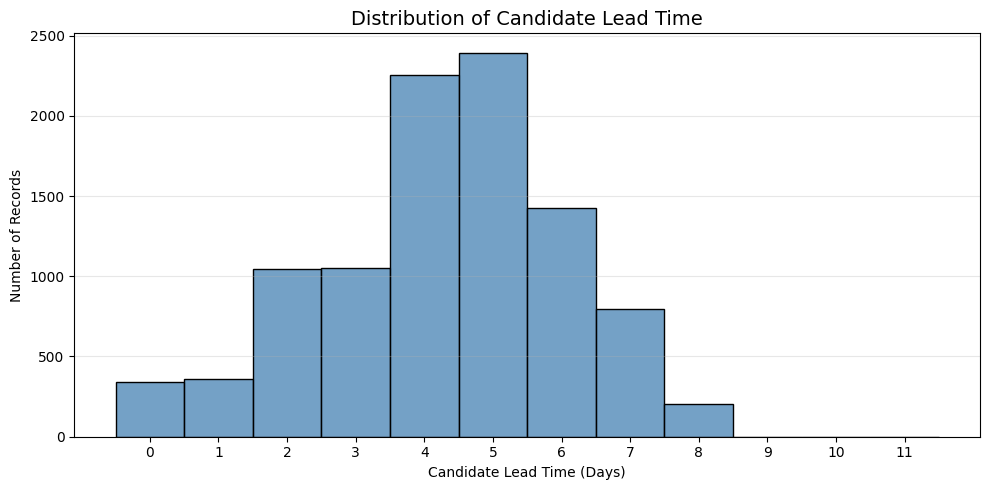

In [189]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_model,
    x="Candidate Lead Time",
    bins=range(0, 13),
    discrete=True,
    color="steelblue",
    edgecolor="black",
   )

plt.title("Distribution of Candidate Lead Time", fontsize=14)
plt.xlabel("Candidate Lead Time (Days)")
plt.ylabel("Number of Records")
plt.xticks(range(0, 12))
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [190]:
lead_time_by_mode = (
    df_model
    .groupby("Ship Mode")["Candidate Lead Time"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

print(lead_time_by_mode)

                count  mean  median  min  max
Ship Mode                                    
First Class      1494  2.55     3.0    1    5
Same Day          527  0.38     0.0    0    2
Second Class     1921  3.57     3.0    1    6
Standard Class   5939  5.31     5.0    3   11


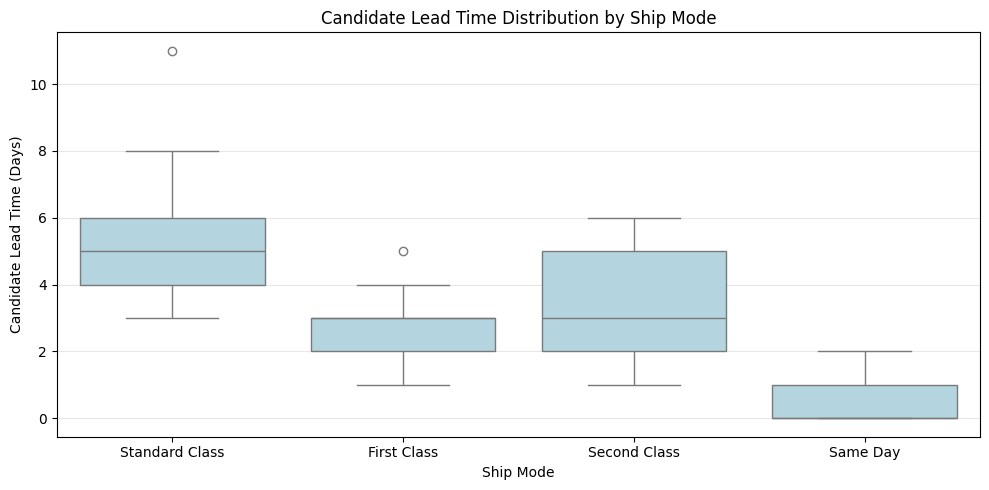

In [191]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df_model,
    x="Ship Mode",
    y="Candidate Lead Time",
    color="lightblue"
)

plt.title("Candidate Lead Time Distribution by Ship Mode")
plt.xlabel("Ship Mode")
plt.ylabel("Candidate Lead Time (Days)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [192]:
outlier_11 = df_model[
    df_model["Candidate Lead Time"] == 11
]

print(
    outlier_11[
        [
            "Order ID",
            "Order Date",
            "Ship Date",
            "Ship Mode",
            "Product Name",
            "Current Factory",
            "Candidate Lead Time"
        ]
    ].to_string(index=False)
)

                    Order ID Order Date  Ship Date      Ship Mode                   Product Name Current Factory  Candidate Lead Time
CA-2021-153623-CHO-SCR-58000 2024-11-24 28-05-2027 Standard Class Wonka Bar -Scrumdiddlyumptious   Lot's O' Nuts                   11


In [193]:
outlier_5 = df_model[
    (df_model["Ship Mode"] == "First Class") &
    (df_model["Candidate Lead Time"] == 5)
]

print(
    outlier_5[
        [
            "Order ID",
            "Order Date",
            "Ship Date",
            "Product Name",
            "Current Factory",
            "Candidate Lead Time"
        ]
    ].to_string(index=False)
)

                    Order ID Order Date  Ship Date              Product Name Current Factory  Candidate Lead Time
US-2021-156545-CHO-FUD-51000 2024-02-27 24-08-2026 Wonka Bar - Fudge Mallows   Lot's O' Nuts                    5


In [194]:
# Initial features for lead-time prediction
feature_columns = [
    "Ship Mode",
    "Product Name",
    "Current Factory",
    "Units",
    "Region",
    "Country/Region",
    "Order Month",
    "Order DayOfWeek"
]

# Separate input features and target
X = df_model[feature_columns].copy()

y = df_model["Candidate Lead Time"].copy()

print("Feature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

Feature dataset shape: (9881, 8)
Target dataset shape: (9881,)

Feature columns:
['Ship Mode', 'Product Name', 'Current Factory', 'Units', 'Region', 'Country/Region', 'Order Month', 'Order DayOfWeek']


In [195]:
print("Feature data types:\n")
print(X.dtypes)

print("\nCategorical columns:")
print(X.select_dtypes(include="object").columns.tolist())

print("\nNumerical columns:")
print(X.select_dtypes(include="number").columns.tolist())

Feature data types:

Ship Mode          object
Product Name       object
Current Factory    object
Units               int64
Region             object
Country/Region     object
Order Month         int32
Order DayOfWeek     int32
dtype: object

Categorical columns:
['Ship Mode', 'Product Name', 'Current Factory', 'Region', 'Country/Region']

Numerical columns:
['Units', 'Order Month', 'Order DayOfWeek']


In [196]:
categorical_columns = X.select_dtypes(
    include="object"
).columns

for col in categorical_columns:
    print(f"\n{col}")
    print(X[col].value_counts())


Ship Mode
Ship Mode
Standard Class    5939
Second Class      1921
First Class       1494
Same Day           527
Name: count, dtype: int64

Product Name
Product Name
Wonka Bar - Milk Chocolate           2074
Wonka Bar -Scrumdiddlyumptious       1994
Wonka Bar - Triple Dazzle Caramel    1944
Wonka Bar - Fudge Mallows            1771
Wonka Bar - Nutty Crunch Surprise    1748
Wonka Gum                             120
Kazookles                              96
Lickable Wallpaper                     94
Laffy Taffy                            10
SweeTARTS                              10
Fizzy Lifting Drinks                    6
Nerds                                   4
Hair Toffee                             4
Everlasting Gobstopper                  3
Fun Dip                                 3
Name: count, dtype: int64

Current Factory
Current Factory
Lot's O' Nuts        5513
Wicked Choccy's      4018
Secret Factory        217
The Other Factory     100
Sugar Shack            33
Name: count, dt

## model training


In [197]:
from sklearn.model_selection import GroupShuffleSplit

# Create a group-based data splitter
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

# Split using Order ID as the group
train_idx, test_idx = next(
    splitter.split(
        X,
        y,
        groups=df_model["Order ID"]
    )
)

# Create training and testing datasets
X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

# Display dataset sizes
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

# Check for Order ID overlap
train_orders = set(df_model.iloc[train_idx]["Order ID"])
test_orders = set(df_model.iloc[test_idx]["Order ID"])

print("Common Order IDs:", len(train_orders & test_orders))

Training features: (7887, 8)
Testing features: (1994, 8)
Common Order IDs: 0


In [198]:
print("Training target distribution:")
print(y_train.describe().round(2))

print("\nTesting target distribution:")
print(y_test.describe().round(2))

Training target distribution:
count    7887.0
mean        4.3
std         1.8
min         0.0
25%         3.0
50%         4.0
75%         6.0
max        11.0
Name: Candidate Lead Time, dtype: float64

Testing target distribution:
count    1994.00
mean        4.28
std         1.76
min         0.00
25%         3.00
50%         4.00
75%         5.00
max         8.00
Name: Candidate Lead Time, dtype: float64


In [199]:
categorical_features = [
    "Ship Mode",
    "Product Name",
    "Current Factory",
    "Region",
    "Country/Region"
]

numerical_features = [
    "Units",
    "Order Month",
    "Order DayOfWeek"
]

print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)

Categorical features: ['Ship Mode', 'Product Name', 'Current Factory', 'Region', 'Country/Region']
Numerical features: ['Units', 'Order Month', 'Order DayOfWeek']


In [200]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    transformers=[(
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features),
        ("numerical",
            StandardScaler(),
            numerical_features)])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [201]:
# Learn the transformations from training data
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same transformations to testing data
X_test_processed = preprocessor.transform(X_test)

print("Training data shape:", X_train_processed.shape)
print("Testing data shape:", X_test_processed.shape)

Training data shape: (7887, 33)
Testing data shape: (1994, 33)


In [202]:
from scipy import sparse

# Check processed features
if sparse.issparse(X_train_processed):
    train_nan = np.isnan(X_train_processed.data).any()
else:
    train_nan = np.isnan(X_train_processed).any()

if sparse.issparse(X_test_processed):
    test_nan = np.isnan(X_test_processed.data).any()
else:
    test_nan = np.isnan(X_test_processed).any()

# Check target values
print("Training features contain NaN:", train_nan)
print("Testing features contain NaN:", test_nan)

print("Training target contains NaN:", y_train.isna().any())
print("Testing target contains NaN:", y_test.isna().any())

Training features contain NaN: False
Testing features contain NaN: False
Training target contains NaN: False
Testing target contains NaN: False


In [203]:
from sklearn.linear_model import LinearRegression

# Create the Linear Regression model
lr_model = LinearRegression()

# Train the model
lr_model.fit(X_train_processed, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [204]:
# Predict lead time for testing data
y_pred = lr_model.predict(X_test_processed)

# Display the first 10 predictions
print("Actual values:")
print(y_test.head(10).to_list())

print("\nPredicted values:")
print(y_pred[:10].round(2))

Actual values:
[5, 5, 3, 5, 3, 3, 3, 6, 4, 6]

Predicted values:
[5.26 5.2  3.55 5.18 3.51 3.53 2.47 5.21 2.49 5.19]


In [205]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Linear Regression Evaluation")
print("-----------------------------")
print("MAE:", round(mae, 3))
print("RMSE:", round(rmse, 3))
print("R² Score:", round(r2, 3))

Linear Regression Evaluation
-----------------------------
MAE: 0.895
RMSE: 1.075
R² Score: 0.629


In [206]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# 1. Define all models
models = {
    "Linear Regression": LinearRegression(),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=4,
        random_state=42,
        objective="reg:squarederror",
        n_jobs=-1
    )
}

# 2. Store evaluation results
results = []

# 3. Train and evaluate each model
for name, model in models.items():

    # Train model
    model.fit(X_train_processed, y_train)

    # Predict testing data
    predictions = model.predict(X_test_processed)

    # Calculate metrics
    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    # Store results
    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

# 4. Display comparison
results_df = pd.DataFrame(results)

print("MODEL PERFORMANCE COMPARISON")
display(results_df.round(3))

MODEL PERFORMANCE COMPARISON


,Model,MAE,RMSE,R2 Score
0,Linear Regression,0.895,1.075,0.629
1,Random Forest,0.940,1.183,0.550
2,XGBoost,0.883,1.070,0.632


In [207]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

# Create Gradient Boosting model
gb_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

# Train the model
gb_model.fit(X_train_processed, y_train)

# Predict testing data
gb_predictions = gb_model.predict(X_test_processed)

# Evaluate the model
gb_mae = mean_absolute_error(y_test, gb_predictions)
gb_rmse = np.sqrt(mean_squared_error(y_test, gb_predictions))
gb_r2 = r2_score(y_test, gb_predictions)

print("Gradient Boosting Evaluation")
print("----------------------------")
print("MAE:", round(gb_mae, 3))
print("RMSE:", round(gb_rmse, 3))
print("R² Score:", round(gb_r2, 3))

Gradient Boosting Evaluation
----------------------------
MAE: 0.888
RMSE: 1.071
R² Score: 0.631


In [208]:
year_target_summary = (
    df_model.groupby("Order ID Year")["Candidate Lead Time"]
    .agg(["count", "mean", "std", "min", "max"])
    .round(2)
)

display(year_target_summary)

,count,mean,std,min,max
Order ID Year,,,,,
2021,2002,4.07,1.68,0,11
2022,2061,4.07,1.73,0,8
2023,2542,3.96,1.79,0,7
2024,3276,4.83,1.78,0,8


In [209]:
# Compare Order ID Year distribution in training and testing sets

train_year_counts = (
    df_model.iloc[train_idx]["Order ID Year"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

test_year_counts = (
    df_model.iloc[test_idx]["Order ID Year"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

year_split_comparison = pd.DataFrame({
    "Training (%)": train_year_counts,
    "Testing (%)": test_year_counts
}).round(2)

display(year_split_comparison)

,Training (%),Testing (%)
Order ID Year,,
2021,19.99,21.31
2022,20.98,20.36
2023,25.88,25.13
2024,33.14,33.20


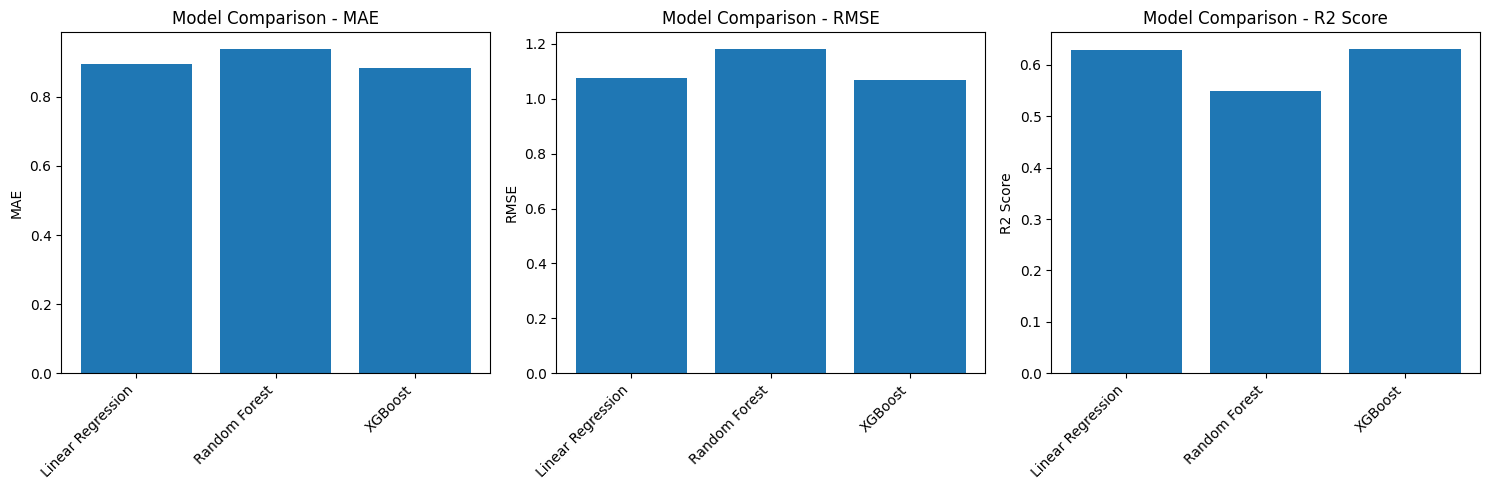

In [210]:
# Create comparison chart
metrics = ["MAE", "RMSE", "R2 Score"]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i, metric in enumerate(metrics):
    axes[i].bar(
        results_df["Model"],
        results_df[metric]
    )

    axes[i].set_title(f"Model Comparison - {metric}")
    axes[i].set_ylabel(metric)
    axes[i].tick_params(axis="x", rotation=45)

    for label in axes[i].get_xticklabels():
        label.set_ha("right")

plt.tight_layout()
plt.show()

In [211]:
# Add Gradient Boosting to the existing results
all_results = results_df.copy()

all_results = pd.concat(
    [
        all_results,
        pd.DataFrame([{
            "Model": "Gradient Boosting",
            "MAE": gb_mae,
            "RMSE": gb_rmse,
            "R2 Score": gb_r2
        }])
    ],
    ignore_index=True
)

display(all_results.round(3))

,Model,MAE,RMSE,R2 Score
0,Linear Regression,0.895,1.075,0.629
1,Random Forest,0.940,1.183,0.550
2,XGBoost,0.883,1.070,0.632
3,Gradient Boosting,0.888,1.071,0.631


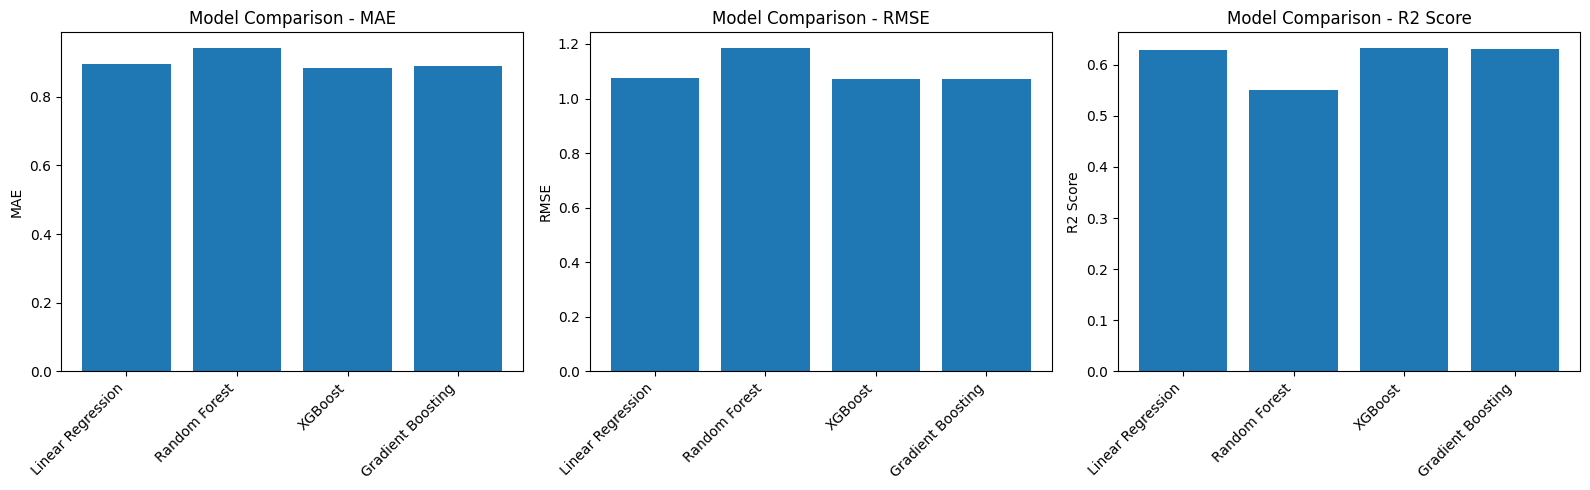

In [212]:
metrics = ["MAE", "RMSE", "R2 Score"]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for i, metric in enumerate(metrics):
    axes[i].bar(all_results["Model"], all_results[metric])
    axes[i].set_title(f"Model Comparison - {metric}")
    axes[i].set_ylabel(metric)
    axes[i].tick_params(axis="x", rotation=45)

    for label in axes[i].get_xticklabels():
        label.set_ha("right")

plt.tight_layout()
plt.show()

In [213]:
from sklearn.model_selection import GroupKFold

group_kfold = GroupKFold(n_splits=5)



In [214]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor

# Create preprocessing for each fold
cv_preprocessor = ColumnTransformer(
    transformers=[
        ("categorical",
         OneHotEncoder(handle_unknown="ignore"),
         categorical_features),

        ("numerical",
         StandardScaler(),
         numerical_features)
    ]
)

# Create model pipelines
cv_models = {
    "Linear Regression": Pipeline([
        ("preprocessor", cv_preprocessor),
        ("model", LinearRegression())
    ]),

    "Random Forest": Pipeline([
        ("preprocessor", cv_preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "XGBoost": Pipeline([
        ("preprocessor", cv_preprocessor),
        ("model", XGBRegressor(
            n_estimators=100,
            learning_rate=0.05,
            max_depth=4,
            random_state=42,
            objective="reg:squarederror",
            n_jobs=-1
        ))
    ]),

    "Gradient Boosting": Pipeline([
        ("preprocessor", cv_preprocessor),
        ("model", GradientBoostingRegressor(
            n_estimators=100,
            learning_rate=0.05,
            max_depth=3,
            random_state=42
        ))
    ])
}
print("All four cross-validation pipelines are ready!")

All four cross-validation pipelines are ready!


In [215]:
from sklearn.model_selection import cross_validate

# Get Order IDs belonging to the training set
train_groups = df_model.iloc[train_idx]["Order ID"]

# Store cross-validation results
cv_results = []

# Evaluate each model using 5-fold GroupKFold
for name, model in cv_models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        groups=train_groups,
        cv=group_kfold,
        scoring={
            "MAE": "neg_mean_absolute_error",
            "RMSE": "neg_root_mean_squared_error",
            "R2": "r2"
        },
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Mean MAE": -scores["test_MAE"].mean(),
        "Mean RMSE": -scores["test_RMSE"].mean(),
        "Mean R2": scores["test_R2"].mean()
    })

# Display results
cv_results_df = pd.DataFrame(cv_results)

display(cv_results_df.round(3))

,Model,Mean MAE,Mean RMSE,Mean R2
0,Linear Regression,0.933,1.106,0.622
1,Random Forest,0.954,1.181,0.569
2,XGBoost,0.917,1.095,0.629
3,Gradient Boosting,0.922,1.097,0.628


In [216]:
# Calculate standard deviation across five folds

cv_stability = []

for name, model in cv_models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        groups=train_groups,
        cv=group_kfold,
        scoring={
            "MAE": "neg_mean_absolute_error",
            "RMSE": "neg_root_mean_squared_error",
            "R2": "r2"
        },
        n_jobs=-1
    )

    cv_stability.append({
        "Model": name,
        "MAE Std": scores["test_MAE"].std(),
        "RMSE Std": scores["test_RMSE"].std(),
        "R2 Std": scores["test_R2"].std()
    })

cv_stability_df = pd.DataFrame(cv_stability)

display(cv_stability_df.round(3))

,Model,MAE Std,RMSE Std,R2 Std
0,Linear Regression,0.012,0.015,0.004
1,Random Forest,0.017,0.018,0.006
2,XGBoost,0.011,0.014,0.004
3,Gradient Boosting,0.011,0.014,0.003


In [217]:
from sklearn.model_selection import RandomizedSearchCV

xgb_pipeline = cv_models["XGBoost"]

param_grid = {
    "model__n_estimators": [100, 200, 300, 400],
    "model__max_depth": [2, 3, 4, 5, 6],
    "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "model__subsample": [0.7, 0.8, 0.9, 1.0],
    "model__colsample_bytree": [0.7, 0.8, 0.9, 1.0]
}

print("XGBoost tuning parameters are ready!")

XGBoost tuning parameters are ready!


In [218]:
# Create XGBoost model for tuning
xgb_pipeline = cv_models["XGBoost"]

# Configure randomized search
xgb_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=param_grid,
    n_iter=20,
    scoring="neg_mean_absolute_error",
    cv=group_kfold,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("XGBoost randomized search is configured!")

XGBoost randomized search is configured!


In [219]:
# Run randomized search using training data only
xgb_search.fit(
    X_train,
    y_train,
    groups=train_groups
)

print("XGBoost hyperparameter tuning completed!")

Fitting 5 folds for each of 20 candidates, totalling 100 fits
XGBoost hyperparameter tuning completed!


In [220]:
print("Best Parameters:")
print(xgb_search.best_params_)

print("\nBest Cross-Validation MAE:")
print(round(-xgb_search.best_score_, 3))

Best Parameters:
{'model__subsample': 0.9, 'model__n_estimators': 300, 'model__max_depth': 5, 'model__learning_rate': 0.03, 'model__colsample_bytree': 1.0}

Best Cross-Validation MAE:
0.909


In [221]:
# Get the best tuned XGBoost model
best_xgb_model = xgb_search.best_estimator_

# Predict using unseen test data
tuned_predictions = best_xgb_model.predict(X_test)

# Calculate evaluation metrics
tuned_mae = mean_absolute_error(y_test, tuned_predictions)
tuned_rmse = np.sqrt(mean_squared_error(y_test, tuned_predictions))
tuned_r2 = r2_score(y_test, tuned_predictions)

print("Tuned XGBoost Test Results")
print("--------------------------")
print("MAE:", round(tuned_mae, 3))
print("RMSE:", round(tuned_rmse, 3))
print("R2 Score:", round(tuned_r2, 3))

Tuned XGBoost Test Results
--------------------------
MAE: 0.881
RMSE: 1.081
R2 Score: 0.625


In [222]:
# Display all DataFrames currently available in the notebook
for name, value in globals().copy().items():
    if isinstance(value, pd.DataFrame):
        print(f"{name}: {value.shape}")

df: (10194, 22)
_2: (5, 18)
_7: (10, 2)
date_check: (4, 8)
_9: (10, 3)
_12: (2, 5)
_13: (4, 5)
_14: (10, 4)
_16: (4, 2)
_17: (4, 5)
_18: (20, 6)
_20: (10, 4)
_21: (20, 4)
ship_mode_check: (10194, 2)
_22: (4, 8)
_27: (8, 4)
_30: (4, 4)
_33: (4, 4)
df_clean: (10194, 35)
lead_time_check: (4, 4)
lead_time_year_check: (4, 8)
_38: (10194, 22)
factory_locations: (5, 3)
us_lookup: (631, 12)
test_lookup: (10, 12)
canada_lookup: (23, 12)
us_geo_lookup: (631, 3)
canada_geo_lookup: (23, 3)
postal_geo_lookup: (654, 3)
df_geo: (10194, 42)
missing_geo: (52, 2)
verification_df: (5, 2)
factory_summary: (5, 3)
product_baseline: (15, 6)
product_factory_distances: (15, 10)
scenario_df: (75, 9)
alternative_scenarios: (60, 9)
best_alternatives: (15, 9)
positive_opportunities: (11, 12)
distance_lead_corr: (2, 2)
ship_mode_summary: (4, 6)
X: (9881, 8)
X_train: (7887, 8)
X_test: (1994, 8)
lead_time_distribution: (4, 10)
X_distance: (10194, 5)
X_train_dist: (8155, 5)
X_test_dist: (2039, 5)
recommendation_summar

In [223]:
tables_to_check = [
    "best_alternatives",
    "positive_opportunities",
    "profit_recommendations",
    "priority_df",
    "review_df"
]

for name in tables_to_check:
    table = globals()[name]

    print(f"\n{'=' * 50}")
    print(f"TABLE: {name}")
    print("Shape:", table.shape)
    print("Columns:", table.columns.tolist())
    print(table.head(2).to_string(index=False))


TABLE: best_alternatives
Shape: (15, 9)
Columns: ['Product Name', 'Orders', 'Current Factory', 'Alternative Factory', 'Current Distance (km)', 'Alternative Distance (km)', 'Distance Saving (km)', 'Reduction (%)', 'Is Current Factory']
Product Name  Orders Current Factory Alternative Factory  Current Distance (km)  Alternative Distance (km)  Distance Saving (km)  Reduction (%)  Is Current Factory
       Nerds       4     Sugar Shack     Wicked Choccy's                1924.45                    1124.80                799.65          41.55               False
     Fun Dip       3     Sugar Shack      Secret Factory                1538.03                     828.52                709.51          46.13               False

TABLE: positive_opportunities
Shape: (11, 12)
Columns: ['Product Name', 'Orders', 'Current Factory', 'Alternative Factory', 'Current Distance (km)', 'Alternative Distance (km)', 'Distance Saving (km)', 'Reduction (%)', 'Is Current Factory', 'Record-km Saved', 'Current Re

In [224]:
print(
    review_df[
        ["Product Name", "Current Factory", "Alternative Factory",
         "Orders_scenario", "Priority Score", "Evidence Volume"]
    ].to_string(index=False)
)

                     Product Name Current Factory Alternative Factory  Orders_scenario  Priority Score      Evidence Volume
   Wonka Bar -Scrumdiddlyumptious   Lot's O' Nuts      Secret Factory             2064        0.652447 High-volume evidence
        Wonka Bar - Fudge Mallows   Lot's O' Nuts      Secret Factory             1818        0.656117 High-volume evidence
Wonka Bar - Nutty Crunch Surprise   Lot's O' Nuts      Secret Factory             1810        0.673881 High-volume evidence
Wonka Bar - Triple Dazzle Caramel Wicked Choccy's      Secret Factory             2015        0.529246 High-volume evidence
       Wonka Bar - Milk Chocolate Wicked Choccy's      Secret Factory             2137        0.519174 High-volume evidence
                      Laffy Taffy     Sugar Shack     Wicked Choccy's               10        0.660463  Low-volume evidence
                        SweeTARTS     Sugar Shack      Secret Factory               10        0.531946  Low-volume evidence
        

In [225]:
# Create a separate copy for final recommendations
final_recommendations = review_df.copy()

# Add feasibility status columns
final_recommendations["Geographic Benefit"] = "Identified"
final_recommendations["Profit Assessment"] = "Estimated"
final_recommendations["Manufacturing Compatibility"] = "Pending validation"
final_recommendations["Factory Capacity"] = "Pending validation"
final_recommendations["Actual Logistics Benefit"] = "Pending validation"

# Set the recommendation status
final_recommendations["Recommendation Status"] = "Proposed - Requires Review"

print("Final recommendation table created!")
print("Shape:", final_recommendations.shape)

display(final_recommendations.head())

Final recommendation table created!
Shape: (11, 30)


,Product Name,Orders_scenario,Current Factory,Alternative Factory,Current Distance (km),Alternative Distance (km),Distance Saving (km),Reduction (%),Is Current Factory,Record-km Saved,...,Distance Score,Margin Score,Priority Score,Evidence Volume,Geographic Benefit,Profit Assessment,Manufacturing Compatibility,Factory Capacity,Actual Logistics Benefit,Recommendation Status
0,Wonka Bar -Scrumdiddlyumptious,2064,Lot's O' Nuts,Secret Factory,2142.33,1539.00,603.33,28.16,False,1245273.12,...,0.610449,0.694444,0.652447,High-volume evidence,Identified,Estimated,Pending validation,Pending validation,Pending validation,Proposed - Requires Review
1,Wonka Bar - Fudge Mallows,1818,Lot's O' Nuts,Secret Factory,2165.81,1520.84,644.97,29.78,False,1172555.46,...,0.645567,0.666667,0.656117,High-volume evidence,Identified,Estimated,Pending validation,Pending validation,Pending validation,Proposed - Requires Review
2,Wonka Bar - Nutty Crunch Surprise,1810,Lot's O' Nuts,Secret Factory,2125.59,1503.62,621.97,29.26,False,1125765.70,...,0.634294,0.713467,0.673881,High-volume evidence,Identified,Estimated,Pending validation,Pending validation,Pending validation,Proposed - Requires Review
3,Wonka Bar - Triple Dazzle Caramel,2015,Wicked Choccy's,Secret Factory,1885.19,1532.84,352.35,18.69,False,709985.25,...,0.405159,0.653333,0.529246,High-volume evidence,Identified,Estimated,Pending validation,Pending validation,Pending validation,Proposed - Requires Review
4,Wonka Bar - Milk Chocolate,2137,Wicked Choccy's,Secret Factory,1843.82,1512.78,331.04,17.95,False,707432.48,...,0.389118,0.649231,0.519174,High-volume evidence,Identified,Estimated,Pending validation,Pending validation,Pending validation,Proposed - Requires Review


In [228]:
# Move one level up from notebook to project root
project_root = Path.cwd().parent

# Create the correct processed data folder
output_dir = project_root / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

# Save recommendations
output_file = output_dir / "final_recommendations.csv"

final_recommendations.to_csv(output_file, index=False)

print("Saved successfully!")
print("File location:", output_file.resolve())
print("File exists:", output_file.exists())

Saved successfully!
File location: C:\Users\INFANT JESUS\OneDrive\Desktop\Nassau-Candy-Optimization\data\processed\final_recommendations.csv
File exists: True


In [229]:
# Train the selected untuned XGBoost pipeline

final_xgb_pipeline = cv_models["XGBoost"]

final_xgb_pipeline.fit(X_train, y_train)

print("Final XGBoost pipeline trained successfully!")

Final XGBoost pipeline trained successfully!


In [230]:
import joblib
from pathlib import Path

# Find the main project folder
project_root = Path.cwd().parent

# Create models folder
models_dir = project_root / "models"
models_dir.mkdir(parents=True, exist_ok=True)

# Save the complete preprocessing + XGBoost pipeline
model_path = models_dir / "xgboost_pipeline.joblib"

joblib.dump(final_xgb_pipeline, model_path)

print("Model saved successfully!")
print("Location:", model_path)

Model saved successfully!
Location: c:\Users\INFANT JESUS\OneDrive\Desktop\Nassau-Candy-Optimization\models\xgboost_pipeline.joblib


In [227]:
from pathlib import Path

print("Notebook working directory:")
print(Path.cwd())

print("\nDoes data folder exist?")
print(Path("data").exists())

Notebook working directory:
c:\Users\INFANT JESUS\OneDrive\Desktop\Nassau-Candy-Optimization\notebook

Does data folder exist?
True


In [232]:
for col in feature_columns:
    print(f"\n{col}:")
    print(df_model[col].dropna().unique().tolist()[:20])


Ship Mode:
['Standard Class', 'First Class', 'Second Class', 'Same Day']

Product Name:
['Wonka Bar - Milk Chocolate', 'Wonka Bar - Triple Dazzle Caramel', 'Wonka Bar - Nutty Crunch Surprise', 'Wonka Bar -Scrumdiddlyumptious', 'Wonka Bar - Fudge Mallows', 'Wonka Gum', 'Kazookles', 'Lickable Wallpaper', 'Fizzy Lifting Drinks', 'Laffy Taffy', 'SweeTARTS', 'Nerds', 'Hair Toffee', 'Everlasting Gobstopper', 'Fun Dip']

Current Factory:
["Wicked Choccy's", "Lot's O' Nuts", 'Secret Factory', 'The Other Factory', 'Sugar Shack']

Units:
[2, 3, 9, 4, 1, 7, 6, 5, 10, 8, 13, 14, 12, 11]

Region:
['Interior', 'Atlantic', 'Gulf', 'Pacific']

Country/Region:
['United States', 'Canada']

Order Month:
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]

Order DayOfWeek:
[2, 3, 4, 5, 6, 1, 0]
